# Rn-222 Alpha Background — Master Analysis Notebook

Self-contained end-to-end pipeline for the XENONnT SR3 commissioning Rn-222 analysis.

**Sections**

0. Configuration
1. Load raw alpha peaks (concat multiple inputs)
2. Initial visualisation
3. Selection (pre-correction quality cuts)
4. Corrections 1/2/3 (per partition)
5. Fiducial volume cut
6. Save corrected events
7. Run list (straxen)
8. Per-partition fit
9. Per-run fit (fitted-mu / yield trend only)
10. M2 rate extraction
11. N_BINS uniform time-bin rate
12. Trend plots + Po/Rn ratios

Algorithm bodies are copied verbatim from the original notebooks
(`rn222_pp_corr_s1only`, `rn222_fit_test_0727`, `rn222_s1only-analysis-new`,
`plot_full_rates`). Everything tunable lives in Section 0.

In [1]:
# ═══════════════════════════════════════════════════════════════
# IMPORTS & HELPERS
# ═══════════════════════════════════════════════════════════════
import sys
sys.path.insert(0, '/home/jietang/xenon_plot_style')
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.dates as mdates
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from datetime import datetime, timezone
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 15)
pd.set_option('display.expand_frame_repr', False)

def safe_tight(fig=None):
    try: (fig or plt).tight_layout()
    except Exception: pass

def exp_bump_model(x, a, b, c, d, e):
    return a * np.exp((x + b) / c) * (1 - np.exp((x + b) / d)) + e

def polynomial(x, *coeffs):
    return sum(c * x**i for i, c in enumerate(coeffs))

def linear_func(x, a, b):
    return a * x + b

print('Setup complete.')

Setup complete.


---
## 0. Configuration

Split into independent blocks — edit / run each one separately.

### 0.1 Input data

In [2]:
# P6 analysis data: reduced parquet built by the REDUCE cell at the bottom of
# rn222_s1only-data_loader.ipynb (time / area / width / r2 cuts already applied).
INPUTS = [
    '/project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_s1s2_0903_0919_reduced.parquet',
]


### 0.2 Time partitions

Boundaries are contiguous (no gap). Edit dates / add partitions here.

In [3]:
def to_ts(date_str):
    return pd.Timestamp(date_str, tz='UTC').timestamp()

PARTITIONS = [
    ('P1: OLD Q5',               to_ts('2026-05-01'), to_ts('2026-05-11')),
    ('P2: ST707, Q5 removed',    to_ts('2026-05-11'), to_ts('2026-05-26')),
    ('P3: ST707, Q5 Rn cleaned', to_ts('2026-05-26'), to_ts('2026-06-12')),
    ('P4: FRESH Q5',             to_ts('2026-06-12'), to_ts('2026-07-08')),
    ('P5a: 0715-0725', to_ts('2026-07-15'),        to_ts('2026-07-25 13:00')),
    ('P5b: 0725-0808', to_ts('2026-07-25 13:00'),  to_ts('2026-08-08 13:00')),
    ('P5c: 0808-0822', to_ts('2026-08-08 13:00'),  to_ts('2026-08-22 13:00')),
    ('P5d: 0822-0831', to_ts('2026-08-22 13:00'),  to_ts('2026-08-31 13:00')),
    ('P5e: 0831-0903', to_ts('2026-08-31 13:00'), to_ts('2026-09-03')),
    ('P6: 0903-0920',  to_ts('2026-09-03'),       to_ts('2026-09-20')),
]

def assign_partition(start_s):
    for name, t0, t1 in PARTITIONS:
        if t0 <= start_s < t1:
            return name
    return None


### 0.3 Peaks & rate constants

In [4]:
# ---- Fit components: ONE PEAK PER LINE. Comment a line (#) to drop that peak. ----
# tuple: (name, Q [MeV], mu0, (mu_lo, mu_hi), sig0, (sig_lo, sig_hi))
FIT_PEAKS = [
    ('Rn-222', 5.590, 51000, (49500, 53500),  800, (300, 2000)),
    ('Po-218', 6.115, 56000, (54500, 59000),  900, (300, 2000)),
#    ('Rn-220', 6.288, 58500, (57000, 59500),  800, (250, 2000)),
#    ('Po-216', 6.778, 63000, (61000, 65000),  900, (250, 2000)),
    ('Po-214', 7.834, 72000, (69000, 75000), 1100, (300, 2500)),
]

FIT_COMPONENTS    = [p[0] for p in FIT_PEAKS]
FIT_ENERGIES      = np.array([p[1] for p in FIT_PEAKS])
N_PEAKS           = len(FIT_COMPONENTS)
FIT_COMPONENT_CFG = {p[0]: {'mu0': p[2], 'mu_b': p[3], 'sig0': p[4], 'sig_b': p[5]}
                     for p in FIT_PEAKS}
E_RN222 = {p[0]: p[1] for p in FIT_PEAKS}.get('Rn-222', 5.590)

# ---- Signal peaks used for the RATE (must be present in FIT_PEAKS) ----
SIGNAL_NAMES = ['Rn-222', 'Po-218', 'Po-214']
SIGNAL_IDX   = [FIT_COMPONENTS.index(s) for s in SIGNAL_NAMES]

# ---- Rate constants ----
FMASS   = 3660.0    # fiducial mass [kg]
N_SIGMA = 2.0       # counting window half-width (x sigma)

print('Fit components:', FIT_COMPONENTS)
print('Signal peaks  :', SIGNAL_NAMES, '-> idx', SIGNAL_IDX)
print('FMASS=%.0f kg, N_SIGMA=%.1f' % (FMASS, N_SIGMA))


Fit components: ['Rn-222', 'Po-218', 'Po-214']
Signal peaks  : ['Rn-222', 'Po-218', 'Po-214'] -> idx [0, 1, 2]
FMASS=3660 kg, N_SIGMA=2.0


### Plot helpers — partition / event vlines

In [5]:
# PARTITION & EVENT VLINE HELPERS

def add_partition_vlines(ax, y_frac=0.95):
    """Black lines at the CURRENT partition boundaries (auto from PARTITIONS)."""
    for name, t0, t1 in PARTITIONS[1:]:
        dt = datetime.fromtimestamp(t0, tz=timezone.utc)
        ax.axvline(x=dt, color='black', ls='-', lw=1.0, alpha=0.35)
        _, y_hi = ax.get_ylim()
        ax.text(dt, y_hi * y_frac, name.split(':')[0], fontsize=6, color='black',
                rotation=90, va='top', ha='right', alpha=0.7)

def add_event_vlines(ax, y_frac=0.85):
    """No event lines in the main workflow (see Backup section for the annotated plot)."""
    return

print('add_partition_vlines() [current partitions] + add_event_vlines() [disabled] defined.')


add_partition_vlines() [current partitions] + add_event_vlines() [disabled] defined.


---
## 1. Load data

Loads every entry in `INPUTS`, then applies
the time cut and the time-partition assignment.

### 1.1 Load raw alpha peaks

In [6]:
# ===============================================================
# LOAD PRE-SAVED DATA
# ===============================================================
# INPUTS is a list of parquet / pickle paths. The P6 parquet comes from
# rn222_s1only-data_loader.ipynb and keeps every loader column; only the
# subset used downstream is read here (memory-safe).
#
# NOTE: unlike the old reduced parquet, the P6 file is NOT pre-filtered.
# The width / r2 cuts in Section 3 still apply.

import pyarrow.parquet as pq

PARQUET_COLUMNS = ['time', 'area', 'area_fraction_top', 'range_50p_area',
                   'r2', 'x', 'y', 'run_name']

frames = []
for path in INPUTS:
    if str(path).endswith('.parquet'):
        available = set(pq.ParquetFile(path).schema_arrow.names)
        cols = [c for c in PARQUET_COLUMNS if c in available]
        d = pd.read_parquet(path, columns=cols)
        if 'run_name' in d.columns:
            d['run_name'] = d['run_name'].astype('category')
    else:
        d = pd.read_pickle(path).copy()
    print('Loaded %12d events  <- %s' % (len(d), path))
    print('  memory: %.2f GB' % (d.memory_usage(deep=True).sum()/1e9))
    frames.append(d)

df = pd.concat(frames, ignore_index=True, sort=False)
print('\nTotal: %d events (before time cut)' % len(df))
print('Time range: %s -> %s UTC' % (
    datetime.fromtimestamp(df['time'].min()/1e9, tz=timezone.utc).strftime('%Y-%m-%d %H:%M'),
    datetime.fromtimestamp(df['time'].max()/1e9, tz=timezone.utc).strftime('%Y-%m-%d %H:%M')))


Loaded       583688 events  <- /project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_s1s2_0903_0919_reduced.parquet
  memory: 0.02 GB

Total: 583688 events (before time cut)
Time range: 2026-09-03 14:53 -> 2026-09-19 19:39 UTC


### 1.2 Date check & cutoff

In [7]:
# ===============================================================
# P6 TIME CUT  (keep events at/after 2026-09-03)
# ===============================================================
CUTOFF_DATE = '2026-09-03'
cutoff_dt = datetime.strptime(CUTOFF_DATE, '%Y-%m-%d').replace(tzinfo=timezone.utc)
cutoff_ns = int(cutoff_dt.timestamp() * 1e9)

m_time = df['time'] >= cutoff_ns
df = df[m_time].copy().reset_index(drop=True)
df_peaks = df

print(f'After P6 time cut (>= {cutoff_dt.strftime("%Y-%m-%d")}): {len(df):,} events')
print(f'Columns: {list(df.columns)}')
print(f'Run range: {df["run_name"].astype(str).min()} - {df["run_name"].astype(str).max()}')
print(f'  Number of runs: {df["run_name"].nunique()}')


After P6 time cut (>= 2026-09-03): 583,688 events
Columns: ['time', 'area', 'area_fraction_top', 'range_50p_area', 'r2', 'x', 'y', 'run_name']
Run range: 086409 - 087192
  Number of runs: 404


### 1.3 Assign time partitions

In [8]:
# ===============================================================
# ASSIGN TIME PARTITIONS  (boundaries live in section 0.2)
# ===============================================================

df['partition'] = df['time'].apply(lambda t: assign_partition(t / 1e9))

# ---- auto-drop partitions with no data ----
present = set(df['partition'].dropna().unique())
empty = [p[0] for p in PARTITIONS if p[0] not in present]
if empty:
    print('Auto-dropping empty partitions:', empty)
    PARTITIONS[:] = [p for p in PARTITIONS if p[0] in present]
else:
    print('All %d partitions have data.' % len(PARTITIONS))

df_peaks = df

print('Events per partition:')
print(df['partition'].value_counts().sort_index())


Auto-dropping empty partitions: ['P1: OLD Q5', 'P2: ST707, Q5 removed', 'P3: ST707, Q5 Rn cleaned', 'P4: FRESH Q5', 'P5a: 0715-0725', 'P5b: 0725-0808', 'P5c: 0808-0822', 'P5d: 0822-0831', 'P5e: 0831-0903']
Events per partition:
partition
P6: 0903-0920    583688
Name: count, dtype: int64


---
## 2. Initial visualisation

6-panel overview + area-vs-width + zoomed area-vs-AFT (before any cut).

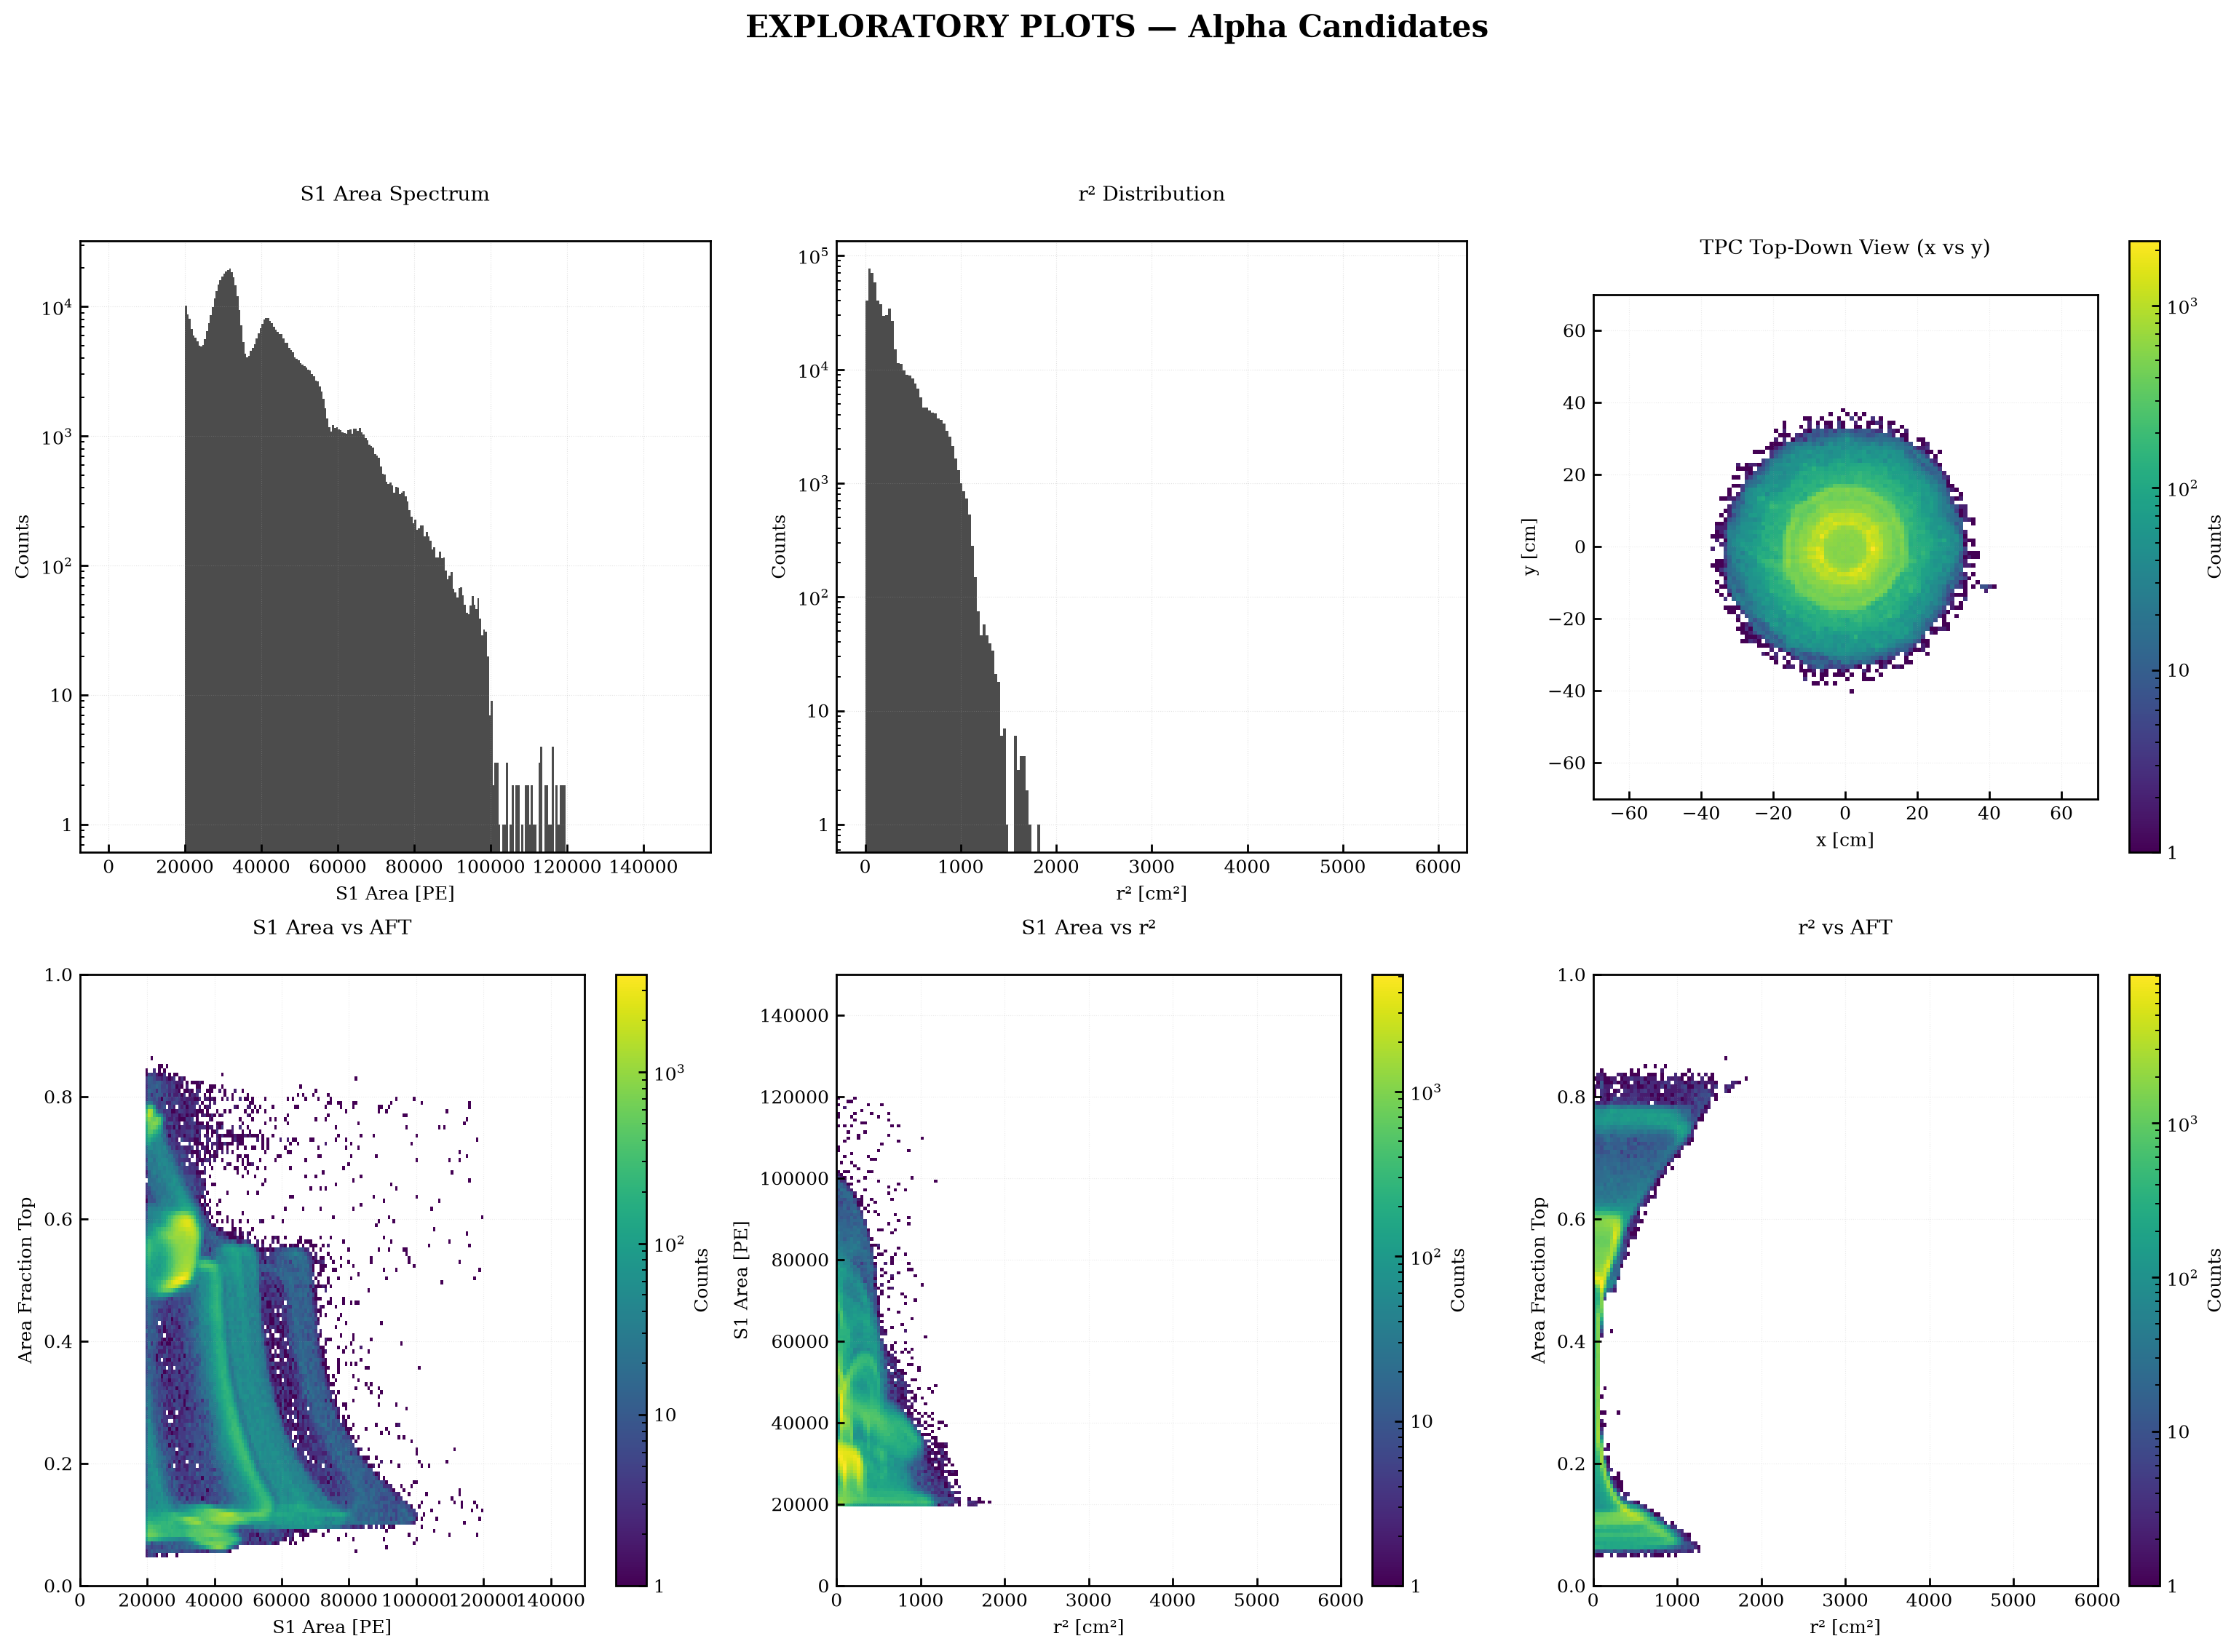

In [9]:
# ═══════════════════════════════════════════════════════════════
# 6-PANEL EXPLORATORY PLOTS
# ═══════════════════════════════════════════════════════════════

d = df_peaks

fig, axes = plt.subplots(2, 3, figsize=(19, 12))

# ── [0,0] S1 area 1D histogram ──
ax = axes[0, 0]
ax.hist(d['area'], bins=300, range=[0, 150e3],
        color='black', alpha=0.7)
ax.set_xlabel('S1 Area [PE]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('S1 Area Spectrum', pad=20)
ax.grid(True, alpha=0.3)

# ── [0,1] r² 1D histogram ──
ax = axes[0, 1]
if 'r2' in d.columns:
    ax.hist(d['r2'].dropna(), bins=200, range=[0, 6e3],
            color='black', alpha=0.7)
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('r² Distribution', pad=20)
ax.grid(True, alpha=0.3)

# ── [0,2] x vs y (top-down view) ──
ax = axes[0, 2]
if 'x' in d.columns and 'y' in d.columns:
    mask_xy = d['x'].notna() & d['y'].notna()
    h = ax.hist2d(d.loc[mask_xy, 'x'], d.loc[mask_xy, 'y'],
                  bins=[120, 120], range=[[-70, 70], [-70, 70]],
                  cmin=1, norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('x [cm]')
ax.set_ylabel('y [cm]')
ax.set_title('TPC Top-Down View (x vs y)', pad=20)
ax.set_aspect('equal')
ax.grid(True, alpha=0.2)

# ── [1,0] S1 Area vs AFT ──
ax = axes[1, 0]
h = ax.hist2d(d['area'], d['area_fraction_top'], bins=[200, 150],
              range=[[0, 150e3], [0, 1.0]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('S1 Area [PE]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('S1 Area vs AFT', pad=20)
ax.grid(True, alpha=0.2)

# ── [1,1] S1 Area vs r² ──
ax = axes[1, 1]
if 'r2' in d.columns:
    mask_r2 = d['r2'].notna()
    h = ax.hist2d(d.loc[mask_r2, 'r2'], d.loc[mask_r2, 'area'],
                  bins=[150, 200], range=[[0, 6e3], [0, 150e3]],
                  cmin=1, norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('S1 Area [PE]')
ax.set_title('S1 Area vs r²', pad=20)
ax.grid(True, alpha=0.2)

# ── [1,2] r² vs AFT ──
ax = axes[1, 2]
if 'r2' in d.columns:
    mask_r2 = d['r2'].notna()
    h = ax.hist2d(d.loc[mask_r2, 'r2'], d.loc[mask_r2, 'area_fraction_top'],
                  bins=[150, 150], range=[[0, 6e3], [0, 1.0]],
                  cmin=1, norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('r² vs AFT', pad=20)
ax.grid(True, alpha=0.2)

plt.suptitle('EXPLORATORY PLOTS — Alpha Candidates',
             fontsize=15, fontweight='bold', y=1.01)
safe_tight(fig)
plt.show()

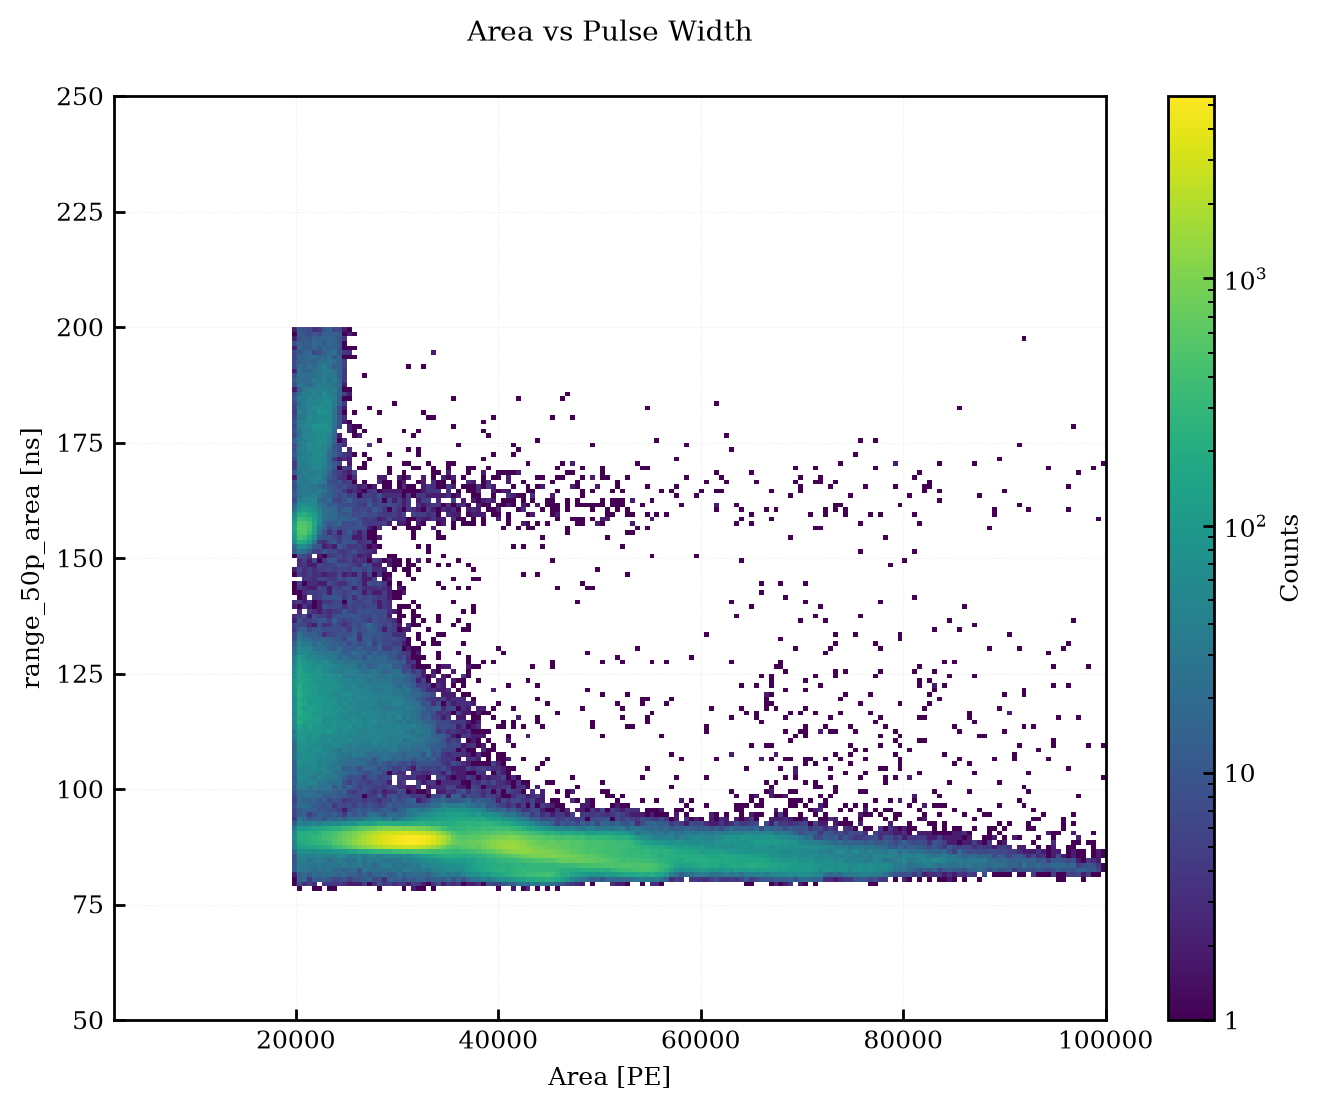

In [10]:
# ═══════════════════════════════════════════════════════════════
# AREA vs WIDTH — verify alpha band separation
# ═══════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(8, 6))
h = ax.hist2d(
    df_peaks['area'], df_peaks['range_50p_area'],
    bins=[200, 200], range=[[2e3, 100e3], [50, 250]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('Area [PE]')
ax.set_ylabel('range_50p_area [ns]')
ax.set_title('Area vs Pulse Width', pad=20)
ax.grid(True, alpha=0.2)
safe_tight(fig)
plt.show()

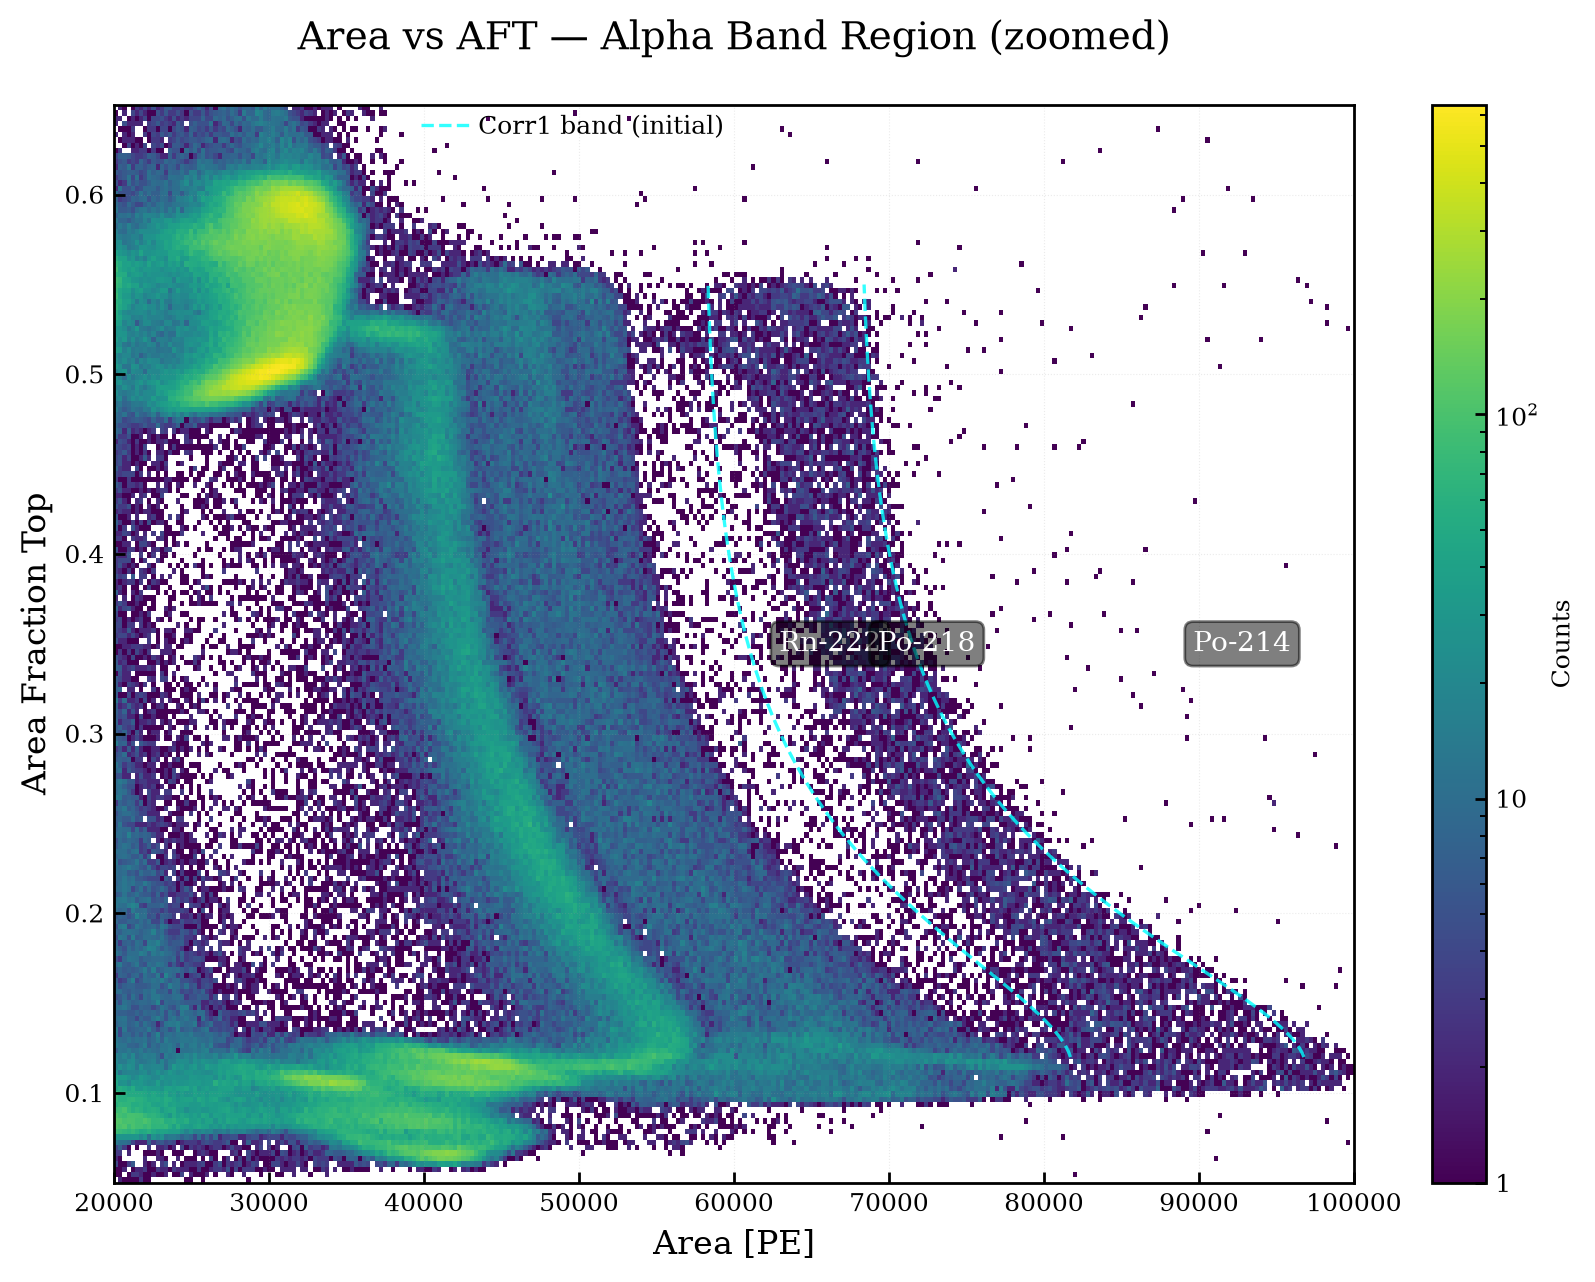

In [11]:
# ═══════════════════════════════════════════════════════════════
# ZOOMED AREA vs AFT — alpha band region
# ═══════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(10, 7))
h = ax.hist2d(
    df_peaks['area'], df_peaks['area_fraction_top'],
    bins=[300, 200], range=[[20e3, 100e3], [0.05, 0.65]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
cbar = plt.colorbar(h[3], ax=ax, label='Counts')

# Correction 1 initial band (same numbers as _CORR1_DEFAULT); labels sit on its CL
_RN_UPPER = [8.86e+04, -0.0600, -0.0900, -0.0600, 68000]
_RN_LOWER = [7.30e+04, -0.0600, -0.0900, -0.0600, 58000]
_aft_fine = np.linspace(0.12, 0.55, 300)
ax.plot(exp_bump_model(_aft_fine, *_RN_UPPER), _aft_fine, '--',
        color='cyan', lw=1.2, alpha=0.8, label='Corr1 band (initial)')
ax.plot(exp_bump_model(_aft_fine, *_RN_LOWER), _aft_fine, '--',
        color='cyan', lw=1.2, alpha=0.8)

# Isotope labels: corr1 centreline at AFT_LABEL, scaled by alpha energy
AFT_LABEL = 0.35
_rn_center = 0.5 * (exp_bump_model(AFT_LABEL, *_RN_UPPER) +
                    exp_bump_model(AFT_LABEL, *_RN_LOWER))
_E = {'Rn-222': 5.590, 'Po-218': 6.115, 'Po-214': 7.834}
for _name, _e in _E.items():
    _x = _rn_center * _e / _E['Rn-222']
    ax.annotate(_name, xy=(_x, AFT_LABEL), fontsize=10, color='white',
                ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.5))

ax.set_xlabel('Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('Area vs AFT — Alpha Band Region (zoomed)', fontsize=14, pad=20)
ax.legend(fontsize=9, loc='upper right')
ax.grid(True, alpha=0.2)
safe_tight(fig)
plt.show()


---
## 3. Selection (pre-correction quality cuts)

Width and r^2 cuts only; the AFT fiducial cut is **deferred** until after
the corrections so the fits have the full AFT range.

#### Parameters (edit here before running this section)

In [12]:
# Pre-correction quality cuts
WIDTH_MIN, WIDTH_MAX = 40.0, 200.0     # range_50p_area [ns]
R2_MAX = 3800.0                        # pre-correction r^2 [cm^2]

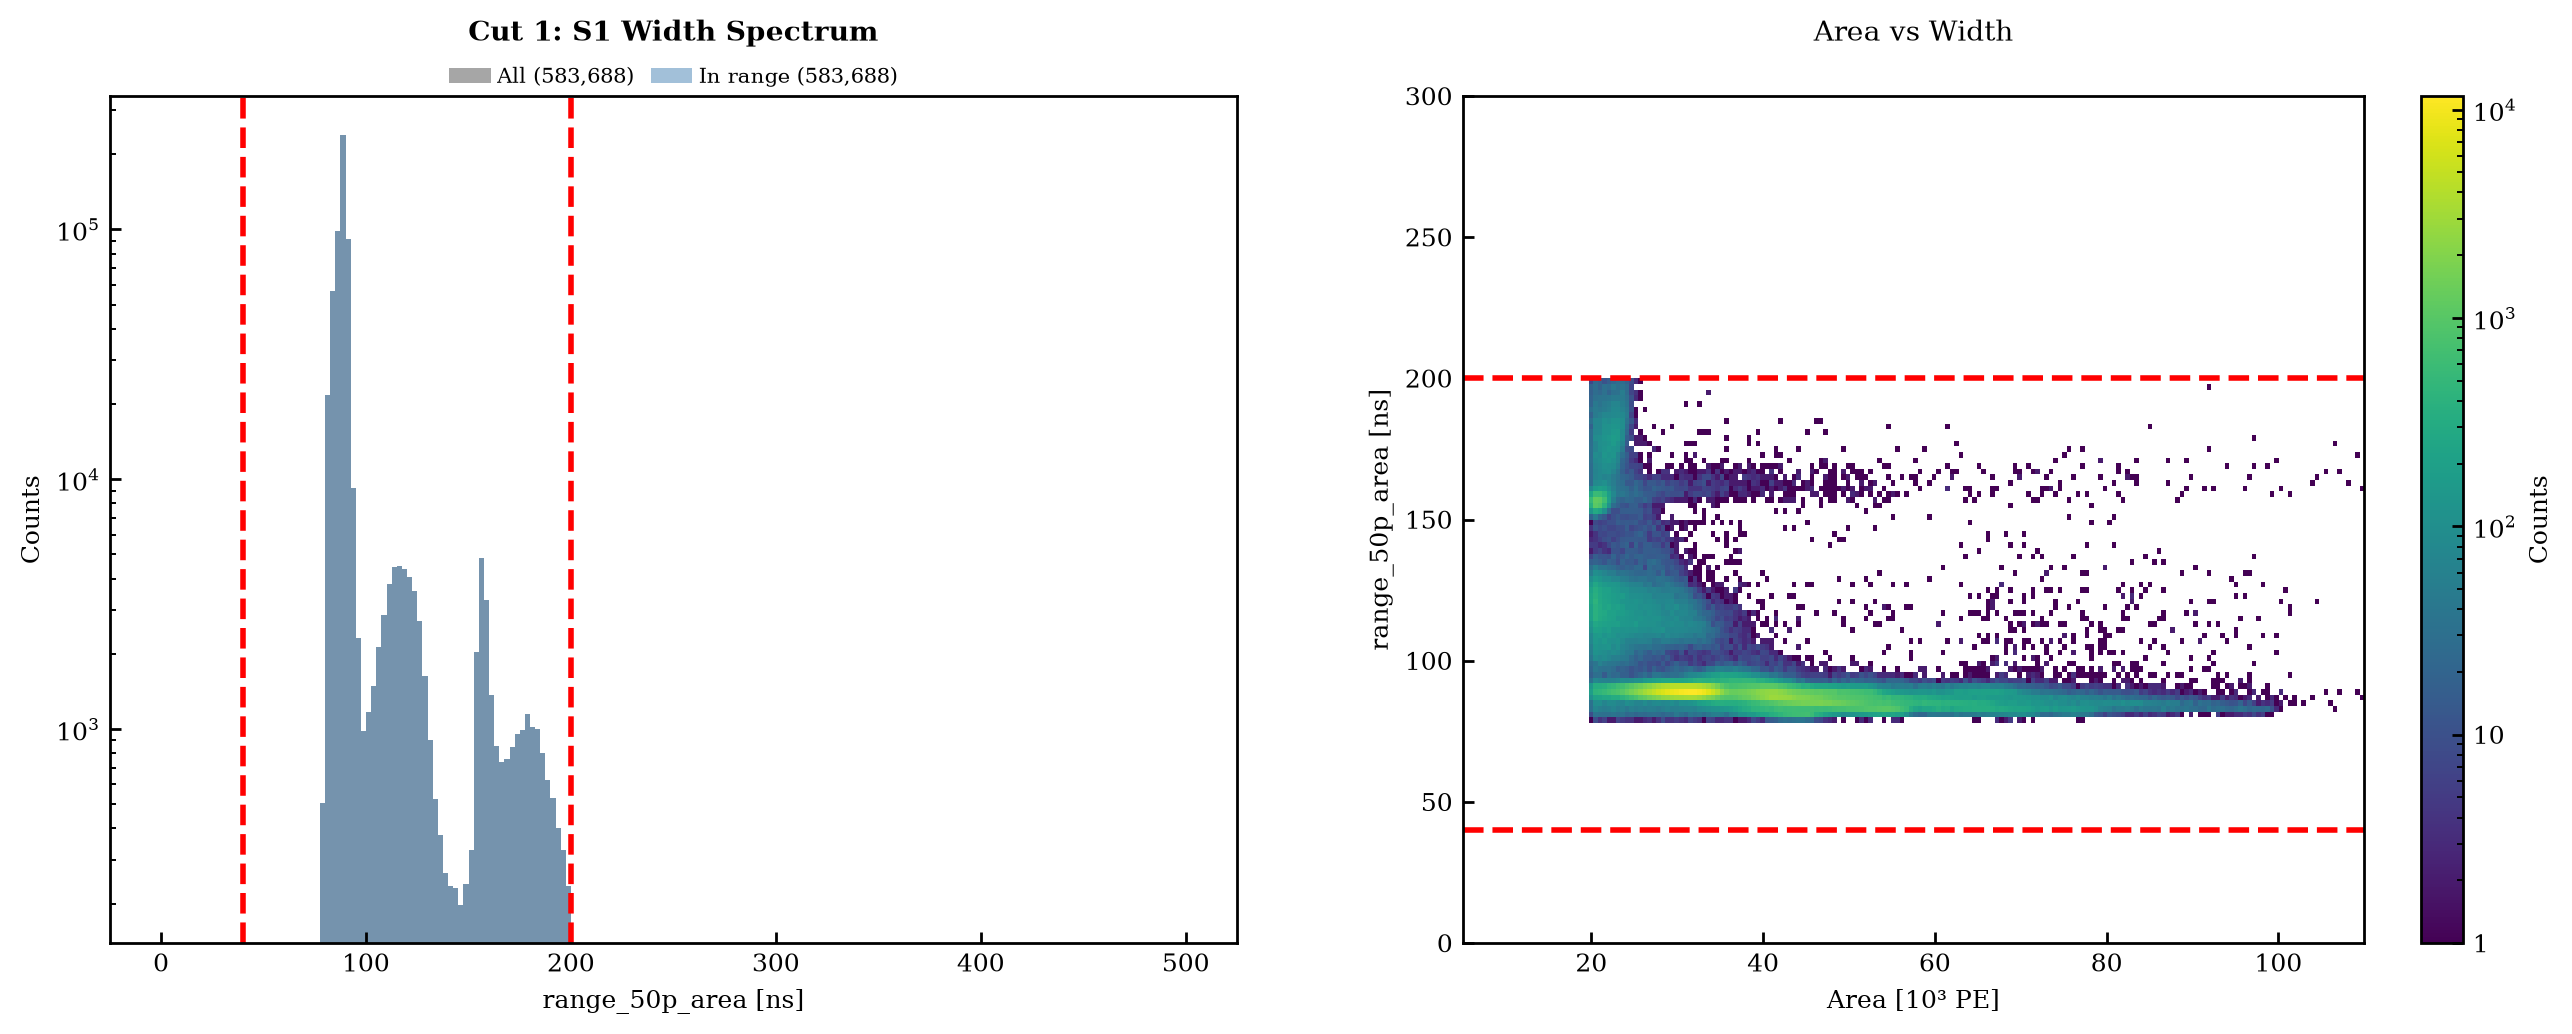

Cut 1 (Width [40.0, 200.0] ns): 583,688 / 583,688 pass (100.0%)


In [13]:
# ═══════════════════════════════════════════════════════════════
# CUT 1: Width Refinement — range_50p_area
# ═══════════════════════════════════════════════════════════════

# WIDTH_MIN / WIDTH_MAX from CONFIG

cut_masks = {}
d = df_peaks

m_width = (d['range_50p_area'] > WIDTH_MIN) & (d['range_50p_area'] < WIDTH_MAX)
cut_masks['width'] = m_width

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

ax1.hist(d['range_50p_area'], bins=200, range=[0, 500],
         color='gray', alpha=0.7, label=f'All ({len(d):,})')
ax1.hist(d.loc[m_width, 'range_50p_area'], bins=200, range=[0, 500],
         color='steelblue', alpha=0.5,
         label=f'In range ({m_width.sum():,})')
ax1.axvline(x=WIDTH_MIN, color='red', ls='--', lw=2)
ax1.axvline(x=WIDTH_MAX, color='red', ls='--', lw=2)
ax1.set_xlabel('range_50p_area [ns]')
ax1.set_ylabel('Counts')
ax1.set_yscale('log')
ax1.set_title('Cut 1: S1 Width Spectrum', fontweight='bold', pad=20)
ax1.legend(fontsize=7.5)

h = ax2.hist2d(d['area']/1e3, d['range_50p_area'],
               bins=[200, 150], range=[[5, 110], [0, 300]],
               cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
ax2.axhline(y=WIDTH_MIN, color='red', ls='--', lw=2)
ax2.axhline(y=WIDTH_MAX, color='red', ls='--', lw=2)
ax2.set_xlabel('Area [10³ PE]')
ax2.set_ylabel('range_50p_area [ns]')
ax2.set_title('Area vs Width', pad=20)
plt.colorbar(h[3], ax=ax2, label='Counts')

safe_tight(fig)
plt.show()

n_pass = m_width.sum()
print(f'Cut 1 (Width [{WIDTH_MIN}, {WIDTH_MAX}] ns): {n_pass:,} / {len(d):,} pass ({100*n_pass/len(d):.1f}%)')

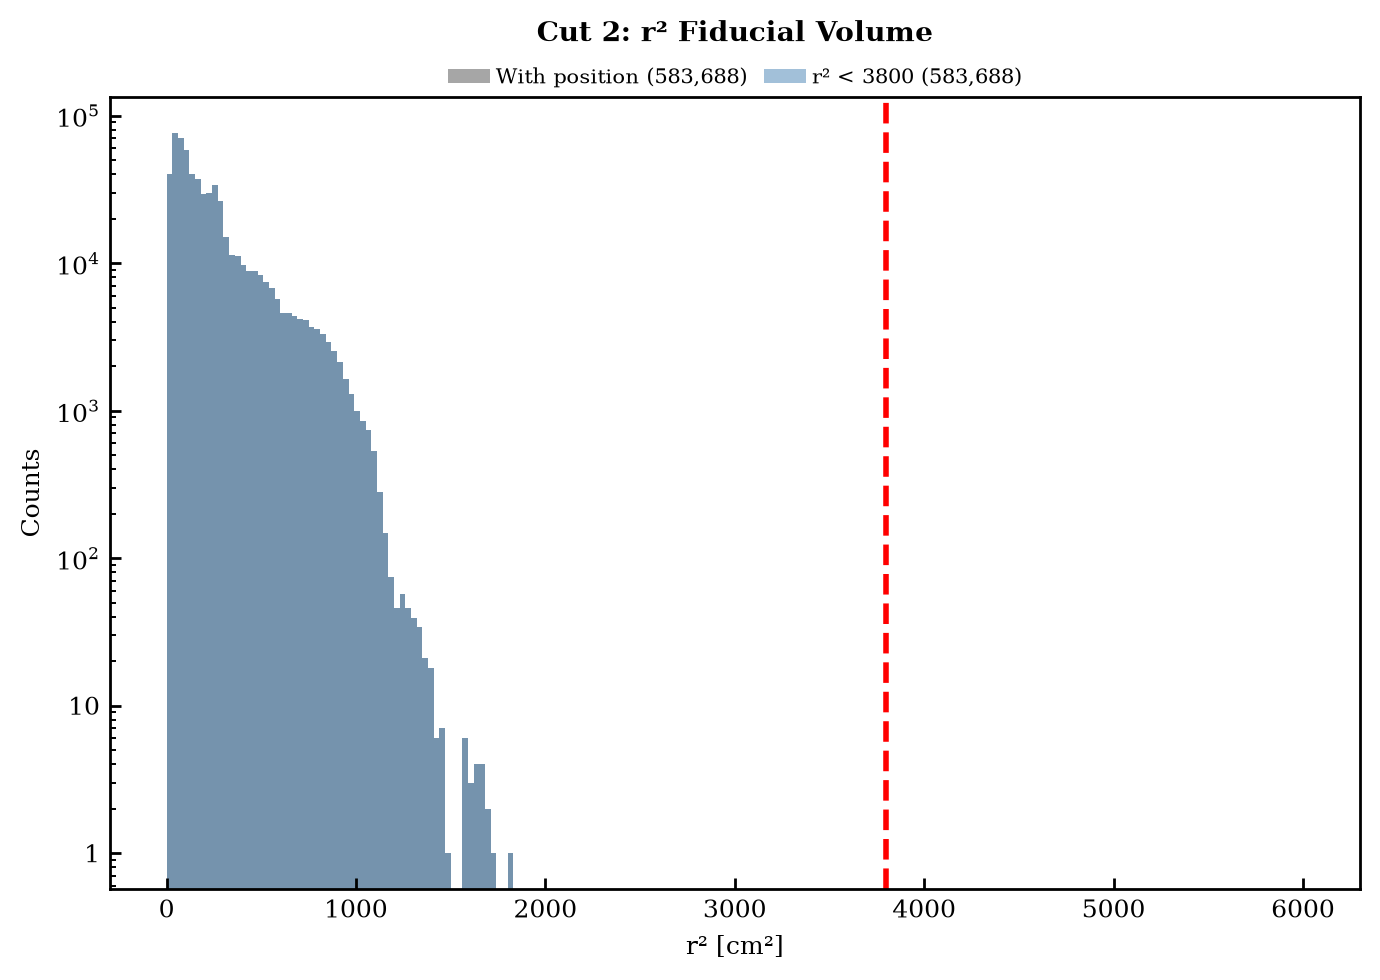

Cut 2 (r² FV < 3800 cm²): 583,688 / 583,688 pass (100.0%)


In [14]:
# ═══════════════════════════════════════════════════════════════
# CUT 2: r² Fiducial Volume — TPC wall rejection
# ═══════════════════════════════════════════════════════════════

# R2_MAX from CONFIG

d = df_peaks

if 'r2' in d.columns:
    has_pos = d['r2'].notna()
    m_r2 = (d['r2'] < R2_MAX).fillna(True)
    cut_masks['r2_fv'] = m_r2

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(d.loc[has_pos, 'r2'], bins=200, range=[0, 6000],
            color='gray', alpha=0.7, label=f'With position ({has_pos.sum():,})')
    ax.hist(d.loc[has_pos & m_r2, 'r2'], bins=200, range=[0, 6000],
            color='steelblue', alpha=0.5,
            label=f'r² < {R2_MAX:.0f} ({(has_pos & m_r2).sum():,})')
    ax.axvline(x=R2_MAX, color='red', ls='--', lw=2)
    ax.set_xlabel('r² [cm²]')
    ax.set_ylabel('Counts')
    ax.set_yscale('log')
    ax.set_title('Cut 2: r² Fiducial Volume', fontweight='bold', pad=20)
    ax.legend(fontsize=7.5)
    safe_tight(fig)
    plt.show()

    n_pass = m_r2.sum()
    print(f'Cut 2 (r² FV < {R2_MAX:.0f} cm²): {n_pass:,} / {len(d):,} pass ({100*n_pass/len(d):.1f}%)')
else:
    print('Cut 2 (r² FV): SKIPPED — no r² column available')
    cut_masks['r2_fv'] = pd.Series(True, index=d.index)

In [15]:
# ═══════════════════════════════════════════════════════════════
# APPLY CUTS — combine masks → df_cut  (NO AFT cut yet)
# ═══════════════════════════════════════════════════════════════

d = df_peaks
mask_combined = pd.Series(True, index=d.index)
for name, m in cut_masks.items():
    if m is not None:
        mask_combined &= m

df_cut = d[mask_combined].copy().reset_index(drop=True)

print()
print('=' * 70)
print('  PRE-CORRECTION CUT FLOW  (AFT cut deferred to after corrections)')
print('=' * 70)

n_before = len(d)
cum_mask = pd.Series(True, index=d.index)

cut_order = [
    ('width',  '1. Width [40, 200] ns'),
    ('r2_fv',  '2. r² FV < 3800 cm²'),
]

for key, label in cut_order:
    m = cut_masks.get(key)
    if m is not None:
        cum_mask &= m
    n_rem = cum_mask.sum()
    print(f'  {label:35s}  {n_rem:>10,} passing  ({100*n_rem/n_before:5.1f}%)')

print('-' * 70)
print(f'  {"Before cuts:":35s}  {n_before:>10,}')
print(f'  {"After cuts:":35s}  {len(df_cut):>10,}')
print(f'  {"Efficiency:":35s}  {100*len(df_cut)/n_before:>9.1f}%')
print('=' * 70)
print(f'\ndf_cut has {len(df_cut):,} events — full AFT range preserved for corrections.')


  PRE-CORRECTION CUT FLOW  (AFT cut deferred to after corrections)
  1. Width [40, 200] ns                   583,688 passing  (100.0%)
  2. r² FV < 3800 cm²                     583,688 passing  (100.0%)
----------------------------------------------------------------------
  Before cuts:                            583,688
  After cuts:                             583,688
  Efficiency:                              100.0%

df_cut has 583,688 events — full AFT range preserved for corrections.


In [16]:
df = df_cut.copy()   # work on the selected sample for the corrections
print('Working sample for corrections: %d events' % len(df))
print(df['partition'].value_counts().sort_index())

Working sample for corrections: 583688 events
partition
P6: 0903-0920    583688
Name: count, dtype: int64


---
## 4. Correction pipeline (per partition)

Three sequential position-dependent corrections, applied **per partition**:

1. **Area vs AFT** — `exp_bump_model` centerline (two-step) → `area_aft_corrected`
2. **r² vs AFT** — polynomial deg-10 → `r2_aft_corrected`
3. **r² vs Area** — linear band + polynomial deg-6 → `area_2_corrected`

Each function is copied verbatim from `rn222_pp_corr_s1only.ipynb`; only the
parameters come from the `CORR*_PARAMS` tables in CONFIG.

#### Parameters — shared correction ranges

In [121]:
# Shared correction fit ranges (used by Corrections 1 & 2)
AFT_FIT_MIN, AFT_FIT_MAX = 0.12, 0.55
AFT_REF = 0.30

# TPC wall radius (XENONnT): ~60.81 cm -> 3697.86 cm^2.
# The Po-210 band plates out on the wall, so corr2 uses this as the
# absolute r2 anchor (naive r2 -> physical scale).
R_TPC_CM = 60.81
R2_TPC = R_TPC_CM**2
print('TPC wall: r=%.2f cm  ->  r2=%.1f cm^2' % (R_TPC_CM, R2_TPC))


TPC wall: r=60.81 cm  ->  r2=3697.9 cm^2


In [122]:
# pre-create the corrected columns so partitions with no events never KeyError
for _col in ['area_aft_corrected', 'r2_aft_corrected', 'area_2_corrected']:
    if _col not in df.columns:
        df[_col] = np.nan

### Correction 1: AFT (depth)

#### Parameters — Correction 1

In [123]:
# Correction 1: exp_bump_model band [a, b, c, d, e] per partition.
# Global default, then per-partition overrides below (fill in your numbers).
_CORR1_DEFAULT = {'upper': [8.86e+04, -0.0600, -0.0900, -0.0600, 68000],
                  'lower': [7.30e+04, -0.0600, -0.0900, -0.0600, 58000],
                  'n_sigma': 2.0}

# Per-partition overrides. Change the 5th number (e) with 'e_upper'/'e_lower',
# or give a full [a,b,c,d,e] with 'upper'/'lower'. Values below = defaults.
_CORR1_OVERRIDE = {
    'P1: OLD Q5':               {'e_upper': 68000, 'e_lower': 58000},
    'P2: ST707, Q5 removed':    {'e_upper': 68000, 'e_lower': 58000},
    'P3: ST707, Q5 Rn cleaned': {'e_upper': 68000, 'e_lower': 58000},
    'P4: FRESH Q5':             {'e_upper': 68000, 'e_lower': 58000},
    'P5a: 0715-0725':           {'e_upper': 68000, 'e_lower': 58000},
    'P5b: 0725-0808':           {'e_upper': 68000, 'e_lower': 58000},
    'P5c: 0808-0822':           {'e_upper': 68000, 'e_lower': 58000},
    'P5d: 0822-0831':           {'e_upper': 68000, 'e_lower': 58000},
    'P5e: 0831-0903':           {'e_upper': 68000, 'e_lower': 58000},
    'P6: 0903-0920':            {'e_upper': 70000, 'e_lower': 60000},
}

def _merge_corr1(default, ov):
    cfg = {'upper': list(default['upper']), 'lower': list(default['lower']),
           'n_sigma': default['n_sigma']}
    ov = ov or {}
    if 'upper' in ov: cfg['upper'] = list(ov['upper'])
    if 'lower' in ov: cfg['lower'] = list(ov['lower'])
    if 'e_upper' in ov: cfg['upper'][4] = ov['e_upper']
    if 'e_lower' in ov: cfg['lower'][4] = ov['e_lower']
    if 'n_sigma' in ov: cfg['n_sigma'] = ov['n_sigma']
    return cfg

CORR1_PARAMS = {p[0]: _merge_corr1(_CORR1_DEFAULT, _CORR1_OVERRIDE.get(p[0]))
                for p in PARTITIONS}


In [124]:
def corr1_aft(df, pname, upper, lower,
              aft_min=0.12, aft_max=0.55, aft_ref=0.30, n_sigma=2.0, n_bins=50):
    """
    Per-partition AFT correction (Correction 1).
    upper/lower = [a, b, c, d, e] for exp_bump_model band boundaries.
    """
    d = df[df['partition'] == pname]
    d_aft = d[(d['area_fraction_top'] >= aft_min) & (d['area_fraction_top'] <= aft_max)].copy()

    # Step 1: manual band + initial fit
    d_aft['in_band'] = (
        (d_aft['area'] < exp_bump_model(d_aft['area_fraction_top'], *upper)) &
        (d_aft['area'] > exp_bump_model(d_aft['area_fraction_top'], *lower)))

    edges = np.linspace(aft_min, aft_max, n_bins + 1)
    d_aft['aft_bin'] = pd.cut(d_aft['area_fraction_top'], bins=edges)
    meds = d_aft[d_aft['in_band']].groupby('aft_bin', observed=True)['area'].median()
    aft_c = meds.index.map(lambda iv: iv.mid).astype(float).values
    m_vals = meds.values
    good = ~np.isnan(m_vals)

    p0 = [3.70e4, -8.97e-2, -0.1, -0.05, 35e3]
    p_init, _ = curve_fit(exp_bump_model, aft_c[good], m_vals[good], p0=p0,
                          bounds=([0, -np.inf, -np.inf, -np.inf, 0], [np.inf, 0, 0, 0, np.inf]), maxfev=10000)

    # Step 2: refine with vertical cut in corrected space
    aft_arr, area_arr = d_aft['area_fraction_top'].values, d_aft['area'].values
    denom = np.maximum(exp_bump_model(aft_arr, *p_init), 1e3)
    area_corr_temp = area_arr * exp_bump_model(aft_ref, *p_init) / denom
    mask_band = d_aft['in_band'].values
    mu_rn = np.mean(area_corr_temp[mask_band])
    sig_rn = np.std(area_corr_temp[mask_band])

    d_aft['in_band_refined'] = abs(area_corr_temp - mu_rn) < sig_rn
    meds_ref = d_aft[d_aft['in_band_refined']].groupby('aft_bin', observed=True)['area'].median()
    aft_c2 = meds_ref.index.map(lambda iv: iv.mid).astype(float).values
    m_vals2 = meds_ref.values
    good2 = ~np.isnan(m_vals2)
    try:
        p_opt, _ = curve_fit(exp_bump_model, aft_c2[good2], m_vals2[good2], p0=p_init,
                              bounds=([0, -np.inf, -np.inf, -np.inf, 0], [np.inf, 0, 0, 0, np.inf]), maxfev=10000)
    except Exception:
        p_opt = p_init

    # Apply correction to FULL dataframe for this partition
    mask = (df['partition'] == pname).values
    aft_all = df.loc[mask, 'area_fraction_top'].values
    area_all = df.loc[mask, 'area'].values
    denom_all = np.maximum(exp_bump_model(aft_all, *p_opt), 1e3)
    df.loc[mask, 'area_aft_corrected'] = area_all * exp_bump_model(aft_ref, *p_opt) / denom_all

    print('  %s:' % pname.split(':')[0])
    print('    Manual band events: %d  |  Refined band events: %d  |  Total partition events: %d'
          % (mask_band.sum(), d_aft['in_band_refined'].sum(), mask.sum()))
    print('    mu_rn=%.0f PE, sig_rn=%.0f PE, +-%.0fsigma band=[%.0f, %.0f] PE'
          % (mu_rn, sig_rn, n_sigma, mu_rn - n_sigma*sig_rn, mu_rn + n_sigma*sig_rn))
    print('    Refined fit: a=%.0f e=%.0f  ref_area(AFT=%.2f)=%.0f PE'
          % (p_opt[0], p_opt[4], aft_ref, exp_bump_model(aft_ref, *p_opt)))

    # Plot: left=raw+band+CL, right=corrected+vertical band
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
    aft_fine = np.linspace(0.10, 0.60, 500)

    h = ax1.hist2d(d_aft['area'], d_aft['area_fraction_top'],
                   bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
                   cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
    plt.colorbar(h[3], ax=ax1, label='Counts')
    ax1.plot(exp_bump_model(aft_fine, *upper), aft_fine, '--', color='cyan', lw=1.5, alpha=0.6, label='Band bounds')
    ax1.plot(exp_bump_model(aft_fine, *lower), aft_fine, '--', color='cyan', lw=1.5, alpha=0.6)
    ax1.plot(exp_bump_model(aft_fine, *p_opt), aft_fine, '-', color='yellow', lw=2.5, label='CL (refined)')
    ax1.plot(m_vals2, aft_c2, 'o', color='lime', markersize=5, label='Medians refined', zorder=5)
    ax1.set_xlabel('Area [PE]'); ax1.set_ylabel('Area Fraction Top')
    ax1.set_title('%s: Raw Area vs AFT' % pname.split(':')[0], pad=27)
    ax1.legend(fontsize=8, loc='lower right'); ax1.grid(True, alpha=0.2)
    ax1.set_xlim(20e3, 100e3); ax1.set_ylim(0.1, 0.6)

    d_plot = df[(df['partition'] == pname) & (df['area_fraction_top'] >= aft_min) & (df['area_fraction_top'] <= aft_max)]

    # Select vertical band events (corrected area within +-n_sigma band)
    d_band = d_plot[abs(d_plot['area_aft_corrected'] - mu_rn) < n_sigma * sig_rn]
    pp_mu = d_band['area_aft_corrected'].median()

    h = ax2.hist2d(d_plot['area_aft_corrected'], d_plot['area_fraction_top'],
                   bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
                   cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
    plt.colorbar(h[3], ax=ax2, label='Counts')
    ax2.axvline(x=pp_mu, color='yellow', lw=2, alpha=0.7,
                label='P median (band) = %.0f PE' % pp_mu)
    ax2.axvline(x=mu_rn - n_sigma*sig_rn, color='cyan', ls='--', lw=1.5,
                label='+-%.0fsigma = [%.0f, %.0f] PE' % (n_sigma, mu_rn-n_sigma*sig_rn, mu_rn+n_sigma*sig_rn))
    ax2.axvline(x=mu_rn + n_sigma*sig_rn, color='cyan', ls='--', lw=1.5)
    # Per-AFT-bin median of CORRECTED area within vertical band
    afb = np.linspace(aft_min, aft_max, 16)
    d_band_bin = d_band.copy()
    d_band_bin['ab'] = pd.cut(d_band_bin['area_fraction_top'], bins=afb)
    meds_b = d_band_bin.groupby('ab', observed=True)['area_aft_corrected'].median()
    mids = meds_b.index.map(lambda iv: iv.mid).astype(float).values
    ax2.plot(meds_b.values, mids, 'o-', color='darkorange', lw=1, ms=3,
             label='Median per AFT bin (band)')
    ax2.set_xlabel('AFT-Corrected Area [PE]'); ax2.set_ylabel('Area Fraction Top')
    ax2.set_title('%s: Corrected (should be vertical)' % pname.split(':')[0], pad=27)
    ax2.legend(fontsize=8, loc='lower right', framealpha=0.85); ax2.grid(True, alpha=0.2)
    ax2.set_xlim(20e3, 100e3); ax2.set_ylim(0.1, 0.6)
    safe_tight(fig); plt.show()

    return p_opt, mu_rn, sig_rn


  P6:
    Manual band events: 9781  |  Refined band events: 6150  |  Total partition events: 583688
    mu_rn=70739 PE, sig_rn=2607 PE, +-2sigma band=[65525, 75952] PE
    Refined fit: a=18399482 e=64005  ref_area(AFT=0.30)=70565 PE


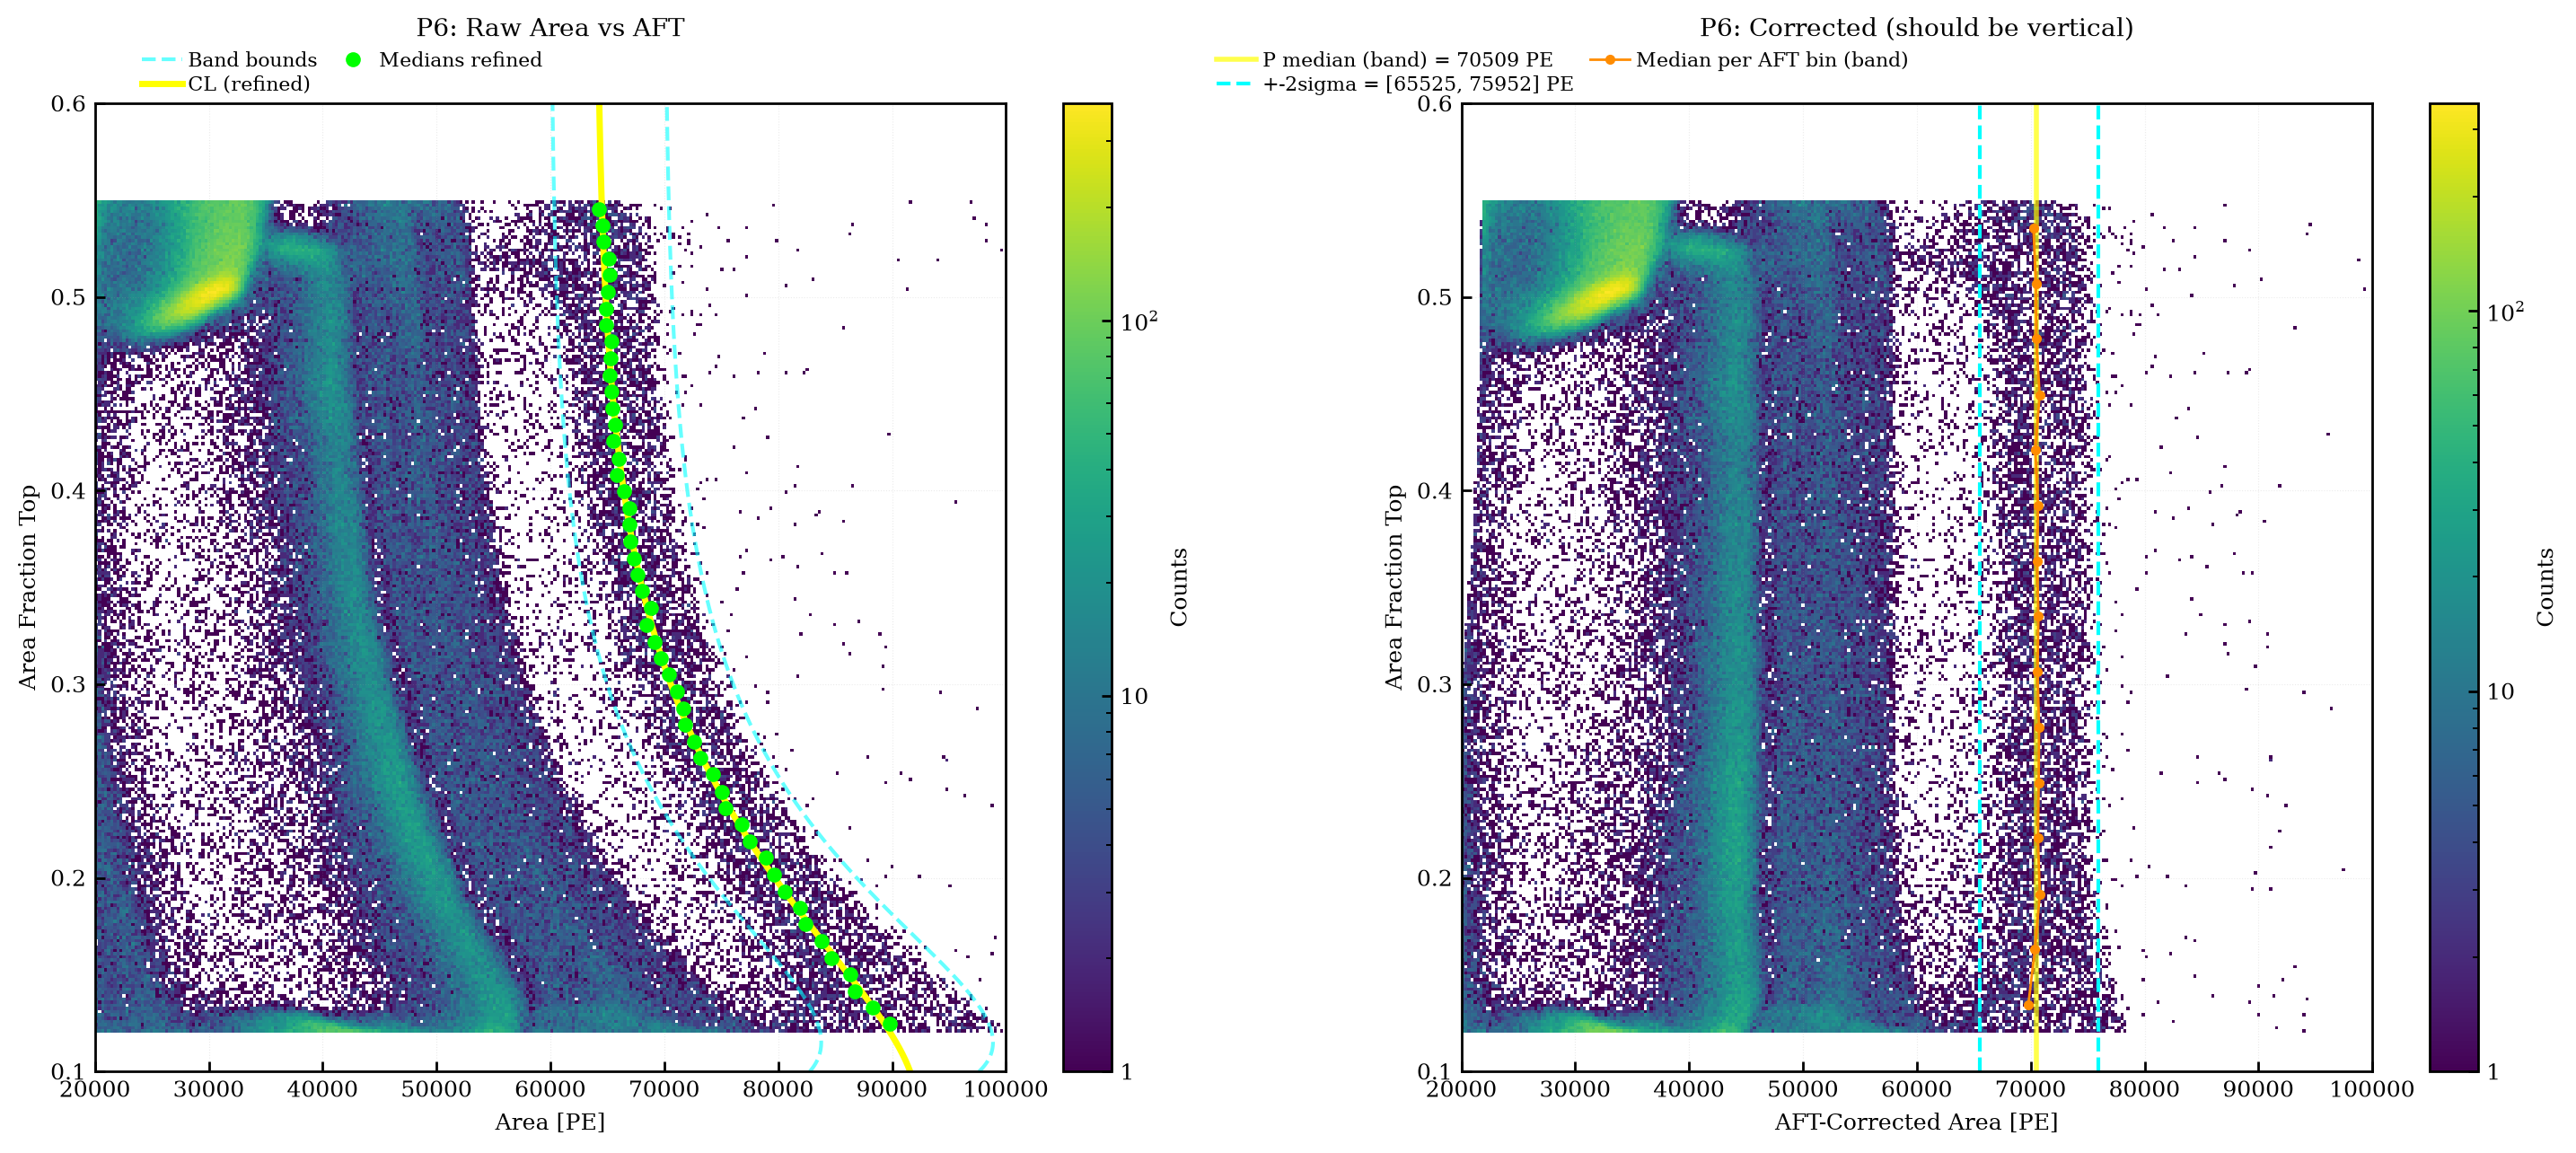

In [125]:
for pname, _, _ in PARTITIONS:
    if int((df['partition'] == pname).sum()) == 0:
        print('  %s: no events -- skip correction 1' % pname)
        continue
    cfg = CORR1_PARAMS[pname]
    corr1_aft(df, pname,
              upper=cfg['upper'], lower=cfg['lower'],
              aft_min=AFT_FIT_MIN, aft_max=AFT_FIT_MAX, aft_ref=AFT_REF,
              n_sigma=cfg['n_sigma'])

### Correction 2: r² vs AFT

#### Parameters — Correction 2

In [126]:
_CORR2_DEFAULT = {'area_lo': 40000, 'area_hi': 45000, 'poly_deg': 10,
                  'r2_min': 0, 'r2_max': 750, 'n_bins': 40}

# Per-partition overrides (any subset of keys).
_CORR2_OVERRIDE = {
    # 'P5a: 0715-0725': {'area_lo': 40000, 'area_hi': 45000},
}

CORR2_PARAMS = {p[0]: {**_CORR2_DEFAULT, **_CORR2_OVERRIDE.get(p[0], {})}
                for p in PARTITIONS}

# Filled by corr2_r2_aft(): r2 scale applied at AFT_REF (target / fitted median).
CORR2_SCALE = {}


In [127]:
def corr2_r2_aft(df, pname, area_lo, area_hi,
                 aft_min=0.12, aft_max=0.55, aft_ref=0.30, poly_deg=10,
                 r2_min=0, r2_max=750, n_bins=40, r2_ref_target=None):
    """
    Per-partition r² vs AFT correction (Correction 2).
    area_lo/hi: vertical band in area_aft_corrected to select Rn events.
    r2_ref_target: absolute r2 anchor (e.g. R2_TPC for the Po-210 wall band).
                   None -> use the fitted band median at AFT_REF.
    """
    mask_p = df['partition'] == pname
    mask_rn = (df['area_aft_corrected'] >= area_lo) & (df['area_aft_corrected'] <= area_hi)
    mask_fit = (df['area_fraction_top'] >= aft_min) & (df['area_fraction_top'] <= aft_max) & (df['r2'] >= r2_min) & (df['r2'] <= r2_max)
    d_fit = df[mask_p & mask_rn & mask_fit].copy()

    edges = np.linspace(aft_min, aft_max, n_bins + 1)
    d_fit['aft_bin'] = pd.cut(d_fit['area_fraction_top'], bins=edges)
    meds = d_fit.groupby('aft_bin', observed=True)['r2'].median()
    cnts = d_fit.groupby('aft_bin', observed=True)['r2'].count()
    aft_c = meds.index.map(lambda iv: iv.mid).astype(float).values
    r2_m = meds.values
    good = (cnts.values >= 20)

    p0 = [np.median(r2_m[good])] + [0.0] * poly_deg
    popt, _ = curve_fit(polynomial, aft_c[good], r2_m[good], p0=p0, maxfev=50000)
    r2_ref_fit = polynomial(aft_ref, *popt)
    r2_ref = r2_ref_fit if r2_ref_target is None else r2_ref_target
    CORR2_SCALE[pname] = r2_ref / max(r2_ref_fit, 1e-6)

    # Apply correction to FULL partition
    m = df['partition'] == pname
    cf = r2_ref / np.maximum(polynomial(df.loc[m, 'area_fraction_top'].values, *popt), 0.1)
    df.loc[m, 'r2_aft_corrected'] = df.loc[m, 'r2'] * cf

    print('  %s: Rn-band events=%d  r2_ref_fit(%.2f)=%.0f -> target=%.0f  cf=[%.3f, %.3f]'
          % (pname.split(':')[0], len(d_fit), aft_ref, r2_ref_fit, r2_ref, cf.min(), cf.max()))

    # ── diagnostics: original 2 panels (top) + ROI before/after (bottom) ──
    d_fit['r2_aft_corrected'] = d_fit['r2'] * r2_ref / np.maximum(
        polynomial(d_fit['area_fraction_top'].values, *popt), 0.1)

    aft_fine = np.linspace(aft_min, aft_max, 200)
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    ax1, ax2 = axes[0, 0], axes[0, 1]
    ax3, ax4 = axes[1, 0], axes[1, 1]

    # top-left: original before hist2d + fit + median
    h = ax1.hist2d(d_fit['area_fraction_top'], d_fit['r2'],
                   bins=[100, 100], range=[[aft_min, aft_max], [r2_min, r2_max]],
                   cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
    plt.colorbar(h[3], ax=ax1, label='Counts')
    ax1.plot(aft_fine, polynomial(aft_fine, *popt), 'r-', lw=2, label='Poly deg %d' % poly_deg)
    ax1.errorbar(aft_c[good], r2_m[good],
                 yerr=np.sqrt(np.maximum(r2_m[good], 1))/np.sqrt(cnts.values[good]),
                 fmt='o', capsize=2, color='lime', ms=3, label='Median')
    ax1.set_xlabel('Area Fraction Top'); ax1.set_ylabel('r2 [cm2]')
    ax1.set_title('%s: AFT vs r2 (Rn-band)' % pname.split(':')[0], pad=20)
    ax1.legend(fontsize=8); ax1.grid(True, alpha=0.2)

    # top-right: original median + fit
    ax2.errorbar(aft_c[good], r2_m[good],
                 yerr=np.sqrt(np.maximum(r2_m[good], 1))/np.sqrt(cnts.values[good]),
                 fmt='o', capsize=3, color='steelblue', label='Median r2 bin')
    ax2.plot(aft_fine, polynomial(aft_fine, *popt), 'r-', lw=2, label='Poly fit')
    ax2.set_xlabel('Area Fraction Top'); ax2.set_ylabel('Median r2 [cm2]')
    ax2.set_title('%s: AFT vs median r2 + fit' % pname.split(':')[0], pad=20)
    ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3)

    # bottom: FULL ROI before/after (all partition events entering the FV cut)
    d_all = df.loc[mask_p]
    _r2_hi_full = np.nanpercentile(d_all['r2'], 99.5)
    if not np.isfinite(_r2_hi_full) or _r2_hi_full <= 0:
        _r2_hi_full = r2_max
    _r2a_hi_full = np.nanpercentile(d_all['r2_aft_corrected'], 99.5)
    if not np.isfinite(_r2a_hi_full) or _r2a_hi_full <= 0:
        _r2a_hi_full = 1.5 * r2_ref
    _r2a_hi_full = float(np.clip(_r2a_hi_full, 1.5 * r2_ref, 3.0 * r2_ref))

    # bottom-left: full ROI before
    h = ax3.hist2d(d_all['area_fraction_top'], d_all['r2'],
                   bins=[100, 100], range=[[0.05, 0.65], [0, _r2_hi_full]],
                   cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
    plt.colorbar(h[3], ax=ax3, label='Counts')
    ax3.axhline(r2_ref, color='gray', ls=':', lw=1.5, label='r2_ref = %.0f' % r2_ref)
    ax3.set_xlabel('Area Fraction Top'); ax3.set_ylabel('r2 [cm2]')
    ax3.set_title('%s: full ROI before corr2' % pname.split(':')[0], pad=20)
    ax3.legend(fontsize=8); ax3.grid(True, alpha=0.2)

    # bottom-right: full ROI after
    h = ax4.hist2d(d_all['area_fraction_top'], d_all['r2_aft_corrected'],
                   bins=[100, 100], range=[[0.05, 0.65], [0, _r2a_hi_full]],
                   cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
    plt.colorbar(h[3], ax=ax4, label='Counts')
    ax4.axhline(r2_ref, color='r', ls='--', lw=2, label='r2_ref = %.0f' % r2_ref)
    ax4.set_xlabel('Area Fraction Top'); ax4.set_ylabel('r2_aft_corrected [cm2]')
    ax4.set_title('%s: full ROI after corr2' % pname.split(':')[0], pad=20)
    ax4.legend(fontsize=8); ax4.grid(True, alpha=0.2)

    safe_tight(fig); plt.show()
    return popt


  P6: Rn-band events=61757  r2_ref_fit(0.30)=50 -> target=3698  cf=[1.376, 36978.561]


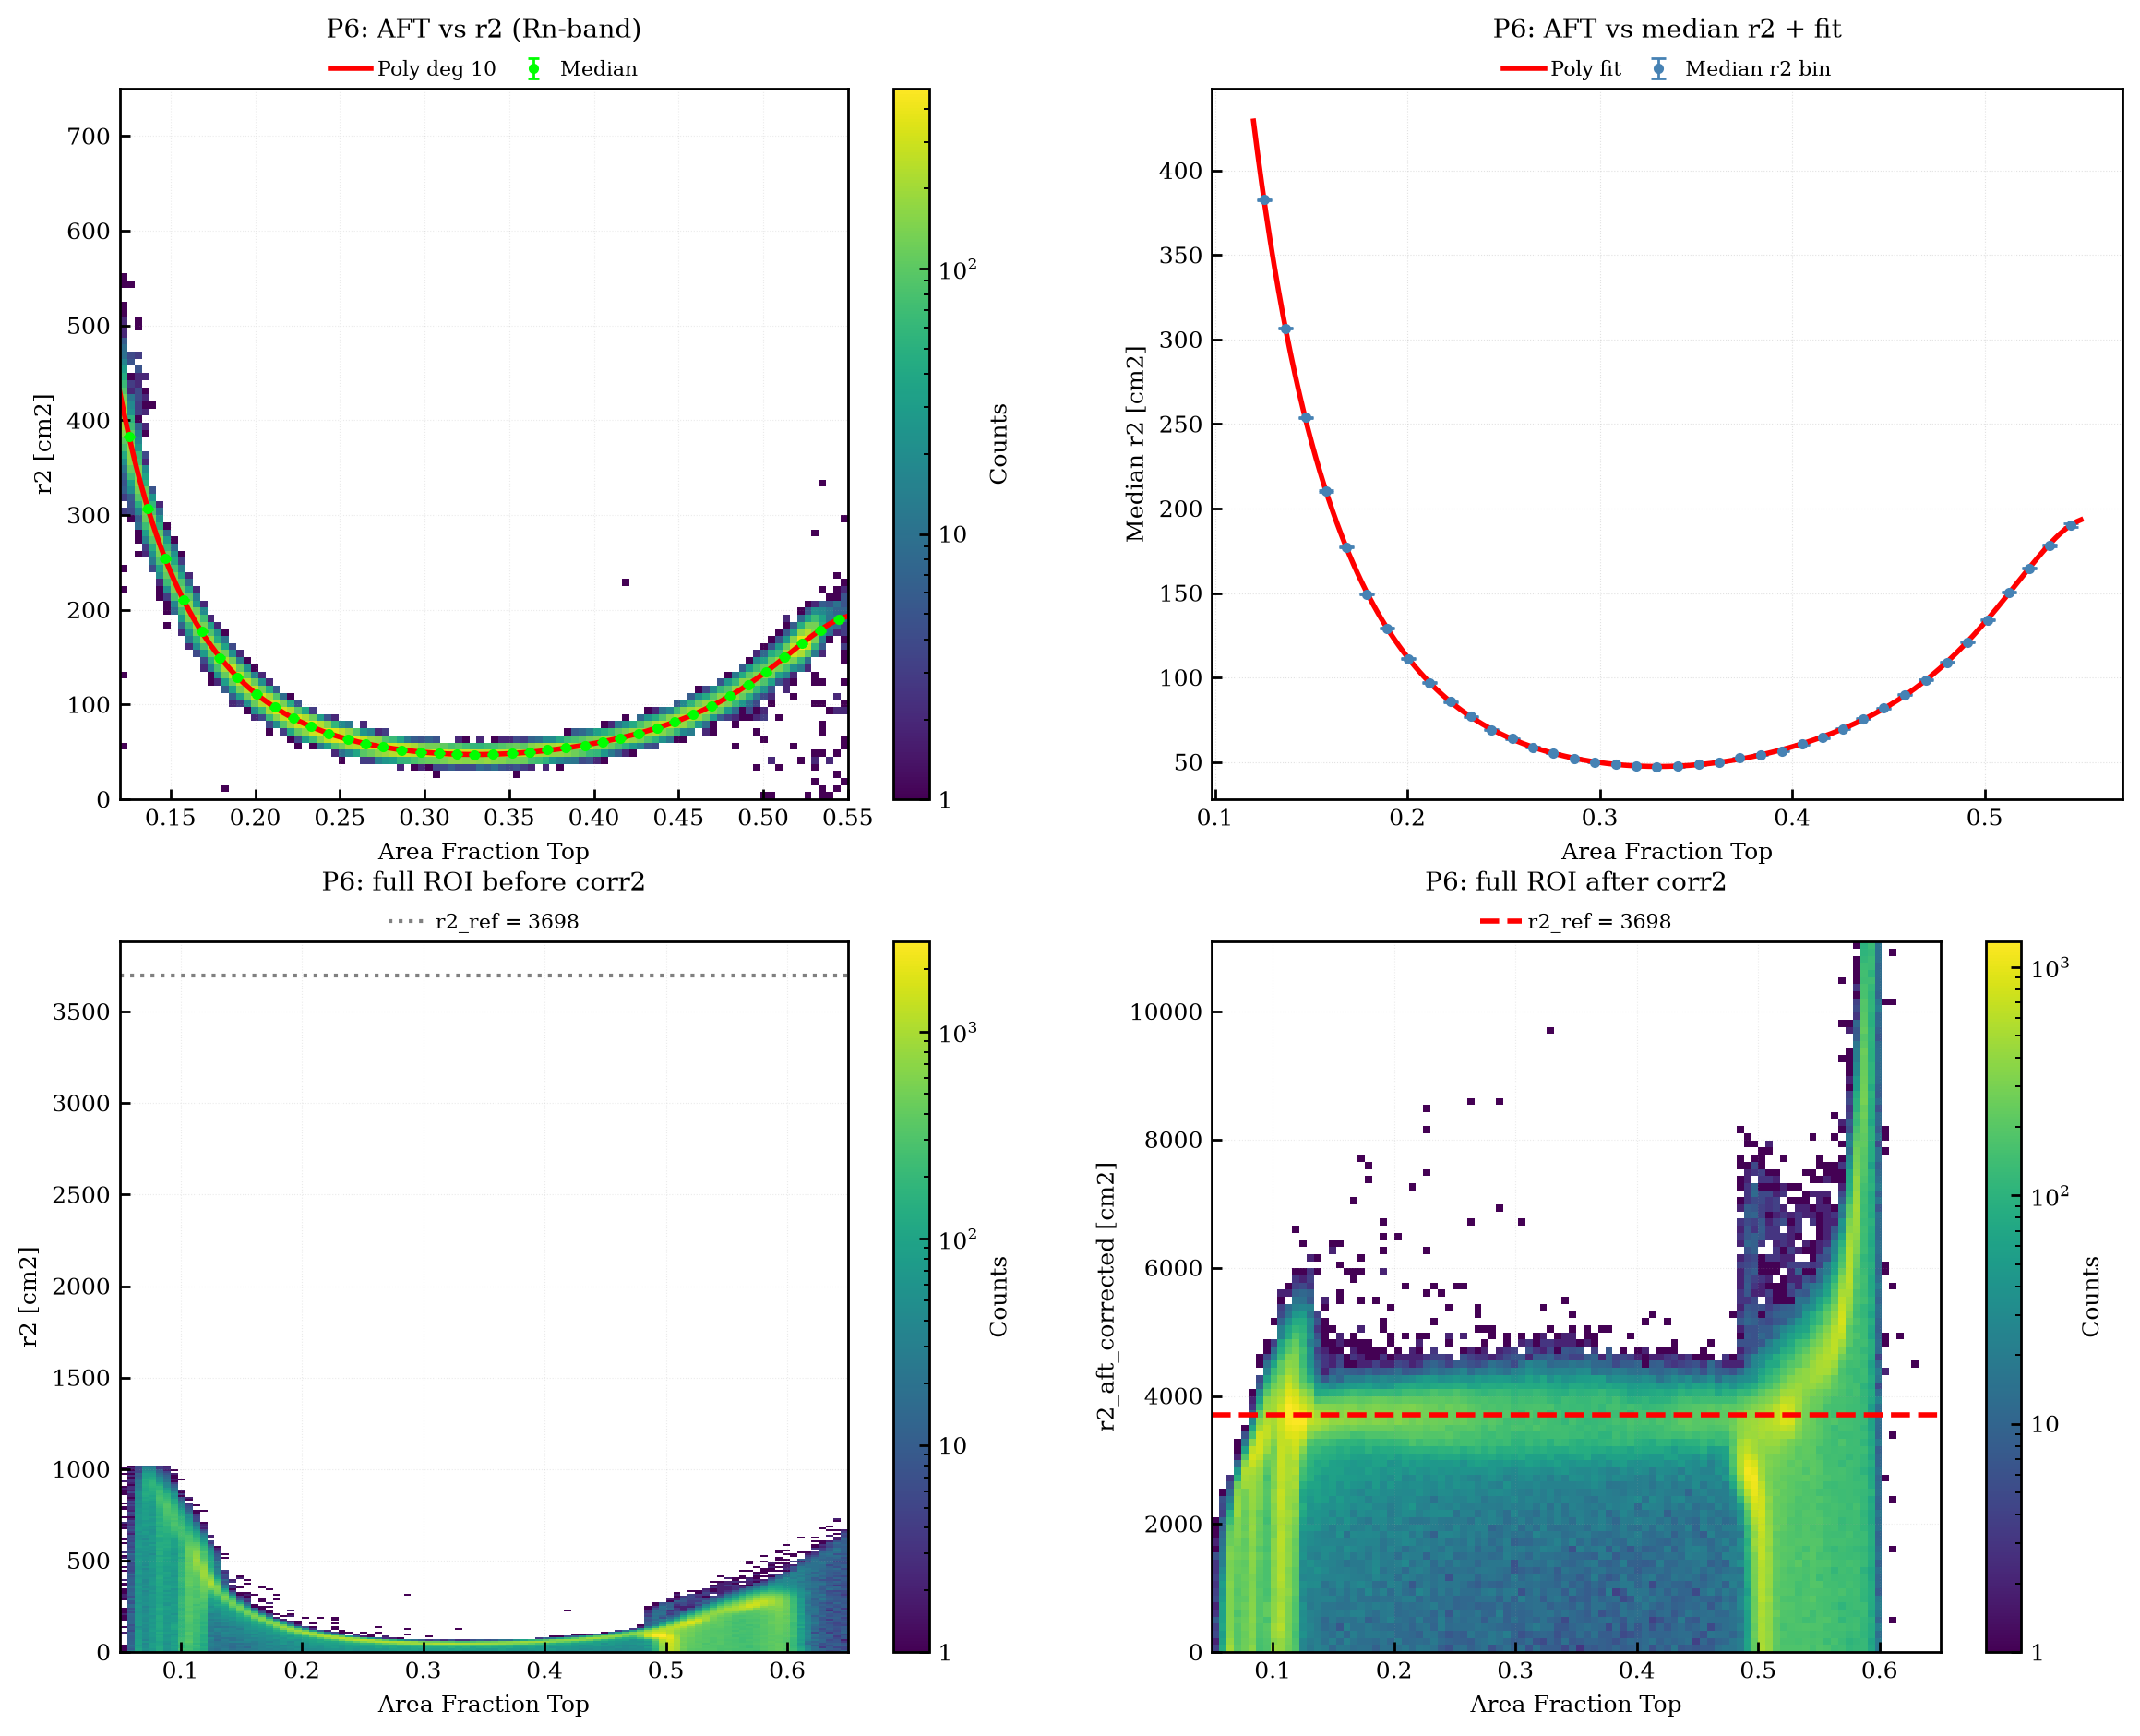

In [128]:
for pname, _, _ in PARTITIONS:
    if int((df['partition'] == pname).sum()) == 0:
        print('  %s: no events -- skip correction 2' % pname)
        continue
    cfg = CORR2_PARAMS[pname]
    corr2_r2_aft(df, pname,
                 area_lo=cfg['area_lo'], area_hi=cfg['area_hi'],
                 aft_min=AFT_FIT_MIN, aft_max=AFT_FIT_MAX, aft_ref=AFT_REF,
                 poly_deg=cfg['poly_deg'], r2_min=cfg['r2_min'],
                 r2_max=cfg['r2_max'], n_bins=cfg['n_bins'],
                 r2_ref_target=R2_TPC)

### Correction 3: r² vs Area

#### Parameters — Correction 3

In [129]:
# Band line:  area = b * r2 + e   (upper / lower intercept).
# ('b' = k_slope, 'e_upper'/'e_lower' = the two intercepts)
_CORR3_DEFAULT = {'k_slope': -110, 'intercept_upper': 75000, 'intercept_lower': 68000,
                  'r2_min': 0, 'r2_max': 100, 'r2_fit_max': 55, 'poly_deg': 6, 'n_bins': 30}

# Per-partition overrides below (fill in b / e_upper / e_lower). Values = defaults.
_CORR3_OVERRIDE = {
    'P1: OLD Q5':               {'b': -110, 'e_upper': 75000, 'e_lower': 68000},
    'P2: ST707, Q5 removed':    {'b': -110, 'e_upper': 75000, 'e_lower': 68000},
    'P3: ST707, Q5 Rn cleaned': {'b': -110, 'e_upper': 75000, 'e_lower': 68000},
    'P4: FRESH Q5':             {'b': -110, 'e_upper': 75000, 'e_lower': 68000},
    'P5a: 0715-0725':           {'b': -110, 'e_upper': 75000, 'e_lower': 68000},
    'P5b: 0725-0808':           {'b': -110, 'e_upper': 75000, 'e_lower': 68000},
    'P5c: 0808-0822':           {'b': -110, 'e_upper': 75000, 'e_lower': 68000},
    'P5d: 0822-0831':           {'b': -110, 'e_upper': 75000, 'e_lower': 68000},
    'P5e: 0831-0903':           {'b': -110, 'e_upper': 75000, 'e_lower': 68000},
    'P6: 0903-0920':            {'b': -110, 'e_upper': 78000, 'e_lower': 72000},
}

def _merge_corr3(default, ov):
    cfg = dict(default)
    ov = ov or {}
    if 'b' in ov: cfg['k_slope'] = ov['b']
    if 'e_upper' in ov: cfg['intercept_upper'] = ov['e_upper']
    if 'e_lower' in ov: cfg['intercept_lower'] = ov['e_lower']
    for k in ('k_slope', 'intercept_upper', 'intercept_lower',
              'r2_min', 'r2_max', 'r2_fit_max', 'poly_deg', 'n_bins'):
        if k in ov: cfg[k] = ov[k]
    return cfg

CORR3_PARAMS = {p[0]: _merge_corr3(_CORR3_DEFAULT, _CORR3_OVERRIDE.get(p[0]))
                for p in PARTITIONS}


In [130]:
def corr3_area_r2(df, pname, k_slope, intercept_upper, intercept_lower,
                  r2_min=0, r2_max=100, r2_fit_max=55, poly_deg=6, n_bins=30):
    """
    Per-partition r2 vs Area correction (Correction 3).
    Band: area < k_slope*r2 + intercept_upper  AND  area > k_slope*r2 + intercept_lower.
    """
    mask_p = df['partition'] == pname
    mask_fit = (df['r2_aft_corrected'] >= r2_min) & (df['r2_aft_corrected'] <= r2_max) & (df['area_aft_corrected'] >= 0) & (df['area_aft_corrected'] <= 1e5)
    d_fit = df[mask_p & mask_fit].copy()

    d_fit['in_r2_band'] = (
        (d_fit['area_aft_corrected'] < k_slope*d_fit['r2_aft_corrected'] + intercept_upper) &
        (d_fit['area_aft_corrected'] > k_slope*d_fit['r2_aft_corrected'] + intercept_lower))

    edges = np.linspace(r2_min, r2_max, n_bins + 1)
    d_fit['r2_bin'] = pd.cut(d_fit['r2_aft_corrected'], bins=edges)
    meds = d_fit[d_fit['in_r2_band']].groupby('r2_bin', observed=True)['area_aft_corrected'].median()
    cnts = d_fit[d_fit['in_r2_band']].groupby('r2_bin', observed=True)['area_aft_corrected'].count()
    r2_c = meds.index.map(lambda iv: iv.mid).astype(float).values
    a_m = meds.values
    good = (cnts.values >= 10) & (r2_c < r2_fit_max)

    p0 = [np.median(a_m[good])] + [0.0] * poly_deg
    popt, _ = curve_fit(polynomial, r2_c[good], a_m[good], p0=p0, maxfev=50000)
    area_ref = polynomial(0, *popt)

    # Apply correction to FULL partition
    m = df['partition'] == pname
    cf_raw = area_ref / polynomial(df.loc[m, 'r2_aft_corrected'].values, *popt)
    cf = np.clip(cf_raw, 0.5, 2.0)
    df.loc[m, 'area_2_corrected'] = df.loc[m, 'area_aft_corrected'] * cf
    n_clip = (cf_raw != cf).sum()

    print('  %s: band events=%d  area_ref(r2=0)=%.0f PE  cf=[%.3f,%.3f]%s'
          % (pname.split(':')[0], d_fit['in_r2_band'].sum(), area_ref, cf.min(), cf.max(),
             ' (clipped %d)' % n_clip if n_clip > 0 else ''))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
    h = ax1.hist2d(d_fit['r2_aft_corrected'], d_fit['area_aft_corrected'],
                   bins=[80, 100], range=[[r2_min, r2_max], [20e3, 100e3]],
                   cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
    plt.colorbar(h[3], ax=ax1, label='Counts')
    r2f = np.linspace(r2_min, r2_max, 200)
    ax1.plot(r2f, k_slope*r2f + intercept_upper, '--', color='cyan', lw=2, alpha=0.7, label='Band bound')
    ax1.plot(r2f, k_slope*r2f + intercept_lower, '--', color='cyan', lw=2, alpha=0.7)
    ax1.plot(r2f, polynomial(r2f, *popt), 'r-', lw=2, label='Poly deg %d' % poly_deg)
    ax1.axvline(x=r2_fit_max, color='orange', ls=':', lw=1.5, label='Fit limit r2=%d' % r2_fit_max)
    ax1.set_xlabel('r2_aft_corrected [cm2]'); ax1.set_ylabel('area_aft_corrected [PE]')
    ax1.set_title('%s: r2 vs area + band' % pname.split(':')[0], pad=27)
    ax1.legend(fontsize=8); ax1.grid(True, alpha=0.2)
    ax1.set_ylim(20e3, 100e3)

    # Right: corrected data (should be flat vs r2)
    d_corr = df[mask_p & mask_fit]
    h2 = ax2.hist2d(d_corr['r2_aft_corrected'], d_corr['area_2_corrected'],
                    bins=[80, 100], range=[[r2_min, r2_max], [20e3, 100e3]],
                    cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
    plt.colorbar(h2[3], ax=ax2, label='Counts')
    ax2.axhline(area_ref, color='gray', ls='--', lw=1.5, label='Ref(0)=%.0f' % area_ref)
    ax2.axvline(x=r2_fit_max, color='orange', ls=':', lw=1.5, label='Fit limit r2=%d' % r2_fit_max)
    ax2.set_xlabel('r2_aft_corrected [cm2]'); ax2.set_ylabel('area_2_corrected [PE]')
    ax2.set_title('%s: corrected (should be flat)' % pname.split(':')[0], pad=27)
    ax2.legend(fontsize=9); ax2.grid(True, alpha=0.2)
    ax2.set_ylim(20e3, 100e3)
    safe_tight(fig); plt.show()
    return popt, area_ref


  P6: band events=9253  area_ref(r2=0)=74907 PE  cf=[0.500,2.000] (clipped 92644)


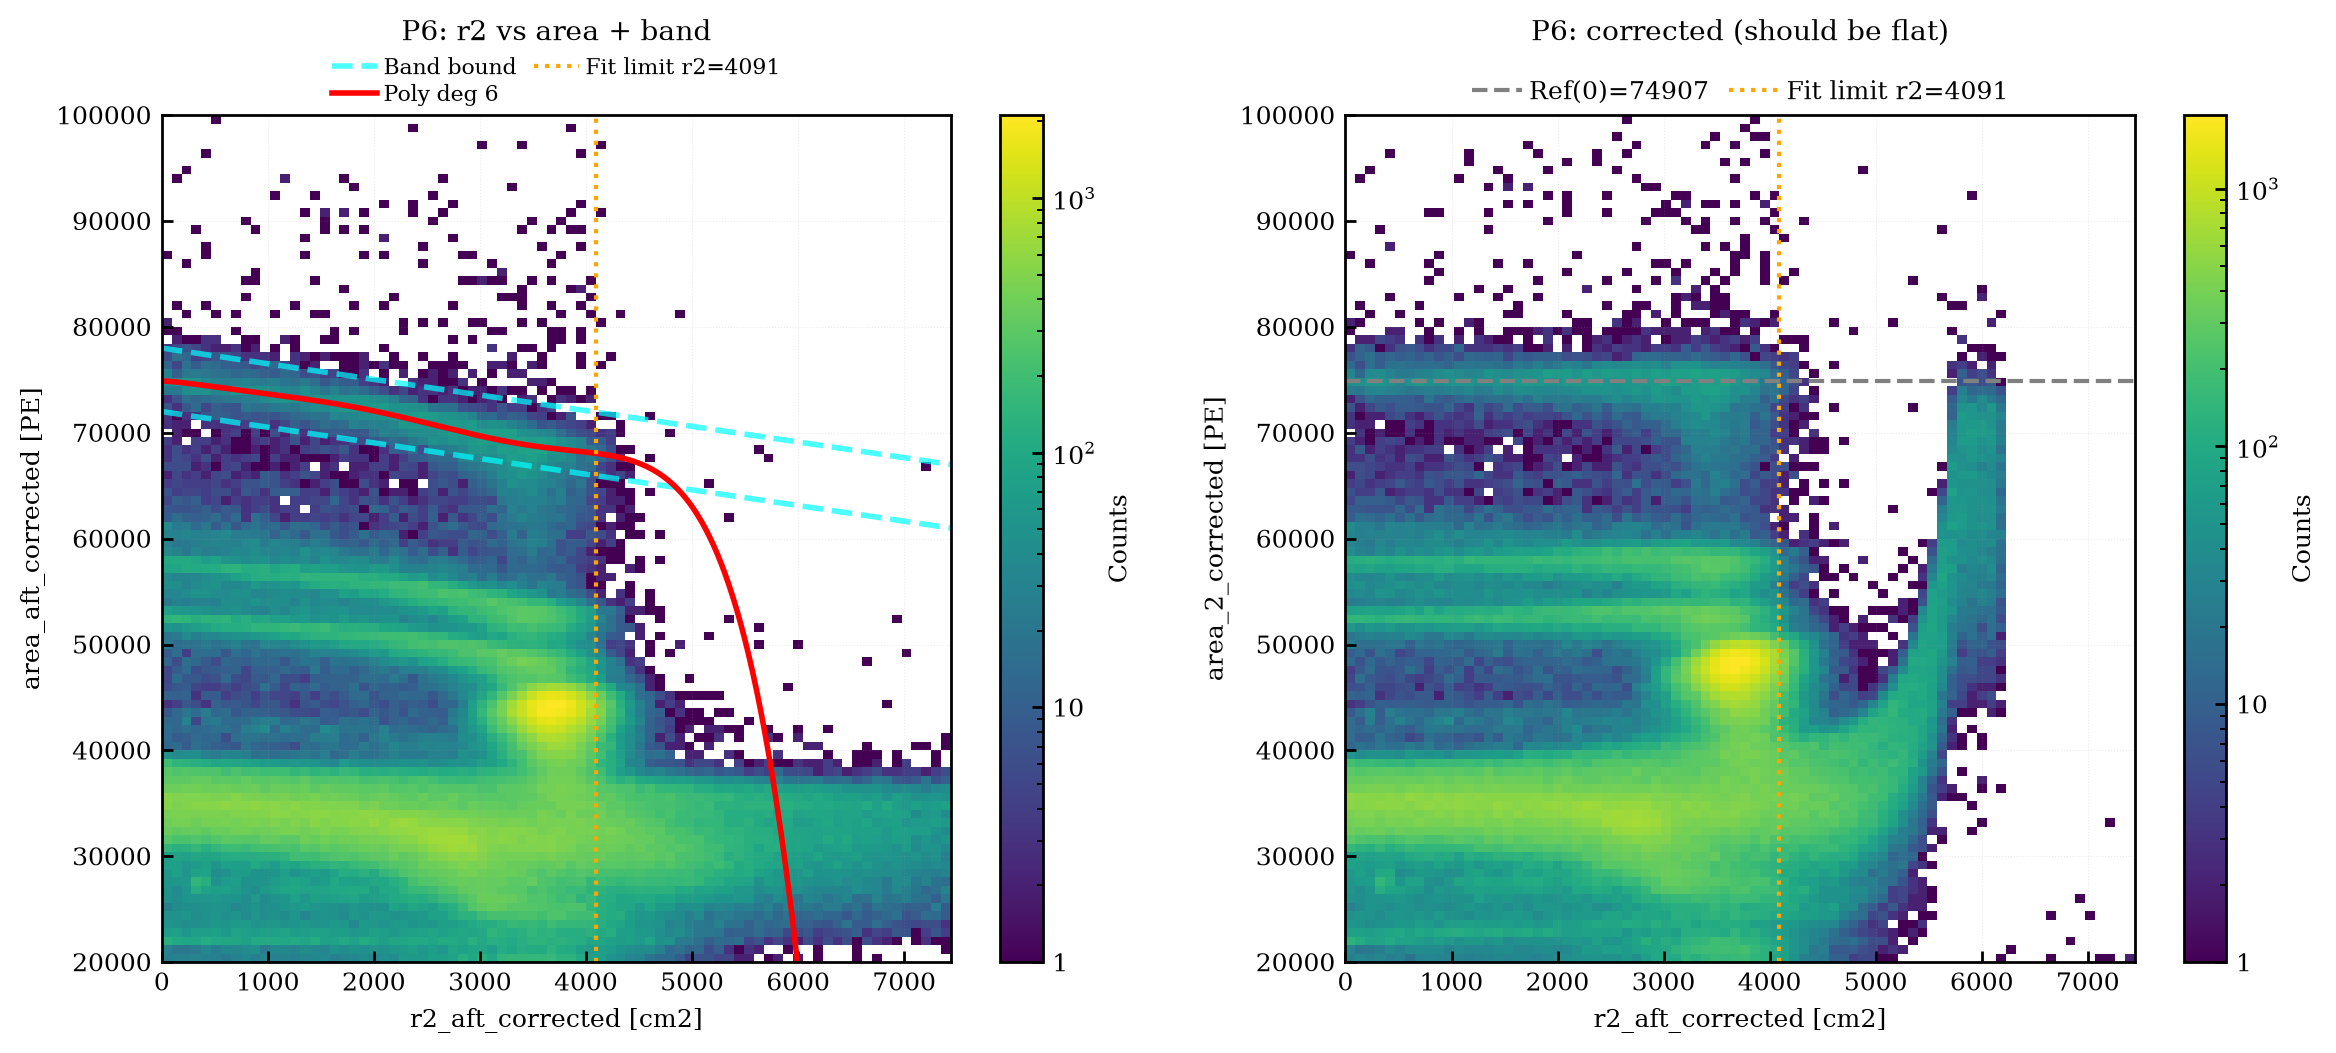

In [131]:
for pname, _, _ in PARTITIONS:
    if int((df['partition'] == pname).sum()) == 0:
        print('  %s: no events -- skip correction 3' % pname)
        continue
    cfg = CORR3_PARAMS[pname]
    # corr2 rescaled r2 by S; corr3's band was tuned on the old r2 scale.
    s = CORR2_SCALE.get(pname, 1.0)
    corr3_area_r2(df, pname,
                  k_slope=cfg['k_slope'] / s,
                  intercept_upper=cfg['intercept_upper'],
                  intercept_lower=cfg['intercept_lower'],
                  r2_min=cfg['r2_min'] * s, r2_max=cfg['r2_max'] * s,
                  r2_fit_max=cfg['r2_fit_max'] * s, poly_deg=cfg['poly_deg'],
                  n_bins=cfg['n_bins'])


---
## 5. Fiducial volume cut

Applied after all three corrections. `R2_FV_MAX` is in CONFIG (default 75).

#### Parameters (edit here before running this section)

In [132]:
# Post-correction fiducial cuts
AFT_FV_MIN, AFT_FV_MAX = 0.13, 0.46
R2_FV_MAX = 3600.0  # r2_aft_corrected [cm^2] -- just inside the TPC wall (~60 cm)

FV cut [AFT 0.13-0.46, r2<3600]:
  Before: 583688  |  After: 70104  |  Removed: 513584 (88.0%)


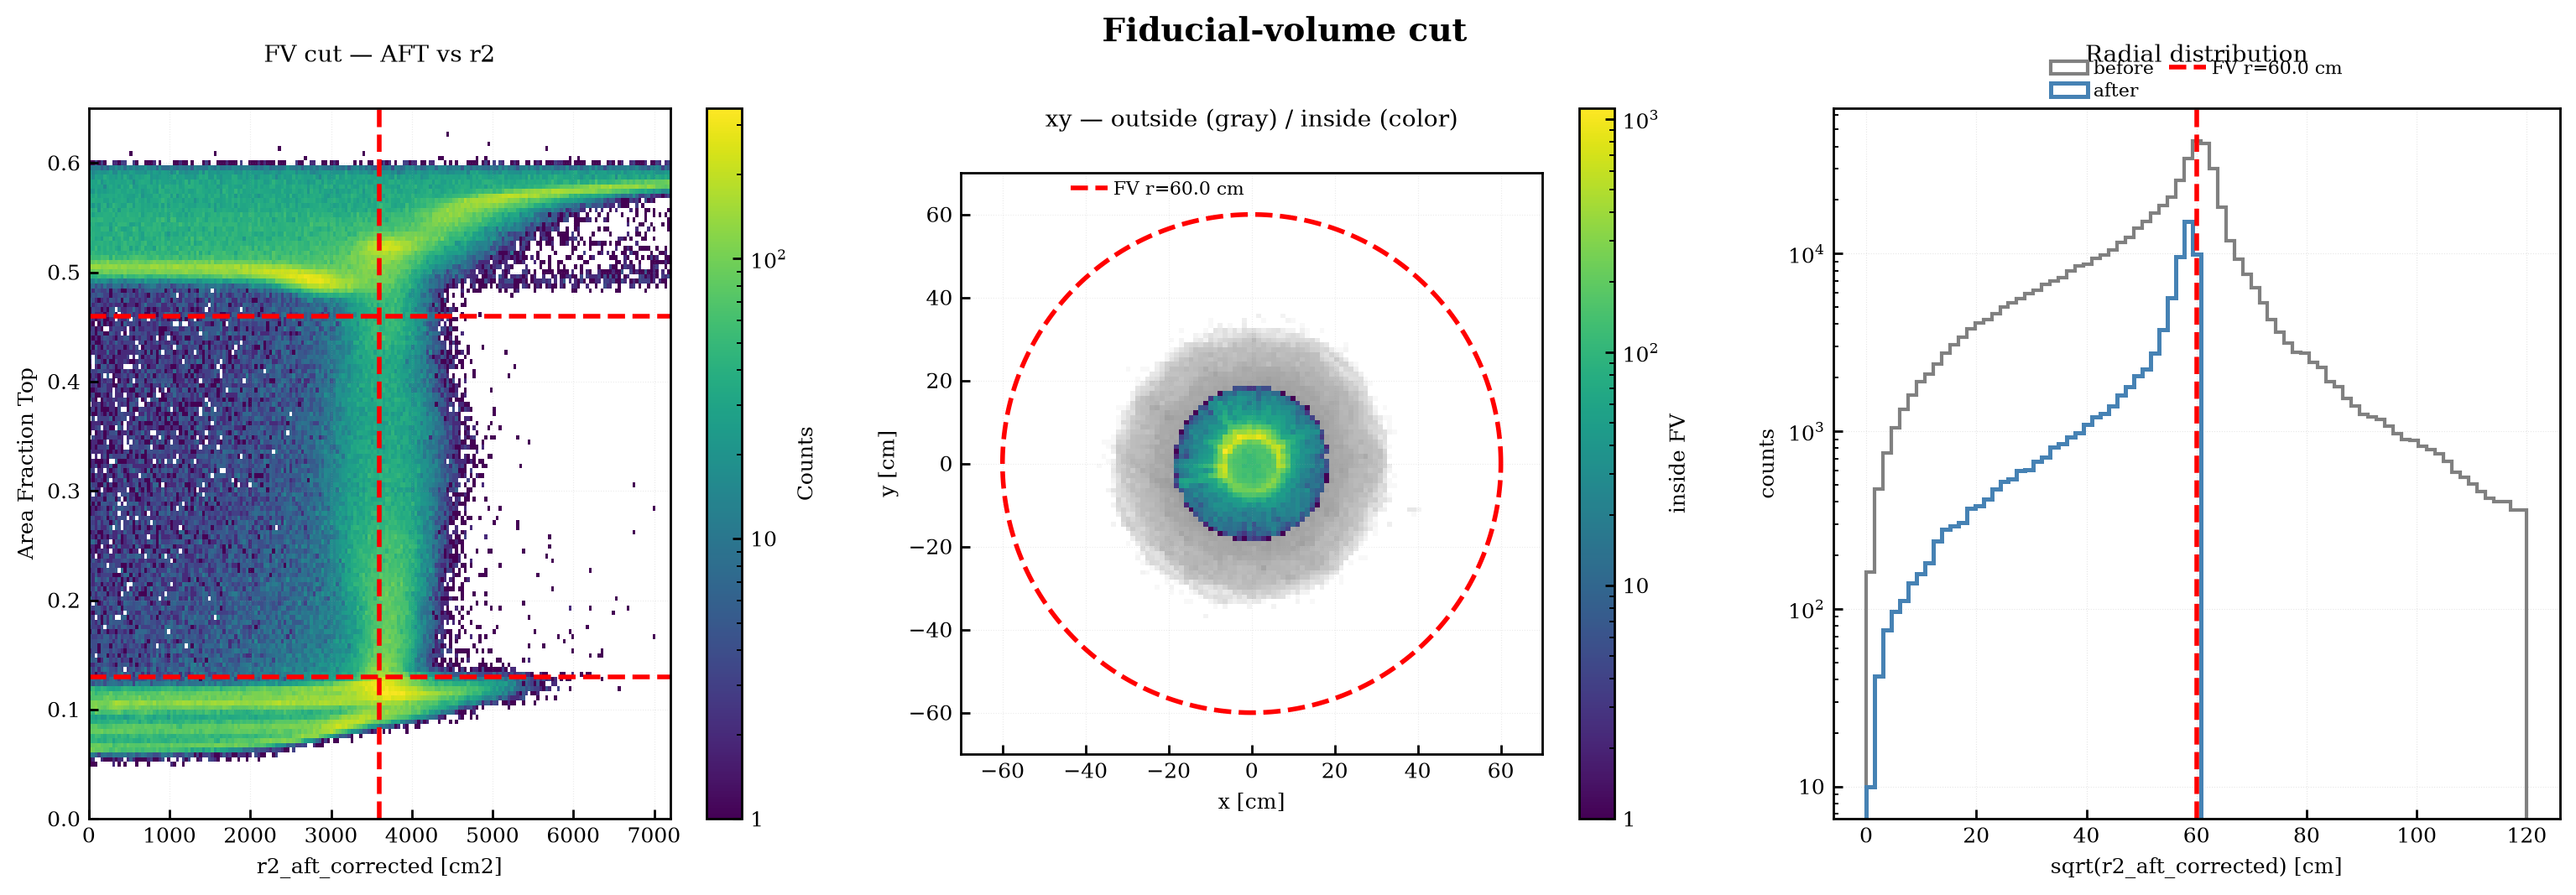


Final events after all cuts: 70104
Per partition:
partition
P6: 0903-0920    70104
Name: count, dtype: int64


In [133]:
# FV cut  (AFT_FV_MIN / AFT_FV_MAX / R2_FV_MAX come from the Parameters cell above)
m_fv = ((df['area_fraction_top'] >= AFT_FV_MIN) & (df['area_fraction_top'] <= AFT_FV_MAX) &
        (df['r2_aft_corrected'] >= 0) & (df['r2_aft_corrected'] <= R2_FV_MAX))
print('FV cut [AFT %.2f-%.2f, r2<%.0f]:' % (AFT_FV_MIN, AFT_FV_MAX, R2_FV_MAX))
print('  Before: %d  |  After: %d  |  Removed: %d (%.1f%%)'
      % (len(df), m_fv.sum(), (~m_fv).sum(), 100*(~m_fv).sum()/len(df)))

# ── FV diagnostics ──
_r_fv = np.sqrt(max(R2_FV_MAX, 0.0))
_has_pos = df['x'].notna() & df['y'].notna()
_inside  = m_fv & _has_pos
_outside = (~m_fv) & _has_pos

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# [0] AFT vs r2_aft_corrected + FV box
ax = axes[0]
_r2_hi = np.nanpercentile(df['r2_aft_corrected'], 99.5)
if not np.isfinite(_r2_hi) or _r2_hi <= 0:
    _r2_hi = 1.2 * R2_FV_MAX
_r2_hi = float(np.clip(_r2_hi, 1.2 * R2_FV_MAX, 2.0 * R2_FV_MAX))
h = ax.hist2d(df['r2_aft_corrected'], df['area_fraction_top'],
              bins=[200, 150], range=[[0, _r2_hi], [0, 0.65]],
              cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
plt.colorbar(h[3], ax=ax, label='Counts')
ax.axvline(R2_FV_MAX, color='red', ls='--', lw=2)
ax.axhline(AFT_FV_MIN, color='red', ls='--', lw=2)
ax.axhline(AFT_FV_MAX, color='red', ls='--', lw=2)
ax.set_xlabel('r2_aft_corrected [cm2]'); ax.set_ylabel('Area Fraction Top')
ax.set_title('FV cut — AFT vs r2', pad=20)
ax.grid(True, alpha=0.2)

# [1] xy: outside gray, inside colour + FV circle
ax = axes[1]
xy_range = [[-70, 70], [-70, 70]]
if _outside.any():
    ax.hist2d(df.loc[_outside, 'x'], df.loc[_outside, 'y'],
              bins=[120, 120], range=xy_range, cmin=1,
              norm=matplotlib.colors.LogNorm(), cmap='Greys', alpha=0.6)
if _inside.any():
    hi = ax.hist2d(df.loc[_inside, 'x'], df.loc[_inside, 'y'],
                   bins=[120, 120], range=xy_range, cmin=1,
                   norm=matplotlib.colors.LogNorm(), cmap='viridis')
    plt.colorbar(hi[3], ax=ax, label='inside FV')
_th = np.linspace(0, 2*np.pi, 300)
ax.plot(_r_fv*np.cos(_th), _r_fv*np.sin(_th), 'r--', lw=2,
        label='FV r=%.1f cm' % _r_fv)
ax.set_xlabel('x [cm]'); ax.set_ylabel('y [cm]')
ax.set_aspect('equal')
ax.set_title('xy — outside (gray) / inside (color)', pad=20)
ax.legend(fontsize=8, loc='upper right'); ax.grid(True, alpha=0.2)

# [2] radial before/after
ax = axes[2]
_r_all = np.sqrt(np.maximum(df['r2_aft_corrected'].values, 0.0))
_r_all = _r_all[np.isfinite(_r_all)]
_r_in  = np.sqrt(np.maximum(df['r2_aft_corrected'].values[m_fv.values], 0.0))
_r_in  = _r_in[np.isfinite(_r_in)]
_r99 = np.nanpercentile(_r_all, 99.5) if len(_r_all) else 0
if not np.isfinite(_r99) or _r99 <= 0:
    _r99 = 1.5 * _r_fv
_r99 = float(np.clip(_r99, 1.5 * _r_fv, 2.0 * _r_fv))
_edges_r = np.linspace(0, max(1.5*_r_fv, _r99, 1.0), 80)
ax.hist(_r_all, bins=_edges_r, histtype='step', color='gray', lw=1.5, label='before')
ax.hist(_r_in,  bins=_edges_r, histtype='step', color='steelblue', lw=1.8, label='after')
ax.axvline(_r_fv, color='red', ls='--', lw=2, label='FV r=%.1f cm' % _r_fv)
ax.set_yscale('log')
ax.set_xlabel('sqrt(r2_aft_corrected) [cm]'); ax.set_ylabel('counts')
ax.set_title('Radial distribution', pad=20)
ax.legend(fontsize=8); ax.grid(True, alpha=0.25)

fig.suptitle('Fiducial-volume cut', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()

df_cut = df[m_fv].copy().reset_index(drop=True)
print('\nFinal events after all cuts: %d' % len(df_cut))
print('Per partition:')
print(df_cut['partition'].value_counts().sort_index())


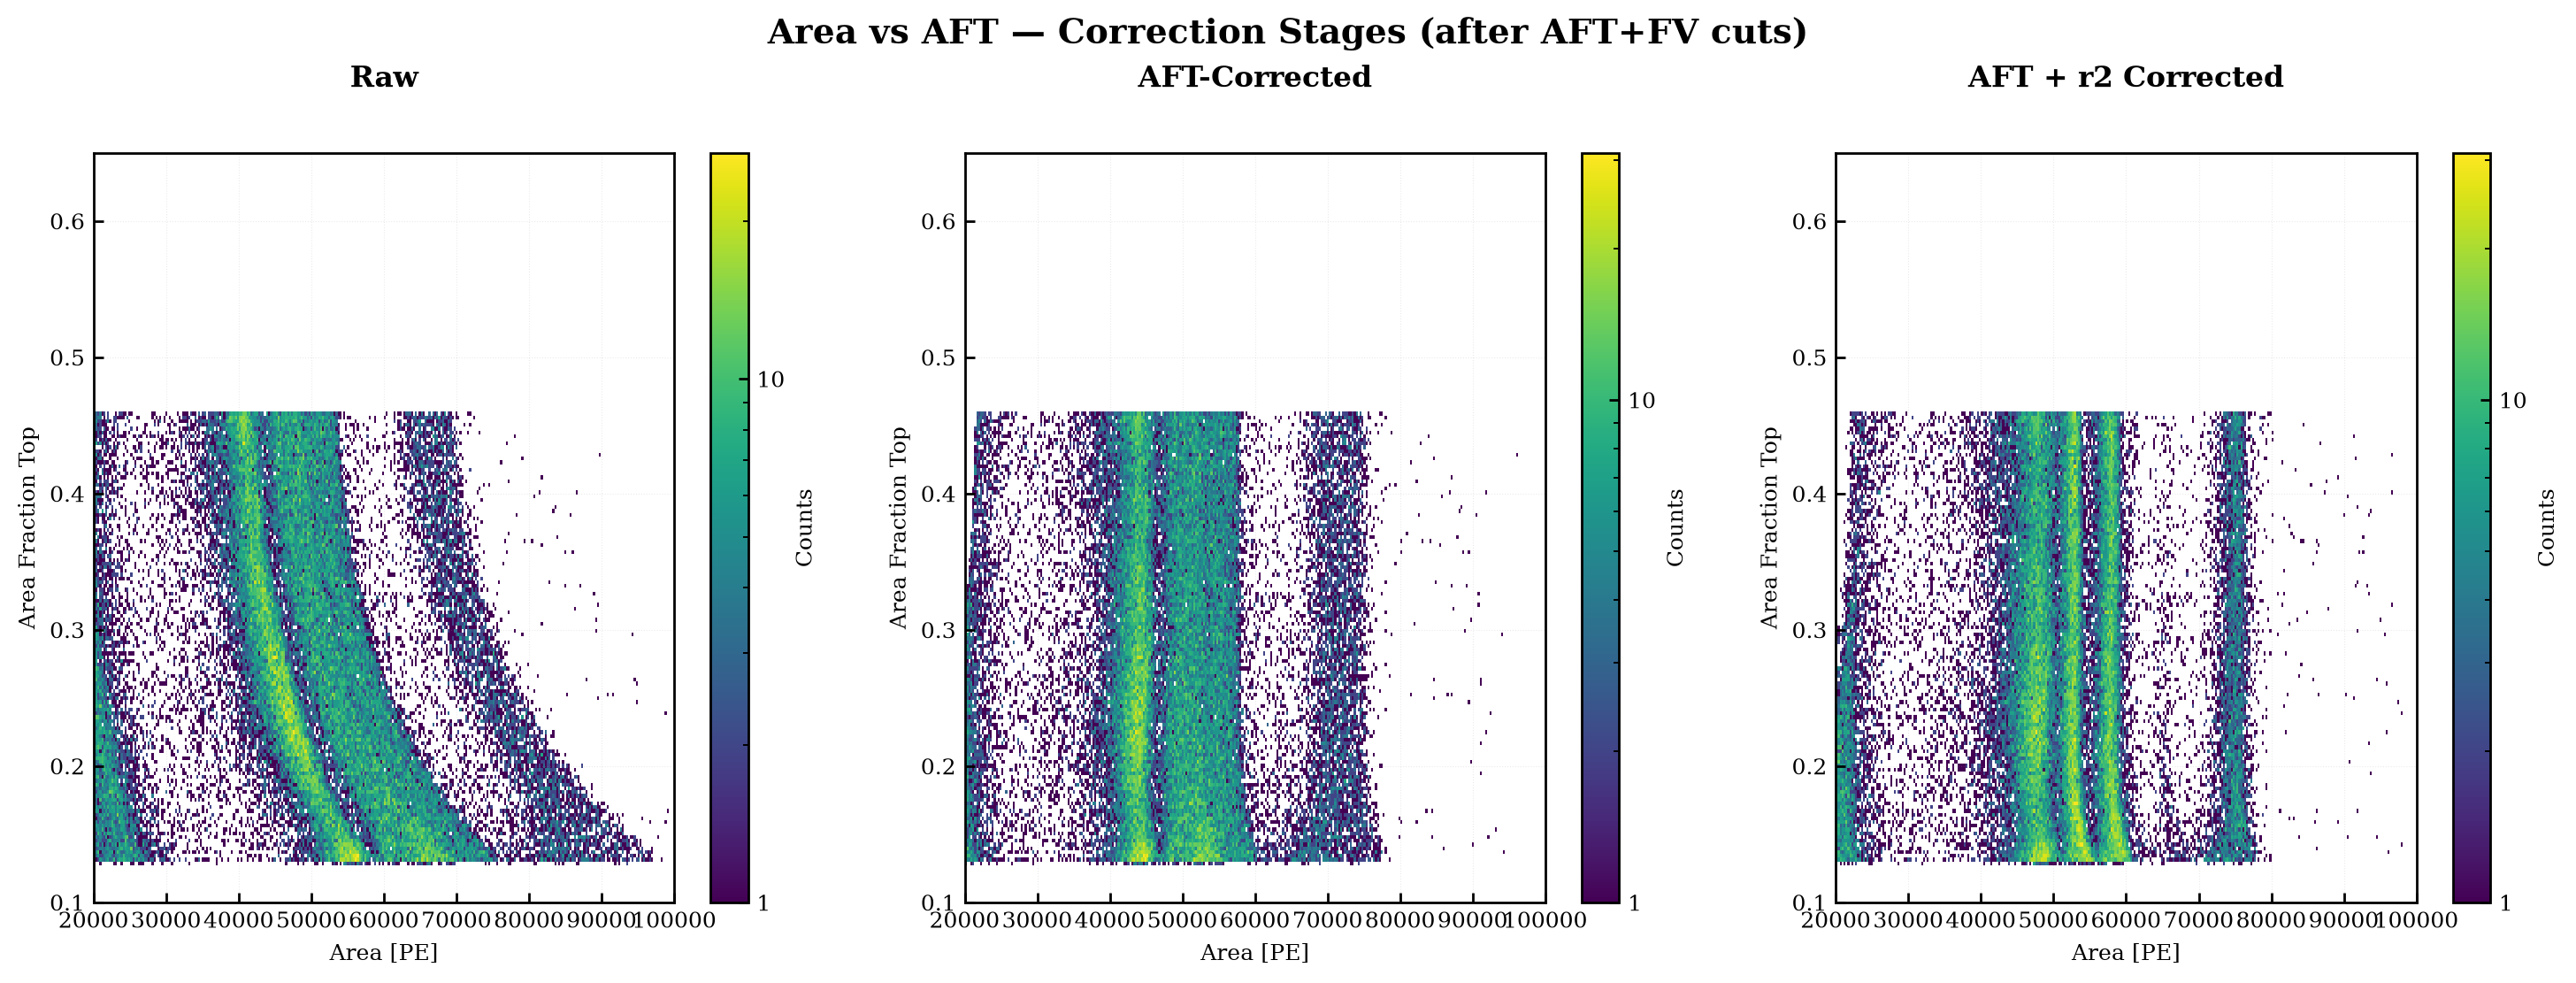

In [134]:
# ═════════════════════════════════════════════════════════════
# CORRECTION PIPELINE COMPARISON — all stages (after cuts)
# ═════════════════════════════════════════════════════════════

stages = [
    ('Raw',                    'area'),
    ('AFT-Corrected',          'area_aft_corrected'),
    ('AFT + r2 Corrected',     'area_2_corrected'),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, (label, col) in zip(axes, stages):
    if col in df_cut.columns:
        h = ax.hist2d(df_cut[col], df_cut['area_fraction_top'],
                      bins=[300, 200],
                      range=[[20e3, 100e3], [0.1, 0.65]],
                      cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
        plt.colorbar(h[3], ax=ax, label='Counts')
        ax.set_xlabel('Area [PE]')
        ax.set_ylabel('Area Fraction Top')
        ax.set_title(label, fontweight='bold', fontsize=12, pad=27)
        ax.grid(True, alpha=0.2)

fig.suptitle('Area vs AFT — Correction Stages (after AFT+FV cuts)', fontsize=14, fontweight='bold', y=1.02)
safe_tight(fig)
plt.show()


In [135]:
# alias used by every downstream fit / rate cell (original name)
rn_events = df_cut
print('rn_events: %d events' % len(rn_events))

# date range actually covered by the data (clips every trend plot)
DATA_T0 = rn_events['time'].min() / 1e9
DATA_T1 = rn_events['time'].max() / 1e9
DATA_XLIM = (datetime.fromtimestamp(DATA_T0, tz=timezone.utc),
             datetime.fromtimestamp(DATA_T1, tz=timezone.utc))
print('Data time range: %s -> %s UTC' % (
    DATA_XLIM[0].strftime('%Y-%m-%d'), DATA_XLIM[1].strftime('%Y-%m-%d')))

rn_events: 70104 events
Data time range: 2026-09-03 -> 2026-09-19 UTC


---
## 6. Save corrected events

#### Parameters (edit here before running this section)

In [136]:
DO_SAVE   = True
SAVE_PATH = '/project2/lgrandi/jietang/sr3_commissioning/sr3_master_corrected_P6.pkl'


In [137]:
if DO_SAVE:
    df_cut.to_pickle(SAVE_PATH)
    print('Saved: %s (%d events, %d columns)' % (SAVE_PATH, len(df_cut), len(df_cut.columns)))
else:
    print('DO_SAVE = False -- skipping save (set DO_SAVE = True in CONFIG).')

Saved: /project2/lgrandi/jietang/sr3_commissioning/sr3_master_corrected_P6.pkl (70104 events, 12 columns)


---
## 7. Run list (straxen)

Run boundaries / livetime for the per-run and per-partition rate extraction.
Only runs present in the loaded data are kept.

#### Parameters (edit here before running this section)

In [138]:
OUTPUT_FOLDER = '/scratch/midway3/jietang/strax_data'
SHARED_DATA   = '/project/lgrandi-shared/commissioning/'
MIN_RUN_DATE  = '2026-09-03'


In [139]:
# ═══════════════════════════════════════════════════════════════
# RUN LIST FROM STRAXEN
# ═══════════════════════════════════════════════════════════════
import strax
import straxen

st = straxen.contexts.xenonnt_online(output_folder=OUTPUT_FOLDER)
st.storage.append(strax.DataDirectory(SHARED_DATA, readonly=True))

runs_sr3 = st.select_runs(
    run_mode='tpc_bkg',
    exclude_tags=['abandon', 'messy', 'timing_issue'],
)
runs_sr3['start_s'] = runs_sr3['start'].apply(lambda x: x.timestamp())
min_run_s = pd.Timestamp(MIN_RUN_DATE, tz='UTC').timestamp()
runs_sr3 = runs_sr3[runs_sr3['start_s'] >= min_run_s].copy()

# keep only runs that are actually present in the loaded data
if 'run_name' in df.columns:
    present = set(df['run_name'].astype(str).unique())
    runs_sr3 = runs_sr3[runs_sr3['name'].astype(str).isin(present)].copy()

print('Runs: %d  (%s - %s)' % (len(runs_sr3), runs_sr3['name'].min(), runs_sr3['name'].max()))

Provides of multi-output plugins overlap, deregister old plugins <class 'straxen.plugins.merged_s2s.merged_s2s.MergedS2s'>.


You specified _auto_append_rucio_local=True and you are not on dali compute nodes, so we will add the following rucio local path: /project/lgrandi/rucio/


Checking data availability:   0%|          | 0/2 [00:00<?, ?it/s]

Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin
Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin


Runs: 403  (086409 - 087192)


---
## 8. Per-partition fit

Fit each partition's high-statistics corrected spectrum with the selected model
(`FIT_METHODS` in CONFIG). Peaks: Rn-222 / Po-218 / Po-214 (Q-values).

In [140]:
# ═══════════════════════════════════════════════════════════════
# SETUP — parameters + model/helper definitions
# ═══════════════════════════════════════════════════════════════

# ---- Parameters ----
FIT_RANGE  = (50e3, 80e3)     # fit window (stay above the messy low-E continuum)
X_REF      = 61500.0          # reference point for the polynomial background
N_BINS_FIT = 800              # histogram bins used by the PER-PARTITION fit
N_BINS_RUN = 300              # histogram bins used by the PER-RUN fit

RN222_REF = 53000

# FIT_COMPONENT_CFG is built in section 0.3 from FIT_PEAKS, so the peak list is a
# single switch: comment a line in FIT_PEAKS to drop that peak.



# ---- Gaussian + quadratic-background primitives ----
def _gauss(x, amp, mu, sig):
    return amp * np.exp(-0.5 * ((x - mu) / sig)**2)

def _bg(x, a0, a1, a2):
    xr = x - X_REF
    return a0 + a1 * xr + a2 * xr**2


# ---- Free model: N x (amp, mu, sig) + quadratic bg  ->  3N+3 params ----
def multi_gaussian(x, *params):
    result = _bg(x, params[-3], params[-2], params[-1])
    for i in range(N_PEAKS):
        result = result + _gauss(x, params[3*i], params[3*i+1], params[3*i+2])
    return result

print(f'multi_gaussian — {N_PEAKS} amp + {N_PEAKS} mu + {N_PEAKS} sigma + 3 bg  ({N_PEAKS*3+3} params)')
print('FIT_RANGE =', FIT_RANGE, '| N_BINS_FIT =', N_BINS_FIT, '| N_BINS_RUN =', N_BINS_RUN)


# ---- Auto-calibrate the Rn-222 scale from the data ----
def find_peak_guess(events, n_bins=150):
    if len(events) < 30:
        return None, None
    counts, edges = np.histogram(events['area_2_corrected'], bins=n_bins, range=FIT_RANGE)
    centers = 0.5*(edges[:-1] + edges[1:])
    peaks_idx, props = find_peaks(counts, height=counts.max()*0.05, distance=10)
    sel_rn = (centers[peaks_idx] >= 48000) & (centers[peaks_idx] <= 60000)
    if sel_rn.any():
        rn_idx = peaks_idx[sel_rn][np.argmax(props['peak_heights'][sel_rn])]
        rn222_mu = centers[rn_idx]
    else:
        m = (centers >= 48000) & (centers <= 60000)
        if not m.any():
            return None, None
        rn222_mu = centers[m][np.argmax(counts[m])]
    return rn222_mu, rn222_mu * FIT_ENERGIES / E_RN222


# ---- p0 / bounds builder ----
def _amp0(x, y, mu0):
    return max(y[np.argmin(np.abs(x - mu0))] * 0.5, 3)

def _build_p0(x, y, guess_mu, scale_guess):
    p0, lo, hi = [], [], []
    for k, name in enumerate(FIT_COMPONENTS):
        cfg = FIT_COMPONENT_CFG[name]
        if name in ('Rn-220', 'Po-216') or guess_mu is None:
            mu0 = cfg['mu0']
        else:
            mu0 = guess_mu[k]
        mu0 = float(np.clip(mu0, cfg['mu_b'][0] + 50, cfg['mu_b'][1] - 50))
        p0 += [_amp0(x, y, mu0), mu0, cfg['sig0']]
        lo += [0, cfg['mu_b'][0], cfg['sig_b'][0]]
        hi += [np.inf, cfg['mu_b'][1], cfg['sig_b'][1]]
    bg0 = max(np.median(y), 1.0)
    p0 += [bg0, 0.0, 0.0]; lo += [0, -np.inf, -np.inf]; hi += [np.inf, np.inf, np.inf]
    return p0, lo, hi


# ---- unpack a fitted vector into per-component (amp, mu, sig) ----
def _unpack(p):
    amps = np.array([p[3*i]     for i in range(N_PEAKS)])
    mus  = np.array([p[3*i + 1] for i in range(N_PEAKS)])
    sigs = np.array([p[3*i + 2] for i in range(N_PEAKS)])
    return amps, mus, sigs


# ---- Per-run fit: small peaks get their shape fixed from the partition fit ----
def fit_one_run_v2(events, label='', rn222_ref=RN222_REF, fixed_shapes=None):
    n_ev = len(events)
    if n_ev < 50:
        return {'success': False, 'status': f'too_few_events({n_ev})', 'method': None,
                'p_fit': None, 'guess_mu': None, 'fit_mu': None, 'fit_sigmas': None,
                'fit_amps': None, 'n_events': n_ev, 'n_bins': 0, 'scale_pe': None}
    if fixed_shapes is None:
        fixed_shapes = {}

    n_bins = N_BINS_RUN
    counts, edges = np.histogram(events['area_2_corrected'], bins=n_bins, range=FIT_RANGE)
    centers = 0.5*(edges[:-1] + edges[1:])
    x_fit, y_fit = centers, counts
    y_err = np.sqrt(np.maximum(y_fit, 1))

    rn222_pe, guess_mu = find_peak_guess(events, n_bins)
    if rn222_pe is None:
        guess_mu = np.array([rn222_ref * e / E_RN222 for e in FIT_ENERGIES])
        scale_guess = rn222_ref
    else:
        scale_guess = rn222_pe

    fixed_idx = [k for k, nm in enumerate(FIT_COMPONENTS) if nm in fixed_shapes]
    free_idx  = [k for k in range(N_PEAKS) if k not in fixed_idx]
    nf = len(fixed_idx)

    # p = [amp x nf (fixed shape)] + [(amp, mu, sig) x n_free] + [a0, a1, a2]
    def model(x, *p):
        res = _bg(x, p[-3], p[-2], p[-1])
        for j, k in enumerate(fixed_idx):
            mu, sig = fixed_shapes[FIT_COMPONENTS[k]]
            res = res + _gauss(x, p[j], mu, sig)
        for j, k in enumerate(free_idx):
            o = nf + 3*j
            res = res + _gauss(x, p[o], p[o+1], p[o+2])
        return res

    p0, lo, hi = [], [], []
    for k in fixed_idx:
        mu, sig = fixed_shapes[FIT_COMPONENTS[k]]
        p0.append(_amp0(x_fit, y_fit, mu)); lo.append(0); hi.append(np.inf)
    for k in free_idx:
        cfg = FIT_COMPONENT_CFG[FIT_COMPONENTS[k]]
        mu0 = float(np.clip(guess_mu[k], cfg['mu_b'][0] + 50, cfg['mu_b'][1] - 50))
        p0 += [_amp0(x_fit, y_fit, mu0), mu0, cfg['sig0']]
        lo += [0, cfg['mu_b'][0], cfg['sig_b'][0]]
        hi += [np.inf, cfg['mu_b'][1], cfg['sig_b'][1]]
    p0 += [max(np.median(y_fit), 1.0), 0.0, 0.0]
    lo += [0, -np.inf, -np.inf]; hi += [np.inf, np.inf, np.inf]

    try:
        p_fit, _ = curve_fit(model, x_fit, y_fit, p0=p0, sigma=y_err,
                             bounds=(lo, hi), maxfev=50000)
    except Exception:
        return {'success': False, 'status': 'fit_failed', 'method': None,
                'p_fit': None, 'guess_mu': guess_mu, 'fit_mu': None, 'fit_sigmas': None,
                'fit_amps': None, 'n_events': n_ev, 'n_bins': n_bins, 'scale_pe': scale_guess}

    amps = np.full(N_PEAKS, np.nan); mus = np.full(N_PEAKS, np.nan); sigs = np.full(N_PEAKS, np.nan)
    for j, k in enumerate(fixed_idx):
        mu, sig = fixed_shapes[FIT_COMPONENTS[k]]
        amps[k], mus[k], sigs[k] = p_fit[j], mu, sig
    for j, k in enumerate(free_idx):
        o = nf + 3*j
        amps[k], mus[k], sigs[k] = p_fit[o], p_fit[o+1], p_fit[o+2]

    if np.all((mus[free_idx] > 40000) & (mus[free_idx] < 90000)):
        return {'success': True, 'status': 'success', 'method': 'free_smallfixed',
                'p_fit': p_fit, 'guess_mu': guess_mu, 'fit_mu': mus,
                'fit_sigmas': sigs, 'fit_amps': amps, 'n_events': n_ev,
                'n_bins': n_bins, 'scale_pe': scale_guess}
    return {'success': False, 'status': 'sanity_failed', 'method': None,
            'p_fit': None, 'guess_mu': guess_mu, 'fit_mu': None, 'fit_sigmas': None,
            'fit_amps': None, 'n_events': n_ev, 'n_bins': n_bins, 'scale_pe': scale_guess}


# ---- Per-partition fit (free, Poisson weights) ----
def fit_partition(events, partition_name, fit_range=None):
    if fit_range is None:
        fit_range = FIT_RANGE
    n_ev = len(events)
    if n_ev < 100:
        return {'p_fit': None, 'fit_mu': None, 'fit_sigmas': None, 'fit_amps': None,
                'success': False, 'n_ev': n_ev, 'n_bins': 0, 'method': None}

    n_bins = N_BINS_FIT
    counts, edges = np.histogram(events['area_2_corrected'], bins=n_bins, range=fit_range)
    centers = 0.5*(edges[:-1] + edges[1:])

    rn222_pe, guess_mu = find_peak_guess(events, n_bins)
    scale_guess = rn222_pe if rn222_pe is not None else RN222_REF
    p0, lo, hi = _build_p0(centers, counts, guess_mu, scale_guess)
    try:
        p_fit, _ = curve_fit(multi_gaussian, centers, counts, p0=p0, bounds=(lo, hi),
                             sigma=np.sqrt(np.maximum(counts, 1)), maxfev=200000)
    except Exception as e:
        print('  %s: FIT FAILED (%d events) %s' % (partition_name, n_ev, e))
        return {'p_fit': None, 'fit_mu': None, 'fit_sigmas': None, 'fit_amps': None,
                'success': False, 'n_ev': n_ev, 'n_bins': n_bins, 'method': None}

    amps, fit_mu, fit_sigmas = _unpack(p_fit)
    if not np.all((fit_mu > 40000) & (fit_mu < 90000)):
        print('  %s: sanity failed (%d events)' % (partition_name, n_ev))
        return {'p_fit': None, 'fit_mu': None, 'fit_sigmas': None, 'fit_amps': None,
                'success': False, 'n_ev': n_ev, 'n_bins': n_bins, 'method': None}

    print('  %s: OK, Rn-222 mu=%d PE (%d evts)' % (
        partition_name, int(fit_mu[FIT_COMPONENTS.index('Rn-222')]), n_ev))
    return {'p_fit': p_fit, 'fit_amps': amps, 'fit_mu': fit_mu, 'fit_sigmas': fit_sigmas,
            'success': True, 'n_ev': n_ev, 'n_bins': n_bins, 'method': 'standard'}


print('fit_partition() / fit_one_run_v2() defined.')


multi_gaussian — 3 amp + 3 mu + 3 sigma + 3 bg  (12 params)
FIT_RANGE = (50000.0, 80000.0) | N_BINS_FIT = 800 | N_BINS_RUN = 300
fit_partition() / fit_one_run_v2() defined.


  P6: 0903-0920: OK, Rn-222 mu=52638 PE (70104 evts)

Done.


/scratch/local/jobs/62007437/ipykernel_2989757/2144198239.py:26: UserWarning: The figure layout has changed to tight
  try: (fig or plt).tight_layout()


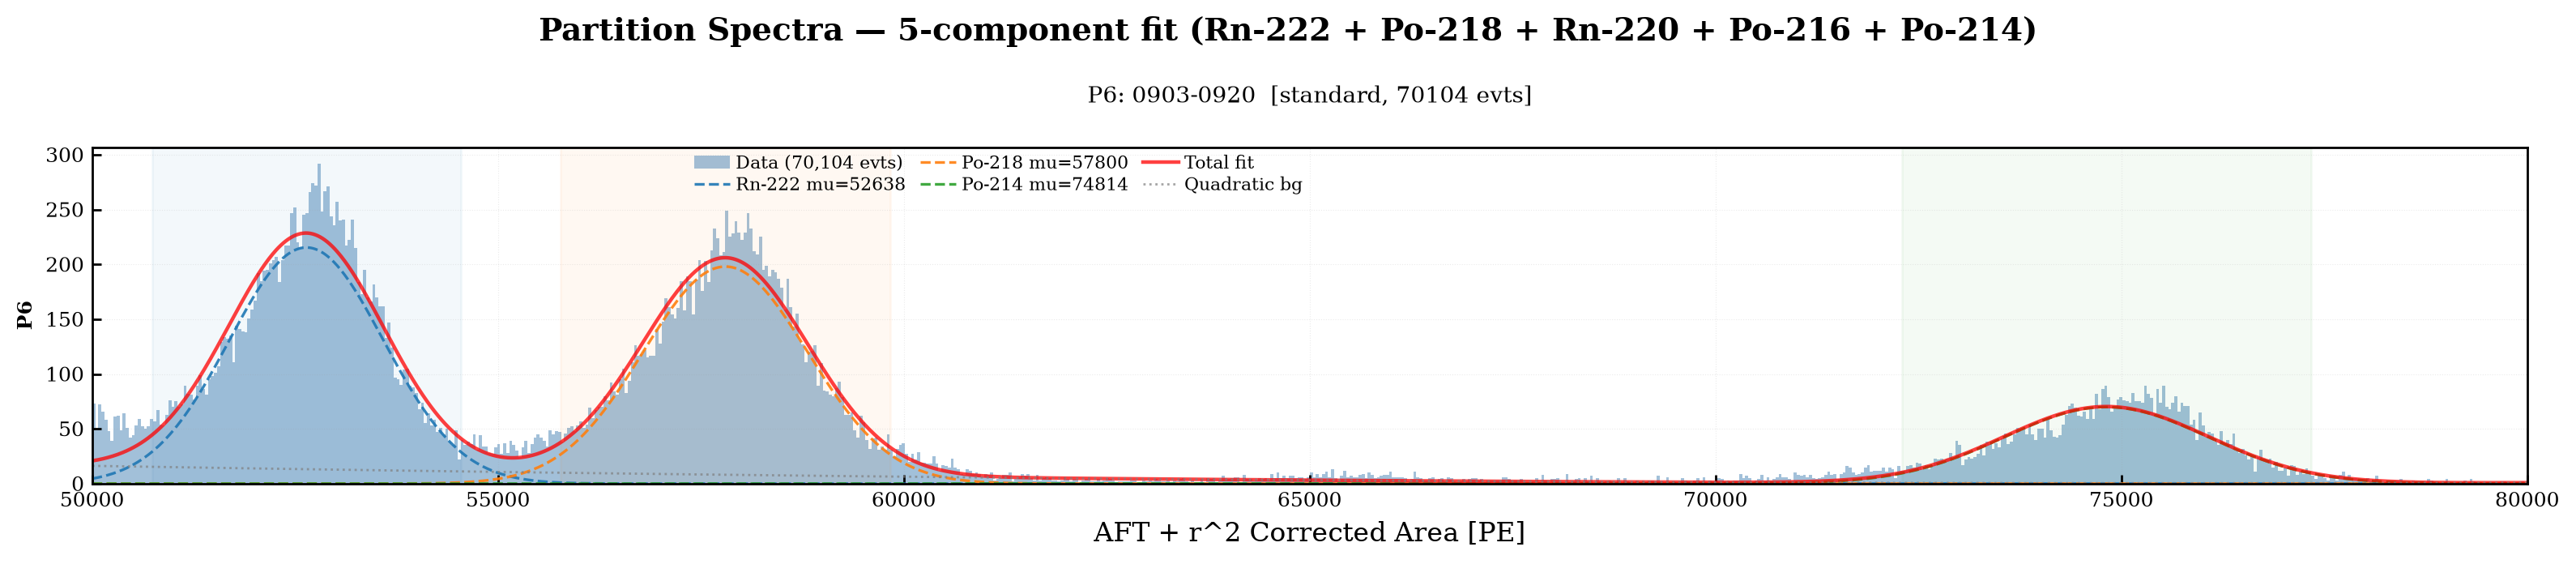

In [141]:
# ═══════════════════════════════════════════════════════════════
# FIT EACH PARTITION  +  PLOT SPECTRA
# ═══════════════════════════════════════════════════════════════
partition_fits = {}
for pname, t0, t1 in PARTITIONS:
    t0_ns, t1_ns = int(t0*1e9), int(t1*1e9)
    evts = rn_events[(rn_events['time'] >= t0_ns) & (rn_events['time'] < t1_ns)]
    partition_fits[pname] = fit_partition(evts, pname)
print('\nDone.')

n_part = len(PARTITIONS)
fig, axes = plt.subplots(n_part, 1, figsize=(16, 3.5*n_part), sharex=True)
if n_part == 1:
    axes = [axes]
x_fine = np.linspace(FIT_RANGE[0], FIT_RANGE[1], 2000)
colors = {name: plt.cm.tab10(k) for k, name in enumerate(FIT_COMPONENTS)}

for ax, (pname, t0, t1) in zip(axes, PARTITIONS):
    t0_ns, t1_ns = int(t0*1e9), int(t1*1e9)
    evts = rn_events[(rn_events['time'] >= t0_ns) & (rn_events['time'] < t1_ns)]
    res = partition_fits.get(pname)
    # IMPORTANT: data must use the SAME binning as the fit, otherwise the model
    # curve (counts per fit-bin) is compared against data with a wider bin.
    n_bins = res['n_bins'] if (res and res['success']) else min(800, max(200, len(evts)//10))
    ax.hist(evts['area_2_corrected'], bins=n_bins, range=FIT_RANGE,
            color='steelblue', alpha=0.5, label=f'Data ({len(evts):,} evts)')

    if res and res['success']:
        p = res['p_fit']
        amps, mus, sigs = res['fit_amps'], res['fit_mu'], res['fit_sigmas']
        for k, name in enumerate(FIT_COMPONENTS):
            is_sig = name in SIGNAL_NAMES
            ax.plot(x_fine, _gauss(x_fine, amps[k], mus[k], sigs[k]), '--',
                    color=colors[name], lw=1.2, alpha=0.9 if is_sig else 0.55,
                    label=f'{name} mu={mus[k]:.0f}')
            if is_sig:
                ax.axvspan(mus[k] - 2*sigs[k], mus[k] + 2*sigs[k],
                           color=colors[name], alpha=0.05)
        y_tot = _bg(x_fine, p[-3], p[-2], p[-1])
        for k in range(N_PEAKS):
            y_tot = y_tot + _gauss(x_fine, amps[k], mus[k], sigs[k])
        ax.plot(x_fine, y_tot, 'r-', lw=1.6, alpha=0.75, label='Total fit')
        ax.plot(x_fine, _bg(x_fine, p[-3], p[-2], p[-1]), 'gray', lw=1, ls=':', alpha=0.7,
                label='Quadratic bg')
        ax.set_title('%s  [%s, %d evts]' % (pname, res['method'], res['n_ev']),
                     fontsize=10, pad=20)
    else:
        ax.set_title('%s  [FIT FAILED]' % pname, fontsize=10, pad=20)

    ax.set_ylabel(pname.split(':')[0], fontsize=9, fontweight='bold')
    ax.legend(fontsize=8, loc='upper right', ncol=3)
    ax.grid(True, alpha=0.2)
    ax.set_xlim(FIT_RANGE)

axes[-1].set_xlabel('AFT + r^2 Corrected Area [PE]', fontsize=12)
fig.suptitle('Partition Spectra — 5-component fit '
             '(Rn-222 + Po-218 + Rn-220 + Po-216 + Po-214)',
             fontsize=14, fontweight='bold')
safe_tight(fig)
plt.show()


---
## 9. Per-run fit (fitted-mu / yield trend only)

These per-run fits are **not** used for the rate — they only feed the
fitted-mu (light-yield stability) trend in Section 12.

In [142]:
# ═══════════════════════════════════════════════════════════════
# BATCH PER-RUN FIT  (small-peak shapes fixed from the partition fit)
# ═══════════════════════════════════════════════════════════════

def fit_all_runs_v2(runs_df, events_df, rn222_ref=RN222_REF):
    rows  = []
    stats = {}
    fixed_names = [nm for nm in ('Rn-220', 'Po-216') if nm in FIT_COMPONENTS]
    for idx, (_, run) in enumerate(runs_df.iterrows()):
        name = run['name']
        t0 = int(run['start_s'] * 1e9)
        t1 = int(float(run['end'].timestamp()) * 1e9)
        evts = events_df[(events_df['time'] >= t0) & (events_df['time'] < t1)]

        pname = assign_partition(run['start_s'])
        pfit  = partition_fits.get(pname) if pname is not None else None
        fixed = None
        if pfit and pfit['success']:
            fixed = {}
            for nm in fixed_names:
                k = FIT_COMPONENTS.index(nm)
                fixed[nm] = (pfit['fit_mu'][k], pfit['fit_sigmas'][k])

        res = fit_one_run_v2(evts, label=name, rn222_ref=rn222_ref, fixed_shapes=fixed)

        row = {'run': name, 'n_events': res['n_events'],
               'success': res['success'], 'status': res['status'],
               'method': res['method'], 'scale_guess_pe': res['scale_pe']}
        for i, iso in enumerate(FIT_COMPONENTS):
            row[f'fit_mu_{iso}']    = res['fit_mu'][i]     if res['fit_mu']     is not None else np.nan
            row[f'fit_sigma_{iso}'] = res['fit_sigmas'][i] if res['fit_sigmas'] is not None else np.nan
        rows.append(row)
        stats[res['status']] = stats.get(res['status'], 0) + 1
        if (idx + 1) % 20 == 0 or idx == 0:
            print(f'  [{idx+1}/{len(runs_df)}] {name}  '
                  f'{res["n_events"]:4d} evts  {res["status"]}  [{res["method"]}]')

    df = pd.DataFrame(rows)
    n_ok = df['success'].sum()
    print(f"\n{'='*60}")
    print(f"  FIT SUMMARY: {n_ok}/{len(df)} runs ({100*n_ok/len(df):.1f}%)")
    print(f"{'='*60}")
    for st in sorted(stats):
        print(f"  {st:30s}  {stats[st]:4d}")
    print(f"{'='*60}")
    return df

print('fit_all_runs_v2() defined.')


fit_all_runs_v2() defined.


In [143]:
df_fits = fit_all_runs_v2(runs_sr3, rn_events, rn222_ref=RN222_REF)

  [1/403] 087192    56 evts  success  [free_smallfixed]
  [20/403] 087093   196 evts  success  [free_smallfixed]
  [40/403] 087057    16 evts  too_few_events(16)  [None]
  [60/403] 087030    92 evts  success  [free_smallfixed]
  [80/403] 087000    74 evts  success  [free_smallfixed]
  [100/403] 086975   142 evts  success  [free_smallfixed]
  [120/403] 086939   208 evts  success  [free_smallfixed]
  [140/403] 086905   241 evts  success  [free_smallfixed]
  [160/403] 086869   183 evts  success  [free_smallfixed]
  [180/403] 086834   211 evts  success  [free_smallfixed]
  [200/403] 086798   173 evts  success  [free_smallfixed]
  [220/403] 086734    88 evts  success  [free_smallfixed]
  [240/403] 086697   194 evts  success  [free_smallfixed]
  [260/403] 086677   188 evts  success  [free_smallfixed]
  [280/403] 086657   214 evts  success  [free_smallfixed]
  [300/403] 086636   220 evts  success  [free_smallfixed]
  [320/403] 086613   186 evts  success  [free_smallfixed]
  [340/403] 086577  

In [144]:
runs_sr3_indexed = runs_sr3.assign(name=runs_sr3['name'].astype(str)).set_index('name')
df_fits['start_s'] = df_fits['run'].map(runs_sr3_indexed['start_s'])
df_fits['partition'] = df_fits['start_s'].apply(assign_partition)

print('Run counts per partition:')
print(df_fits['partition'].value_counts().sort_index())

Run counts per partition:
partition
P6: 0903-0920    403
Name: count, dtype: int64


In [145]:
# ═══════════════════════════════════════════════════════════════
# PLOT SINGLE RUN
# ═══════════════════════════════════════════════════════════════

def plot_run_fit(run_name):
    n_bins = 100  # fixed, reliable
    fig, ax = plt.subplots(figsize=(14, 6))
    err = None

    # Get events
    rrow = runs_sr3[runs_sr3['name'] == run_name]
    if len(rrow) == 0:
        err = f'Run {run_name} not found'
    else:
        rrow = rrow.iloc[0]
        t0 = int(rrow['start_s'] * 1e9)
        t1 = int(float(rrow['end'].timestamp()) * 1e9)
        evts = rn_events[(rn_events['time'] >= t0) & (rn_events['time'] < t1)]
        n_ev = len(evts)

        if n_ev == 0:
            err = f'Run {run_name}: 0 events'
        else:
            hc, he, _ = ax.hist(evts['area_2_corrected'], bins=n_bins, range=FIT_RANGE,
                                color='steelblue', alpha=0.5, label=f'Data ({n_ev} evts)')
            y_hi = hc.max() * 1.6

            fr = df_fits[df_fits['run'] == run_name]
            if len(fr) > 0:
                fr = fr.iloc[0]
                success = fr['success']
                method  = fr['method']
            else:
                success, method = False, None

            if success:
                bc = 0.5 * (he[:-1] + he[1:])
                cmap = plt.cm.tab10
                xf = np.linspace(FIT_RANGE[0], FIT_RANGE[1], 2000)
                for i, name in enumerate(FIT_COMPONENTS):
                    mu = fr[f'fit_mu_{name}']
                    sig = fr[f'fit_sigma_{name}']
                    if np.isnan(mu) or np.isnan(sig):
                        continue
                    idx = np.argmin(np.abs(bc - mu))
                    amp_vis = min(hc[idx] if idx < len(hc) else y_hi*0.3, y_hi) * 1.05
                    g = amp_vis * np.exp(-0.5 * ((xf - mu) / sig)**2)
                    ax.plot(xf, g, '--', color=cmap(i), lw=1.5, alpha=0.8,
                            label=f'{name} μ={mu:.0f}')
                    ax.axvspan(mu - 2*sig, mu + 2*sig, color=cmap(i), alpha=0.06)

            status = fr.get('status', 'N/A') if 'fr' in dir() else 'N/A'
            ok_str = 'OK' if success else 'FAILED'
            ax.set_title(f'Run {run_name}  |  {ok_str} ({status})  |  method: {method}  |  {n_ev} events', fontsize=13)
            ax.set_ylim(0, y_hi)

    if err:
        print(err); return

    ax.set_xlabel('AFT + r² Corrected Area [PE]', fontsize=12)
    ax.set_ylabel('Counts/bin', fontsize=12)
    ax.legend(fontsize=7, ncol=2, loc='upper right')
    ax.grid(True, alpha=0.3)
    safe_tight(fig)
    plt.show()


print('plot_run_fit() defined.')
print('Usage: plot_run_fit("080510")')


plot_run_fit() defined.
Usage: plot_run_fit("080510")


/scratch/local/jobs/62007437/ipykernel_2989757/2144198239.py:26: UserWarning: The figure layout has changed to tight
  try: (fig or plt).tight_layout()


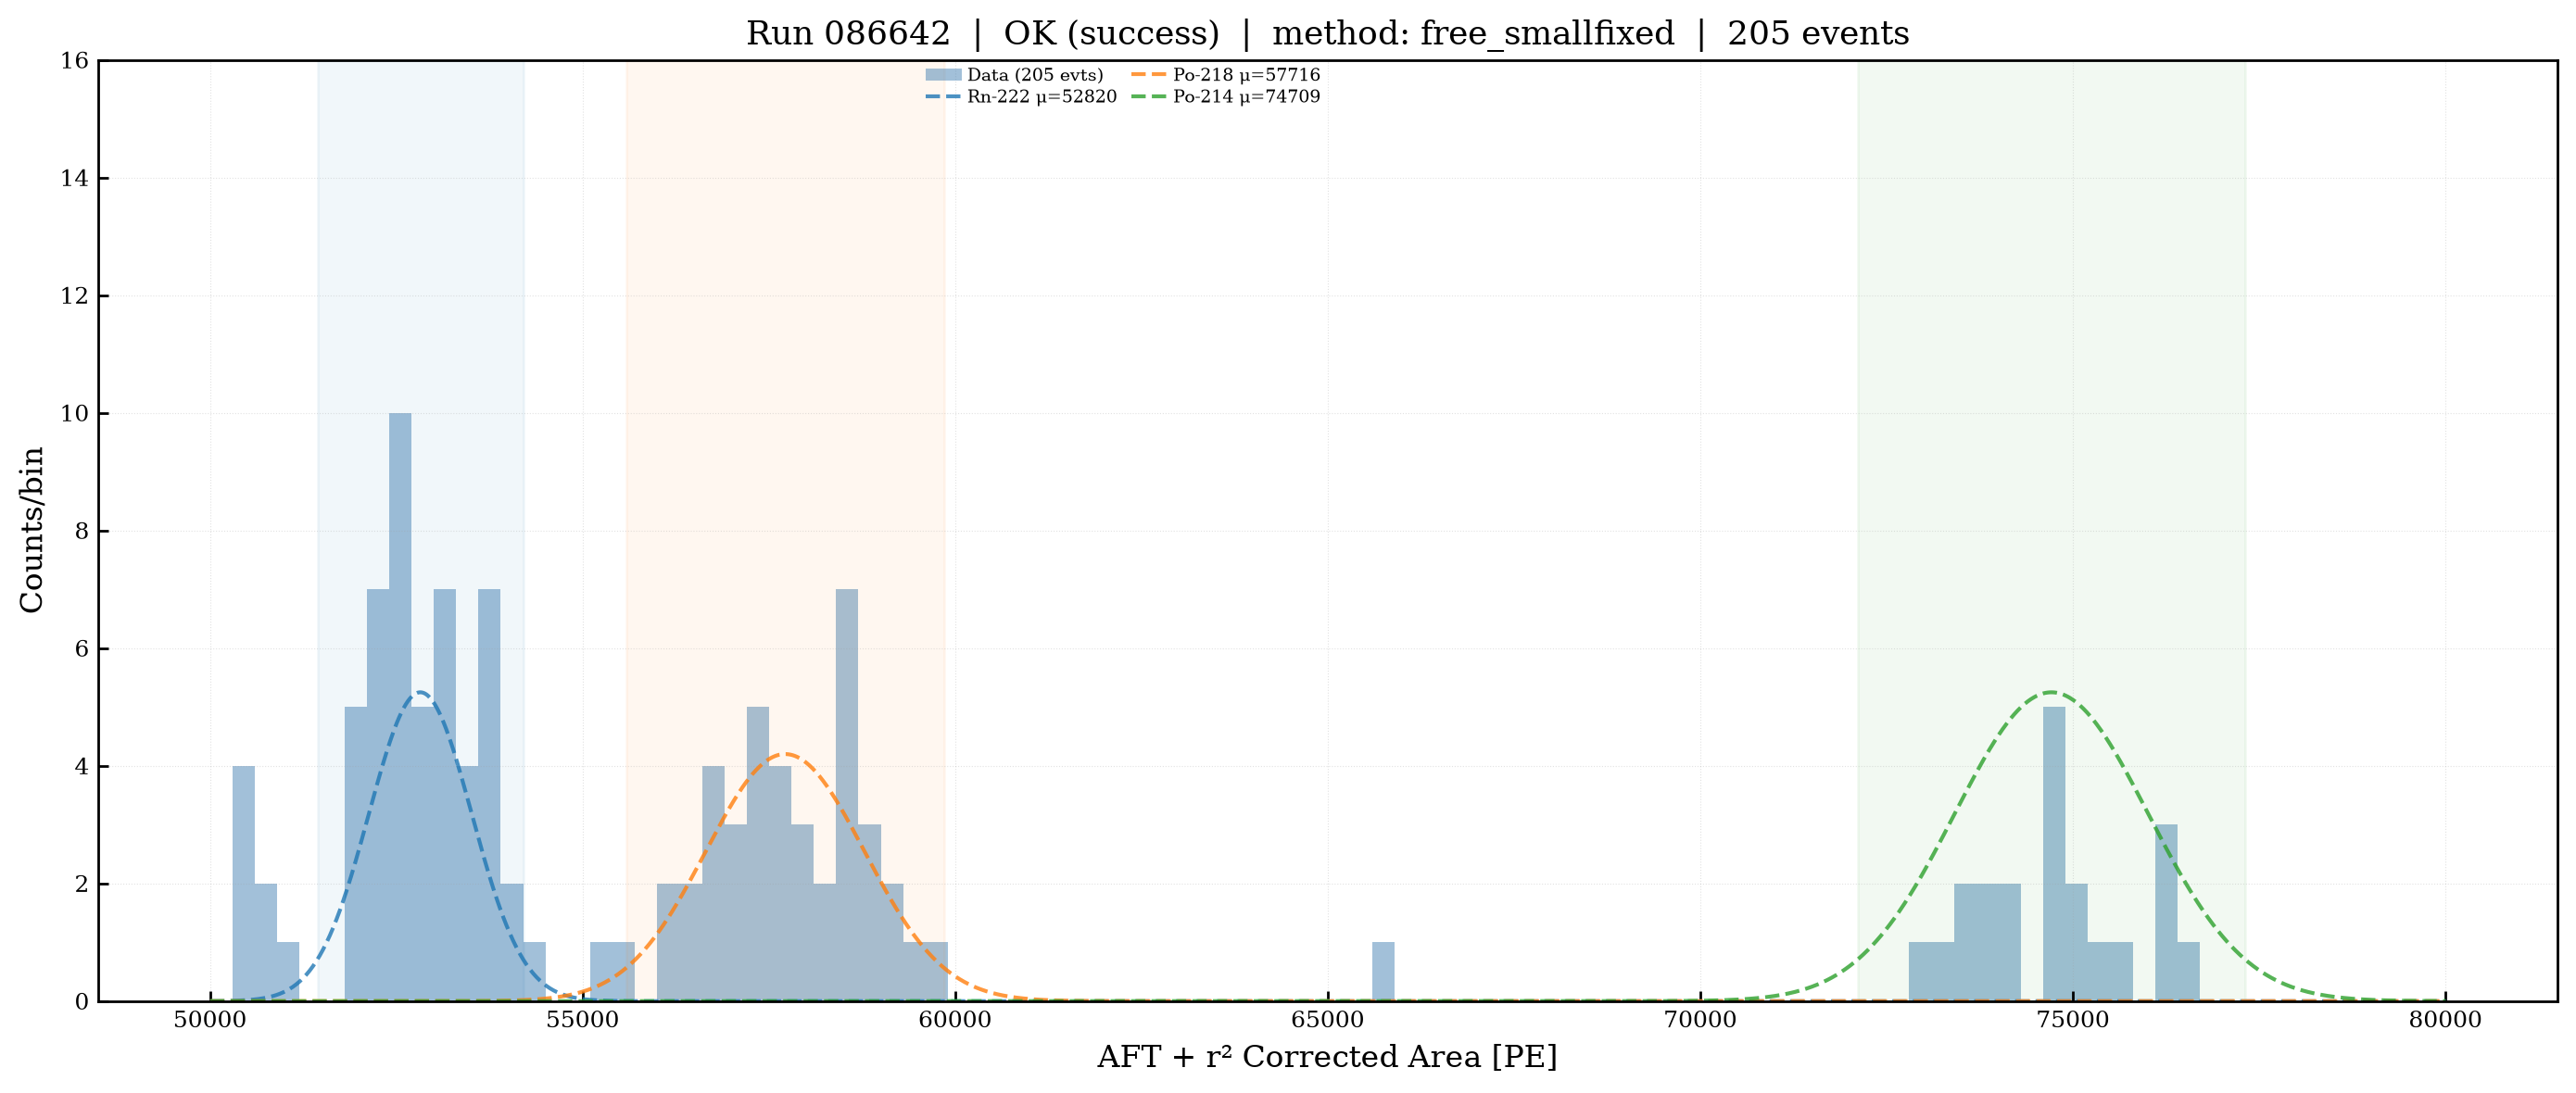

In [146]:
ok_runs = df_fits[df_fits['success']]['run'].values
if len(ok_runs) > 0:
    plot_run_fit(np.random.choice(ok_runs))

---
## 10. M2 rate extraction

Events counted per run in a ±N_SIGMA window around the **partition-fit** mu/sigma.
Only M2 is used for the rate.

In [147]:
# ═══════════════════════════════════════════════════════════════
# WINDOW HELPER — standard ±2σ (3 peaks, no overlap)
# ═══════════════════════════════════════════════════════════════

def _get_window(peak_idx, mu_i, sig_i, all_mu):
    return mu_i - 2.0 * sig_i, mu_i + 2.0 * sig_i

print('_get_window(): ±2σ (3 peaks, no overlap)')


_get_window(): ±2σ (3 peaks, no overlap)


In [148]:
# Ensure df_fits has start_s + partition
df_fits['start_s'] = df_fits['run'].map(runs_sr3_indexed['start_s'])
df_fits['partition'] = df_fits['start_s'].apply(assign_partition)

results_m2 = []
for _, row in df_fits.iterrows():
    run_name = row['run']
    pname = row['partition']
    if pname is None: continue
    pfit = partition_fits.get(pname)
    if not pfit or not pfit['success']: continue
    rrow = runs_sr3[runs_sr3['name'] == run_name]
    if len(rrow) == 0: continue
    rrow = rrow.iloc[0]
    t0 = int(rrow['start_s'] * 1e9)
    t1 = int(float(rrow['end'].timestamp()) * 1e9)
    lt = rrow.get('duration', t1/1e9 - t0/1e9)
    evts = rn_events[(rn_events['time'] >= t0) & (rn_events['time'] < t1)]
    for i in SIGNAL_IDX:
        name = FIT_COMPONENTS[i]
        mu, sig = pfit['fit_mu'][i], pfit['fit_sigmas'][i]
        lo, hi = _get_window(i, mu, sig, pfit['fit_mu'])
        n = ((evts['area_2_corrected'] >= lo) & (evts['area_2_corrected'] <= hi)).sum()
        results_m2.append({
            'run': run_name, 'start_s': rrow['start_s'],
            'end_s': float(rrow['end'].timestamp()), 'livetime_s': lt,
            'isotope': name, 'n_events': n, 'partition': pname,
            'rate_ukgb': n/lt*1e6/FMASS,
            'rate_err_ukgb': np.sqrt(max(n,1))/lt*1e6/FMASS})

df_m2 = pd.DataFrame(results_m2)
print(f'M2 rates: {len(df_m2)} rows ({df_m2["run"].nunique()} runs x {len(SIGNAL_NAMES)} isotopes)')


M2 rates: 1209 rows (403 runs x 3 isotopes)


In [149]:
df_combined = df_m2
print('M2 rates: %d rows, %d runs' % (len(df_m2), df_m2['run'].nunique()))
print(df_m2['partition'].value_counts().sort_index())


M2 rates: 1209 rows, 403 runs
partition
P6: 0903-0920    1209
Name: count, dtype: int64


---
## 11. N_BINS uniform time-bin rate

Model-independent rate using the partition-fit mu/sigma. `N_BINS` is set in CONFIG.

#### Parameters (edit here before running this section)


In [150]:
# Number of uniform time bins for the time-binned rate + trend plots
N_BINS = 200

print('N_BINS (time bins) =', N_BINS)


N_BINS (time bins) = 200


In [151]:
# ═══════════════════════════════════════════════════════════════
# N_BINS UNIFORM TIME-BIN RATE (partition-fit mu/sigma)
# ═══════════════════════════════════════════════════════════════
N_TIME_BINS = N_BINS
t_min_s = rn_events['time'].min() / 1e9
t_max_s = rn_events['time'].max() / 1e9
t_edges_s = np.linspace(t_min_s, t_max_s, N_TIME_BINS + 1)
t_centers_s = 0.5 * (t_edges_s[:-1] + t_edges_s[1:])
t_edges_ns = (t_edges_s * 1e9).astype(np.int64)
bin_width_s = t_edges_s[1] - t_edges_s[0]

print('%d time bins, %.1f h each' % (N_TIME_BINS, bin_width_s/3600))
print('Range: ' + datetime.fromtimestamp(t_min_s, tz=timezone.utc).strftime('%m/%d') + ' - ' + datetime.fromtimestamp(t_max_s, tz=timezone.utc).strftime('%m/%d'))

def extract_tbin(data_evts, data_fits):
    rows = []
    for pname, t0_s, t1_s in PARTITIONS:
        pfit = data_fits.get(pname)
        if not pfit or not pfit['success']: continue
        for i in SIGNAL_IDX:
            name = FIT_COMPONENTS[i]
            mu, sig = pfit['fit_mu'][i], pfit['fit_sigmas'][i]
            lo, hi = _get_window(i, mu, sig, pfit['fit_mu'])
            mask = (data_evts['area_2_corrected'] >= lo) & (data_evts['area_2_corrected'] <= hi)
            t_sel = data_evts.loc[mask, 'time'].values
            t0_ns, t1_ns = int(t0_s*1e9), int(t1_s*1e9)
            t_sel = t_sel[(t_sel >= t0_ns) & (t_sel < t1_ns)]
            counts, _ = np.histogram(t_sel, bins=t_edges_ns)
            rate = counts / bin_width_s * 1e6 / FMASS
            rerr = np.sqrt(np.maximum(counts, 1)) / bin_width_s * 1e6 / FMASS
            for j in range(N_TIME_BINS):
                rows.append({
                    't_center_s': t_centers_s[j], 'isotope': name,
                    'n_events': int(counts[j]),
                    'rate_ukgb': rate[j], 'rate_err_ukgb': rerr[j]})
    return rows

tbin_rows = extract_tbin(rn_events, partition_fits)
df_t500 = pd.DataFrame(tbin_rows)
df_tbin = df_t500
print('Time-binned rates: %d rows' % len(df_t500))


200 time bins, 1.9 h each
Range: 09/03 - 09/19
Time-binned rates: 600 rows


/scratch/local/jobs/62007437/ipykernel_2989757/2144198239.py:26: UserWarning: The figure layout has changed to tight
  try: (fig or plt).tight_layout()


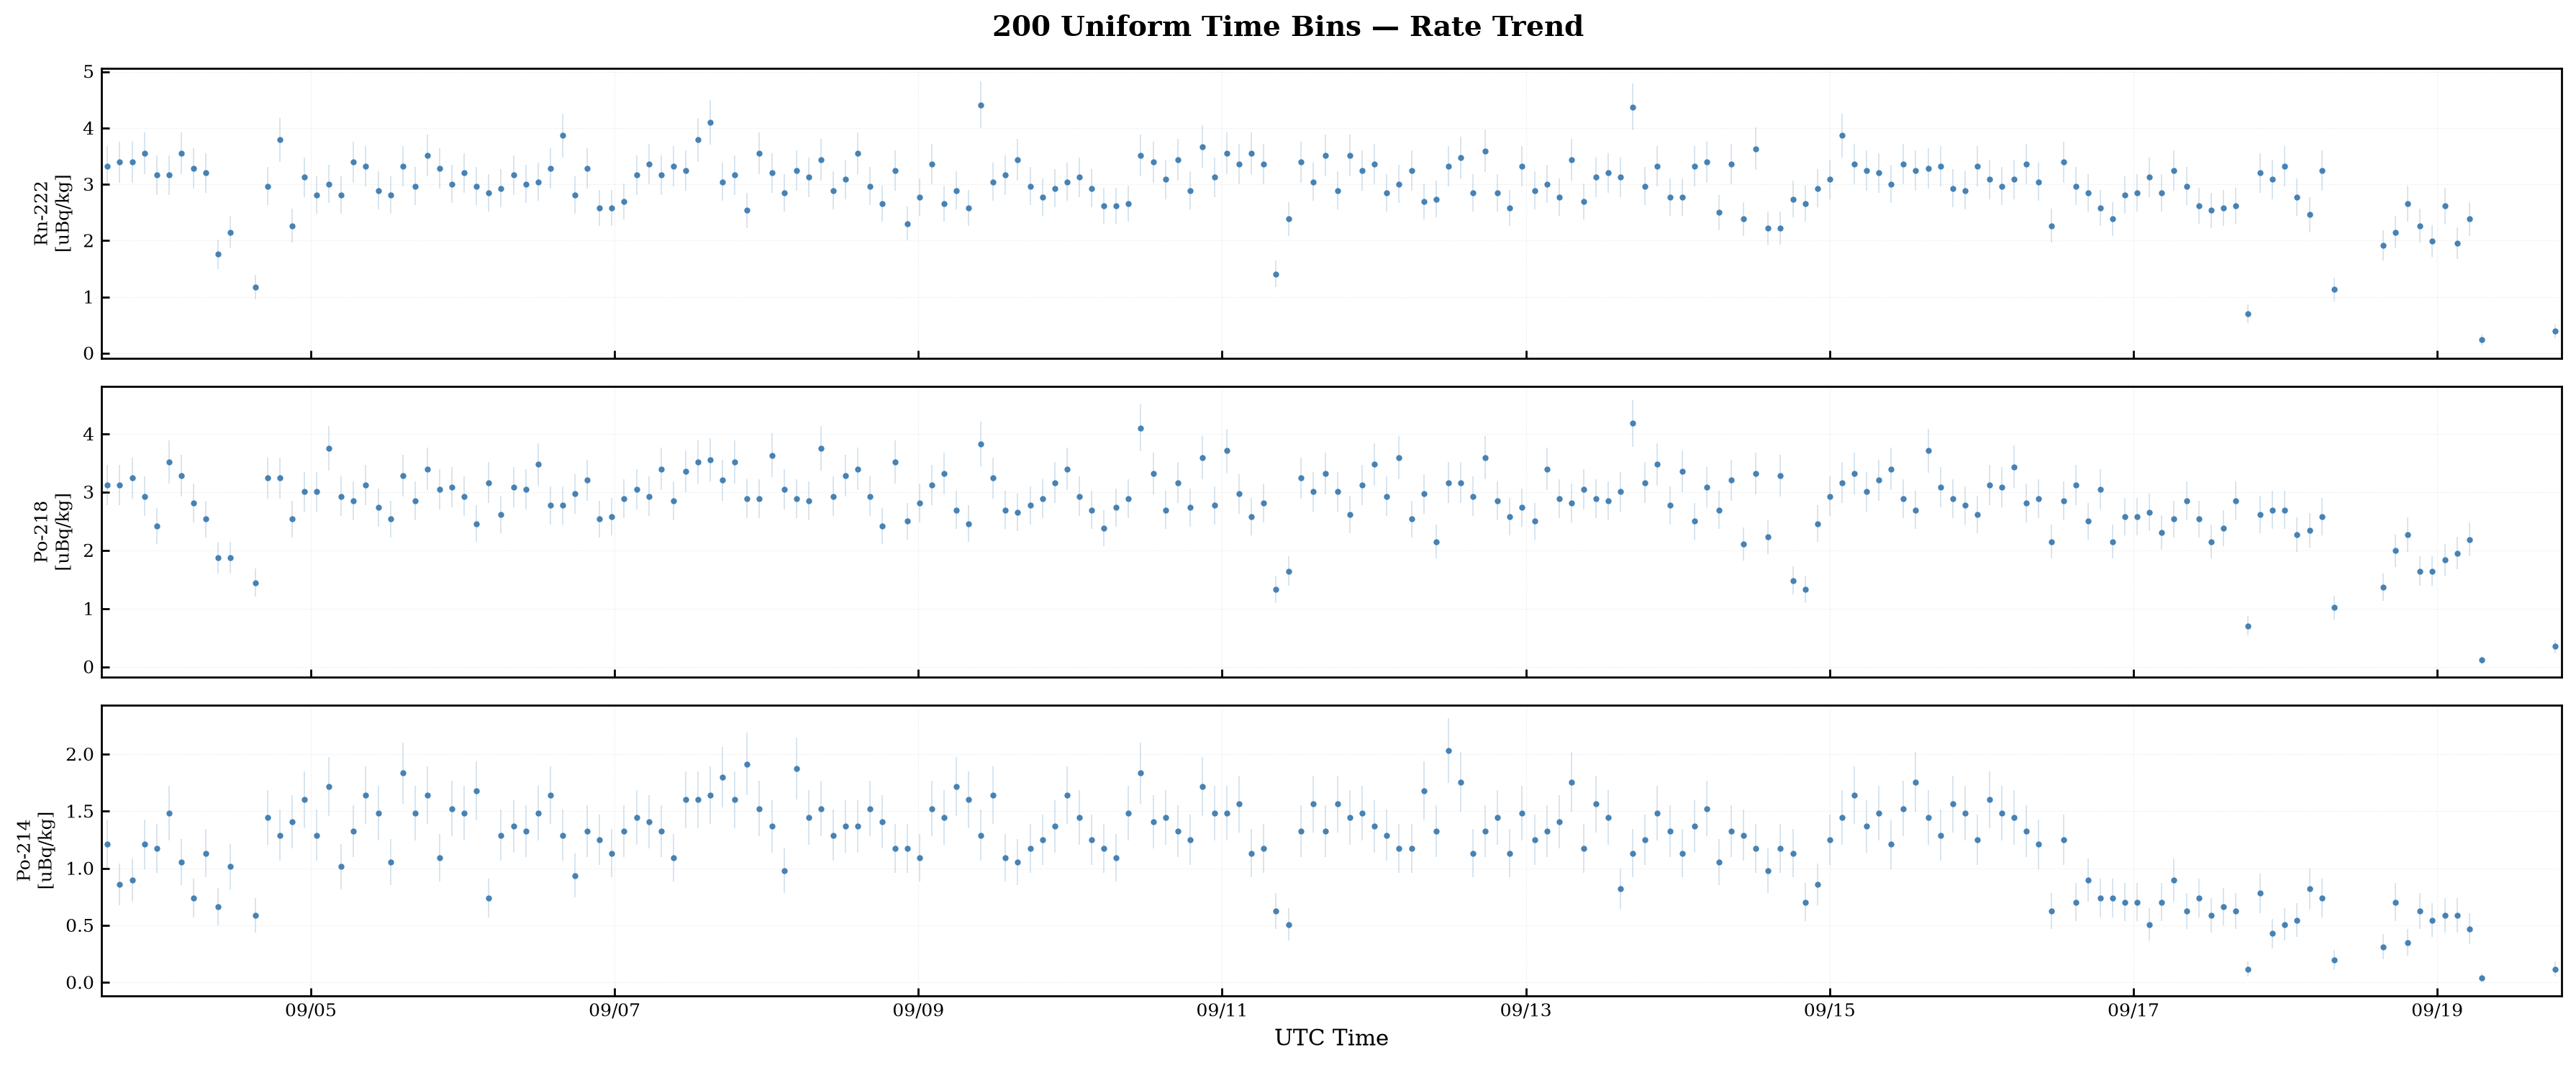

In [152]:
# N_BINS-BIN SCATTER — single dataset + vlines (error bars kept)

fig, axes = plt.subplots(len(SIGNAL_NAMES), 1, figsize=(18, 2.5*len(SIGNAL_NAMES)), sharex=True)
if len(SIGNAL_NAMES) == 1: axes = [axes]
for ax, name in zip(axes, SIGNAL_NAMES):
    di = df_t500[(df_t500['isotope'] == name) & (df_t500['rate_ukgb'] > 0)]
    if len(di) == 0: continue
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di['t_center_s']]
    ax.errorbar(np.array(sd), di['rate_ukgb'].values, yerr=di['rate_err_ukgb'].values,
                fmt='o', color='steelblue', markersize=2, capsize=0, lw=0.15)
    ax.set_ylabel(f'{name}\n[uBq/kg]', fontsize=9)
    ax.grid(True, alpha=0.25)
    add_partition_vlines(ax); add_event_vlines(ax)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel('UTC Time', fontsize=11)
axes[-1].set_xlim(DATA_XLIM)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('%d Uniform Time Bins — Rate Trend' % N_BINS, fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


/scratch/local/jobs/62007437/ipykernel_2989757/2144198239.py:26: UserWarning: The figure layout has changed to tight
  try: (fig or plt).tight_layout()


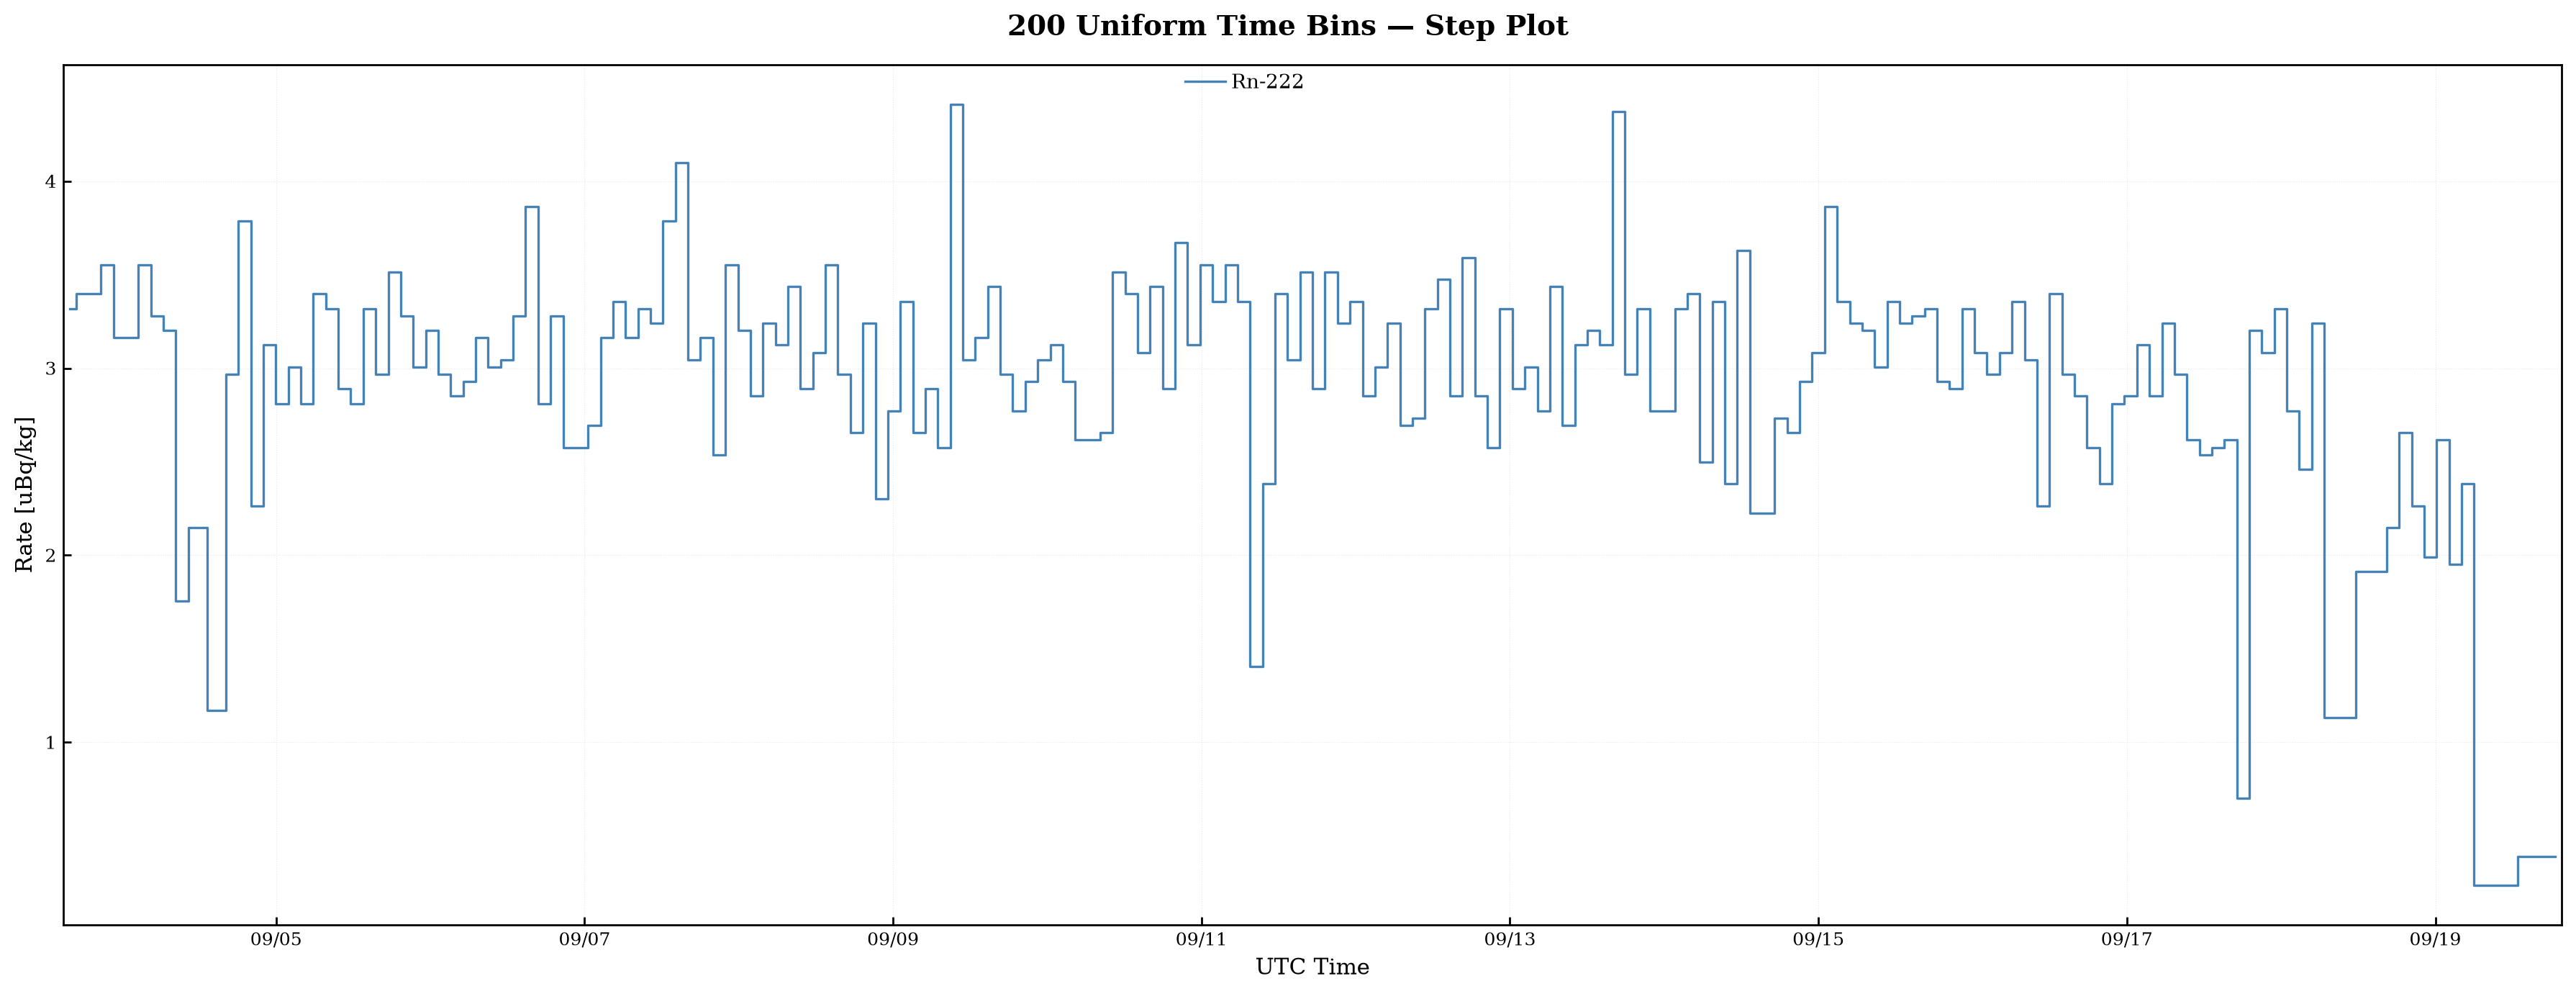

In [153]:
# N_BINS-BIN STEP — Rn-222, single continuous + vlines

PLOT_ISOTOPES = ['Rn-222']
iso_list = [n for n in PLOT_ISOTOPES if n in df_t500['isotope'].unique()]
fig, ax = plt.subplots(figsize=(18, 7))
for name in iso_list:
    combined = df_t500[(df_t500['isotope'] == name) & (df_t500['rate_ukgb'] > 0)].sort_values('t_center_s')
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in combined['t_center_s']]
    ax.step(sd, combined['rate_ukgb'].values, where='mid',
            color='steelblue', lw=1.2, label=name)

add_partition_vlines(ax)
add_event_vlines(ax)
ax.set_ylabel('Rate [uBq/kg]', fontsize=11)
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.25)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.set_xlabel('UTC Time', fontsize=11)
ax.set_xlim(DATA_XLIM)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('%d Uniform Time Bins — Step Plot' % N_BINS, fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


---
## 12. Trend plots & Po/Rn ratios

Rate trends, fitted-mu yield trend, and Po-218/Po-214 : Rn-222 ratios.

In [154]:
# fitted-mu (light yield) trend -- per-run fits only
df_fits_all = df_fits[df_fits['success']].copy().sort_values('start_s')
print('Combined fits: %d successful (%d runs)' % (len(df_fits_all), df_fits_all['run'].nunique()))

Combined fits: 372 successful (372 runs)


/scratch/local/jobs/62007437/ipykernel_2989757/2144198239.py:26: UserWarning: The figure layout has changed to tight
  try: (fig or plt).tight_layout()


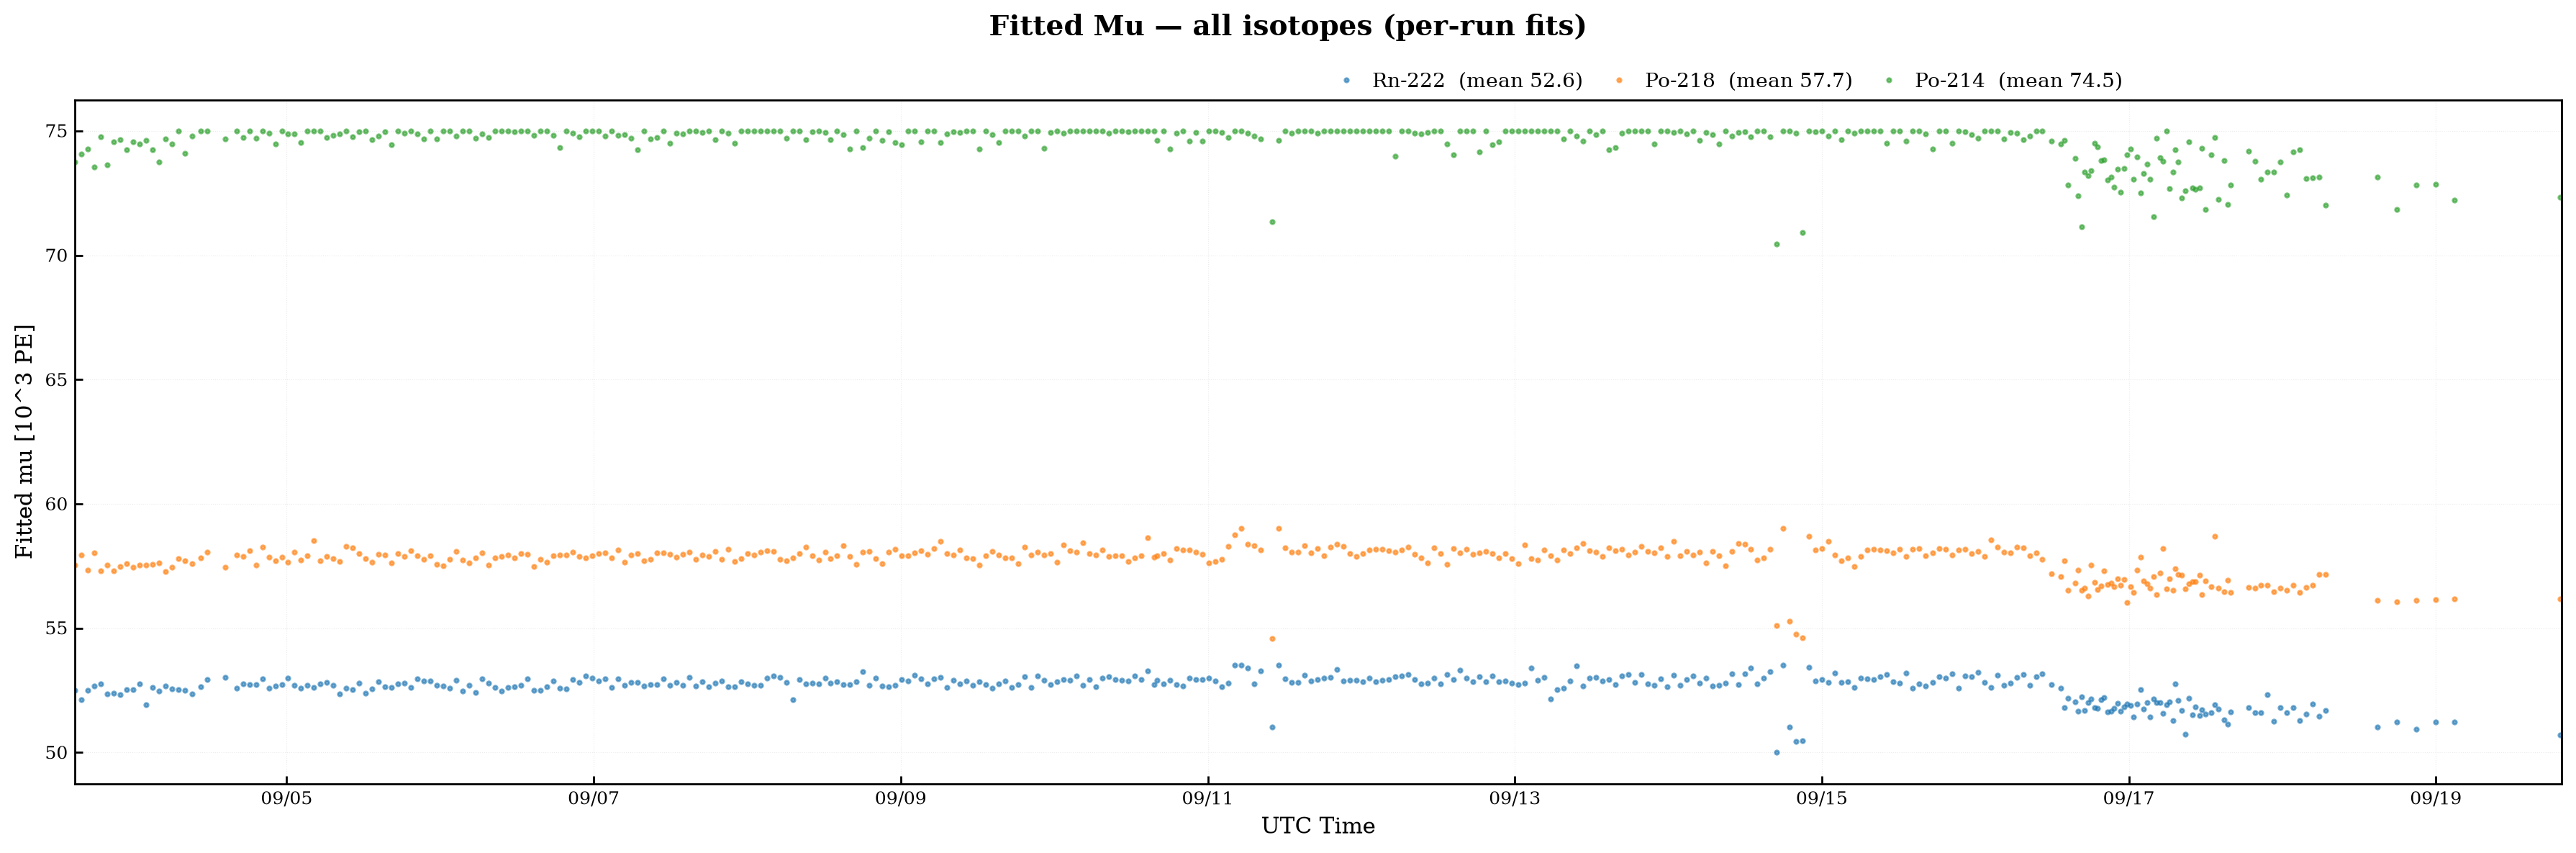

In [155]:
# FITTED Mu TREND — per-run fits, all three isotopes in ONE panel

ISOTOPE_COLORS = {'Rn-222': 'tab:blue', 'Po-218': 'tab:orange', 'Po-214': 'tab:green'}

fig, ax = plt.subplots(figsize=(18, 6))
for name in SIGNAL_NAMES:
    col = f'fit_mu_{name}'
    if col not in df_fits_all.columns:
        continue
    dp = df_fits_all.dropna(subset=[col]).sort_values('start_s')
    if len(dp) == 0:
        continue
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in dp['start_s']]
    ax.plot(np.array(sd), dp[col].values / 1e3, 'o', color=ISOTOPE_COLORS.get(name),
            markersize=2, alpha=0.6, label=f'{name}  (mean {dp[col].mean()/1e3:.1f})')

add_partition_vlines(ax)
add_event_vlines(ax)
ax.set_ylabel('Fitted mu [10^3 PE]', fontsize=11)
ax.legend(fontsize=10, loc='best', ncol=3)
ax.grid(True, alpha=0.2)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.set_xlabel('UTC Time', fontsize=11)
ax.set_xlim(DATA_XLIM)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Fitted Mu — all isotopes (per-run fits)', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


per-partition ratio means (values > 1.5 dropped):
  P6: 0903-0920                 Po-218/Rn-222 = 0.9501 +- 0.1318 (n=191)   Po-214/Rn-222 = 0.4039 +- 0.1118 (n=191)
total mean:  Po-218/Rn-222 = 0.9501   Po-214/Rn-222 = 0.4039


/scratch/local/jobs/62007437/ipykernel_2989757/2144198239.py:26: UserWarning: The figure layout has changed to tight
  try: (fig or plt).tight_layout()


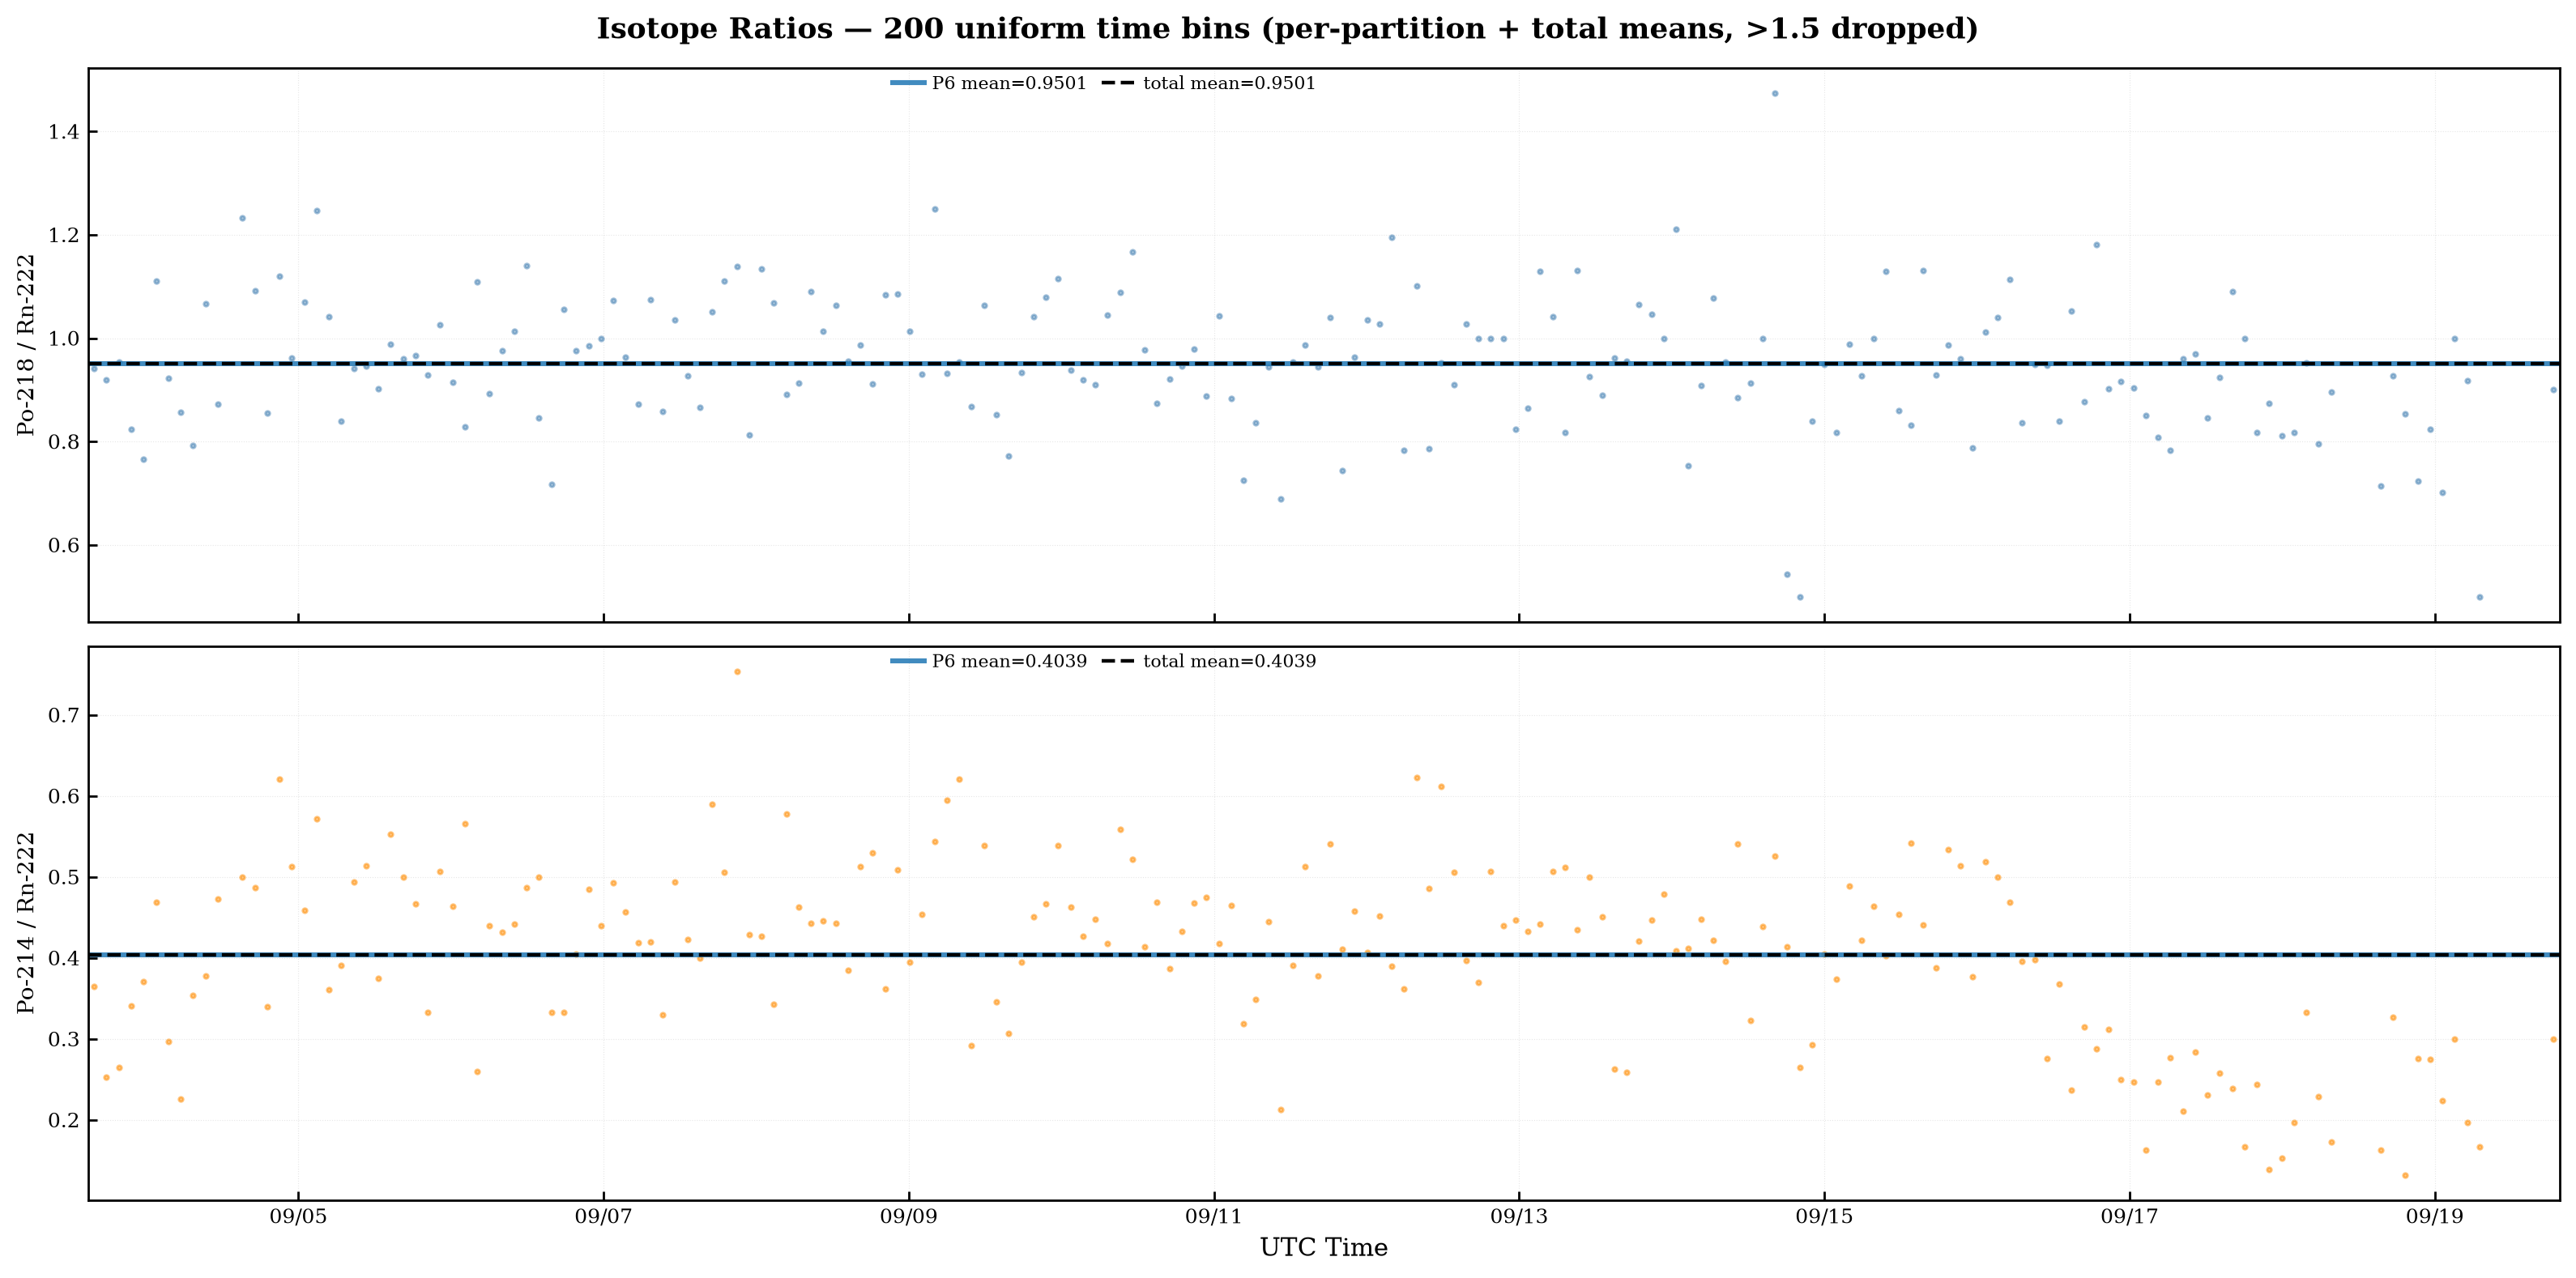

In [156]:
# Po-218/Rn-222 and Po-214/Rn-222 ratios — N_BINS uniform time bins
# Mean computed PER PARTITION, after dropping ratio values > RATIO_MAX.
# The legend also shows the total (all-partition) mean.

RATIO_MAX = 1.5

piv = (df_t500.pivot_table(index='t_center_s', columns='isotope',
                           values='rate_ukgb', aggfunc='sum').reset_index())
piv = piv.dropna(subset=['Rn-222', 'Po-218', 'Po-214'])
piv = piv[(piv['Rn-222'] > 0) & (piv['Po-218'] > 0) & (piv['Po-214'] > 0)]
piv['ratio_218_222'] = piv['Po-218'] / piv['Rn-222']
piv['ratio_214_222'] = piv['Po-214'] / piv['Rn-222']
piv['partition'] = piv['t_center_s'].apply(assign_partition)

PART_BOUNDS = {p[0]: (p[1], p[2]) for p in PARTITIONS}

# ---- per-partition mean (values > RATIO_MAX dropped) ----
print('per-partition ratio means (values > %.1f dropped):' % RATIO_MAX)
part_mean = {}
for pname in [p[0] for p in PARTITIONS]:
    sub = piv[piv['partition'] == pname]
    m1 = sub.loc[sub['ratio_218_222'] <= RATIO_MAX, 'ratio_218_222']
    m2 = sub.loc[sub['ratio_214_222'] <= RATIO_MAX, 'ratio_214_222']
    part_mean[pname] = {'ratio_218_222': m1.mean(), 'ratio_214_222': m2.mean()}
    print('  %-28s  Po-218/Rn-222 = %.4f +- %.4f (n=%d)   Po-214/Rn-222 = %.4f +- %.4f (n=%d)'
          % (pname, m1.mean(), m1.std(), len(m1), m2.mean(), m2.std(), len(m2)))

# ---- total mean (all partitions, values > RATIO_MAX dropped) ----
tot_mean = {
    'ratio_218_222': piv.loc[piv['ratio_218_222'] <= RATIO_MAX, 'ratio_218_222'].mean(),
    'ratio_214_222': piv.loc[piv['ratio_214_222'] <= RATIO_MAX, 'ratio_214_222'].mean(),
}
print('total mean:  Po-218/Rn-222 = %.4f   Po-214/Rn-222 = %.4f'
      % (tot_mean['ratio_218_222'], tot_mean['ratio_214_222']))

PART_COLORS = {p[0]: plt.cm.tab10(k) for k, p in enumerate(PARTITIONS)}
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for ax, col, lab, color in [(ax1, 'ratio_218_222', 'Po-218 / Rn-222', 'steelblue'),
                            (ax2, 'ratio_214_222', 'Po-214 / Rn-222', 'darkorange')]:
    dp = piv[piv[col] <= RATIO_MAX]
    if len(dp):
        sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in dp['t_center_s']]
        ax.plot(np.array(sd), dp[col].values, 'o', color=color, markersize=2, alpha=0.5)
    for pname in [p[0] for p in PARTITIONS]:
        mu = part_mean[pname][col]
        if np.isnan(mu):
            continue
        t0, t1 = PART_BOUNDS[pname]
        ax.hlines(mu, datetime.fromtimestamp(t0, tz=timezone.utc),
                  datetime.fromtimestamp(t1, tz=timezone.utc),
                  color=PART_COLORS[pname], lw=2.2, alpha=0.85,
                  label='%s mean=%.4f' % (pname.split(':')[0], mu))
    ax.axhline(tot_mean[col], color='k', ls='--', lw=1.6,
               label='total mean=%.4f' % tot_mean[col])
    ax.set_ylabel(lab, fontsize=10)
    ax.legend(fontsize=8, loc='upper right', ncol=2)
    ax.grid(True, alpha=0.25)
    add_partition_vlines(ax); add_event_vlines(ax)

ax2.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax2.xaxis.set_major_locator(mdates.AutoDateLocator())
ax2.set_xlabel('UTC Time', fontsize=11)
ax2.set_xlim(DATA_XLIM)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Isotope Ratios — %d uniform time bins (per-partition + total means, >%.1f dropped)' % (N_BINS, RATIO_MAX),
             fontsize=13, fontweight='bold')
safe_tight(fig); plt.show()


In [157]:
# ═══════════════════════════════════════════════════════════════
# SAVE THE NEW PER-RUN RESULTS
#   This notebook runs on Midway; the old trend (df_combined.csv) lives
#   locally.  Save the new per-run results here, download the file, and
#   merge it locally at the top of plot_full_rates.ipynb.
# ═══════════════════════════════════════════════════════════════
import os

TREND_OUT = 'trend_per_run_P6.csv'          # written next to this notebook on Midway
# TREND_OUT = '/project2/lgrandi/jietang/sr3_commissioning/trend_per_run_s1only.csv'

df_m2.sort_values(['run', 'isotope']).reset_index(drop=True).to_csv(TREND_OUT, index=False)
print('Wrote %s: %d rows, %d runs' % (TREND_OUT, len(df_m2), df_m2['run'].nunique()))


Wrote trend_per_run_P6.csv: 1209 rows, 403 runs


---
## Notes / things to tune

- **P6 band parameters** currently use the global defaults — tune `CORR1_PARAMS['P6: 0903-0920']` etc.
- **FV cut** is AFT [0.13, 0.46] and `r2_aft_corrected` < 50 cm² (set in Section 5).
- **`FIT_METHODS`** order sets which model is tried first (`standard`=free mu, `ratio`=ratio-constrained).
- Per-run fits (Section 9) exist **only** for the fitted-mu yield trend; the rate uses M2 only.

---
## Backup / Miscellaneous

Standalone cells that are **not part of the main workflow**. Run them on their own
when needed; they do not affect anything above.


### B1. P5 stability diagnostics — LY drift vs fit instability

Reads the already-computed per-run fits (`df_fits_all`) plus the raw pre-correction
sample (`df_peaks`) and produces:

1. per-run fitted $\mu$ vs time (marker size $\propto\sqrt{n_{events}}$),
2. fitted-$\mu$ **ratios** (a common LY drift cancels in the ratio),
3. a **raw, uncorrected** LY proxy (alpha peak position at fixed AFT),
4. the rolling median of the Rn-222 $\mu$ with per-run statistics, and prints
   **candidate breakpoints** where the rolling median moves by more than 1%.

Use the result to decide whether P5 needs to be split into sub-partitions.


/scratch/local/jobs/62007437/ipykernel_2989757/2144198239.py:26: UserWarning: The figure layout has changed to tight
  try: (fig or plt).tight_layout()


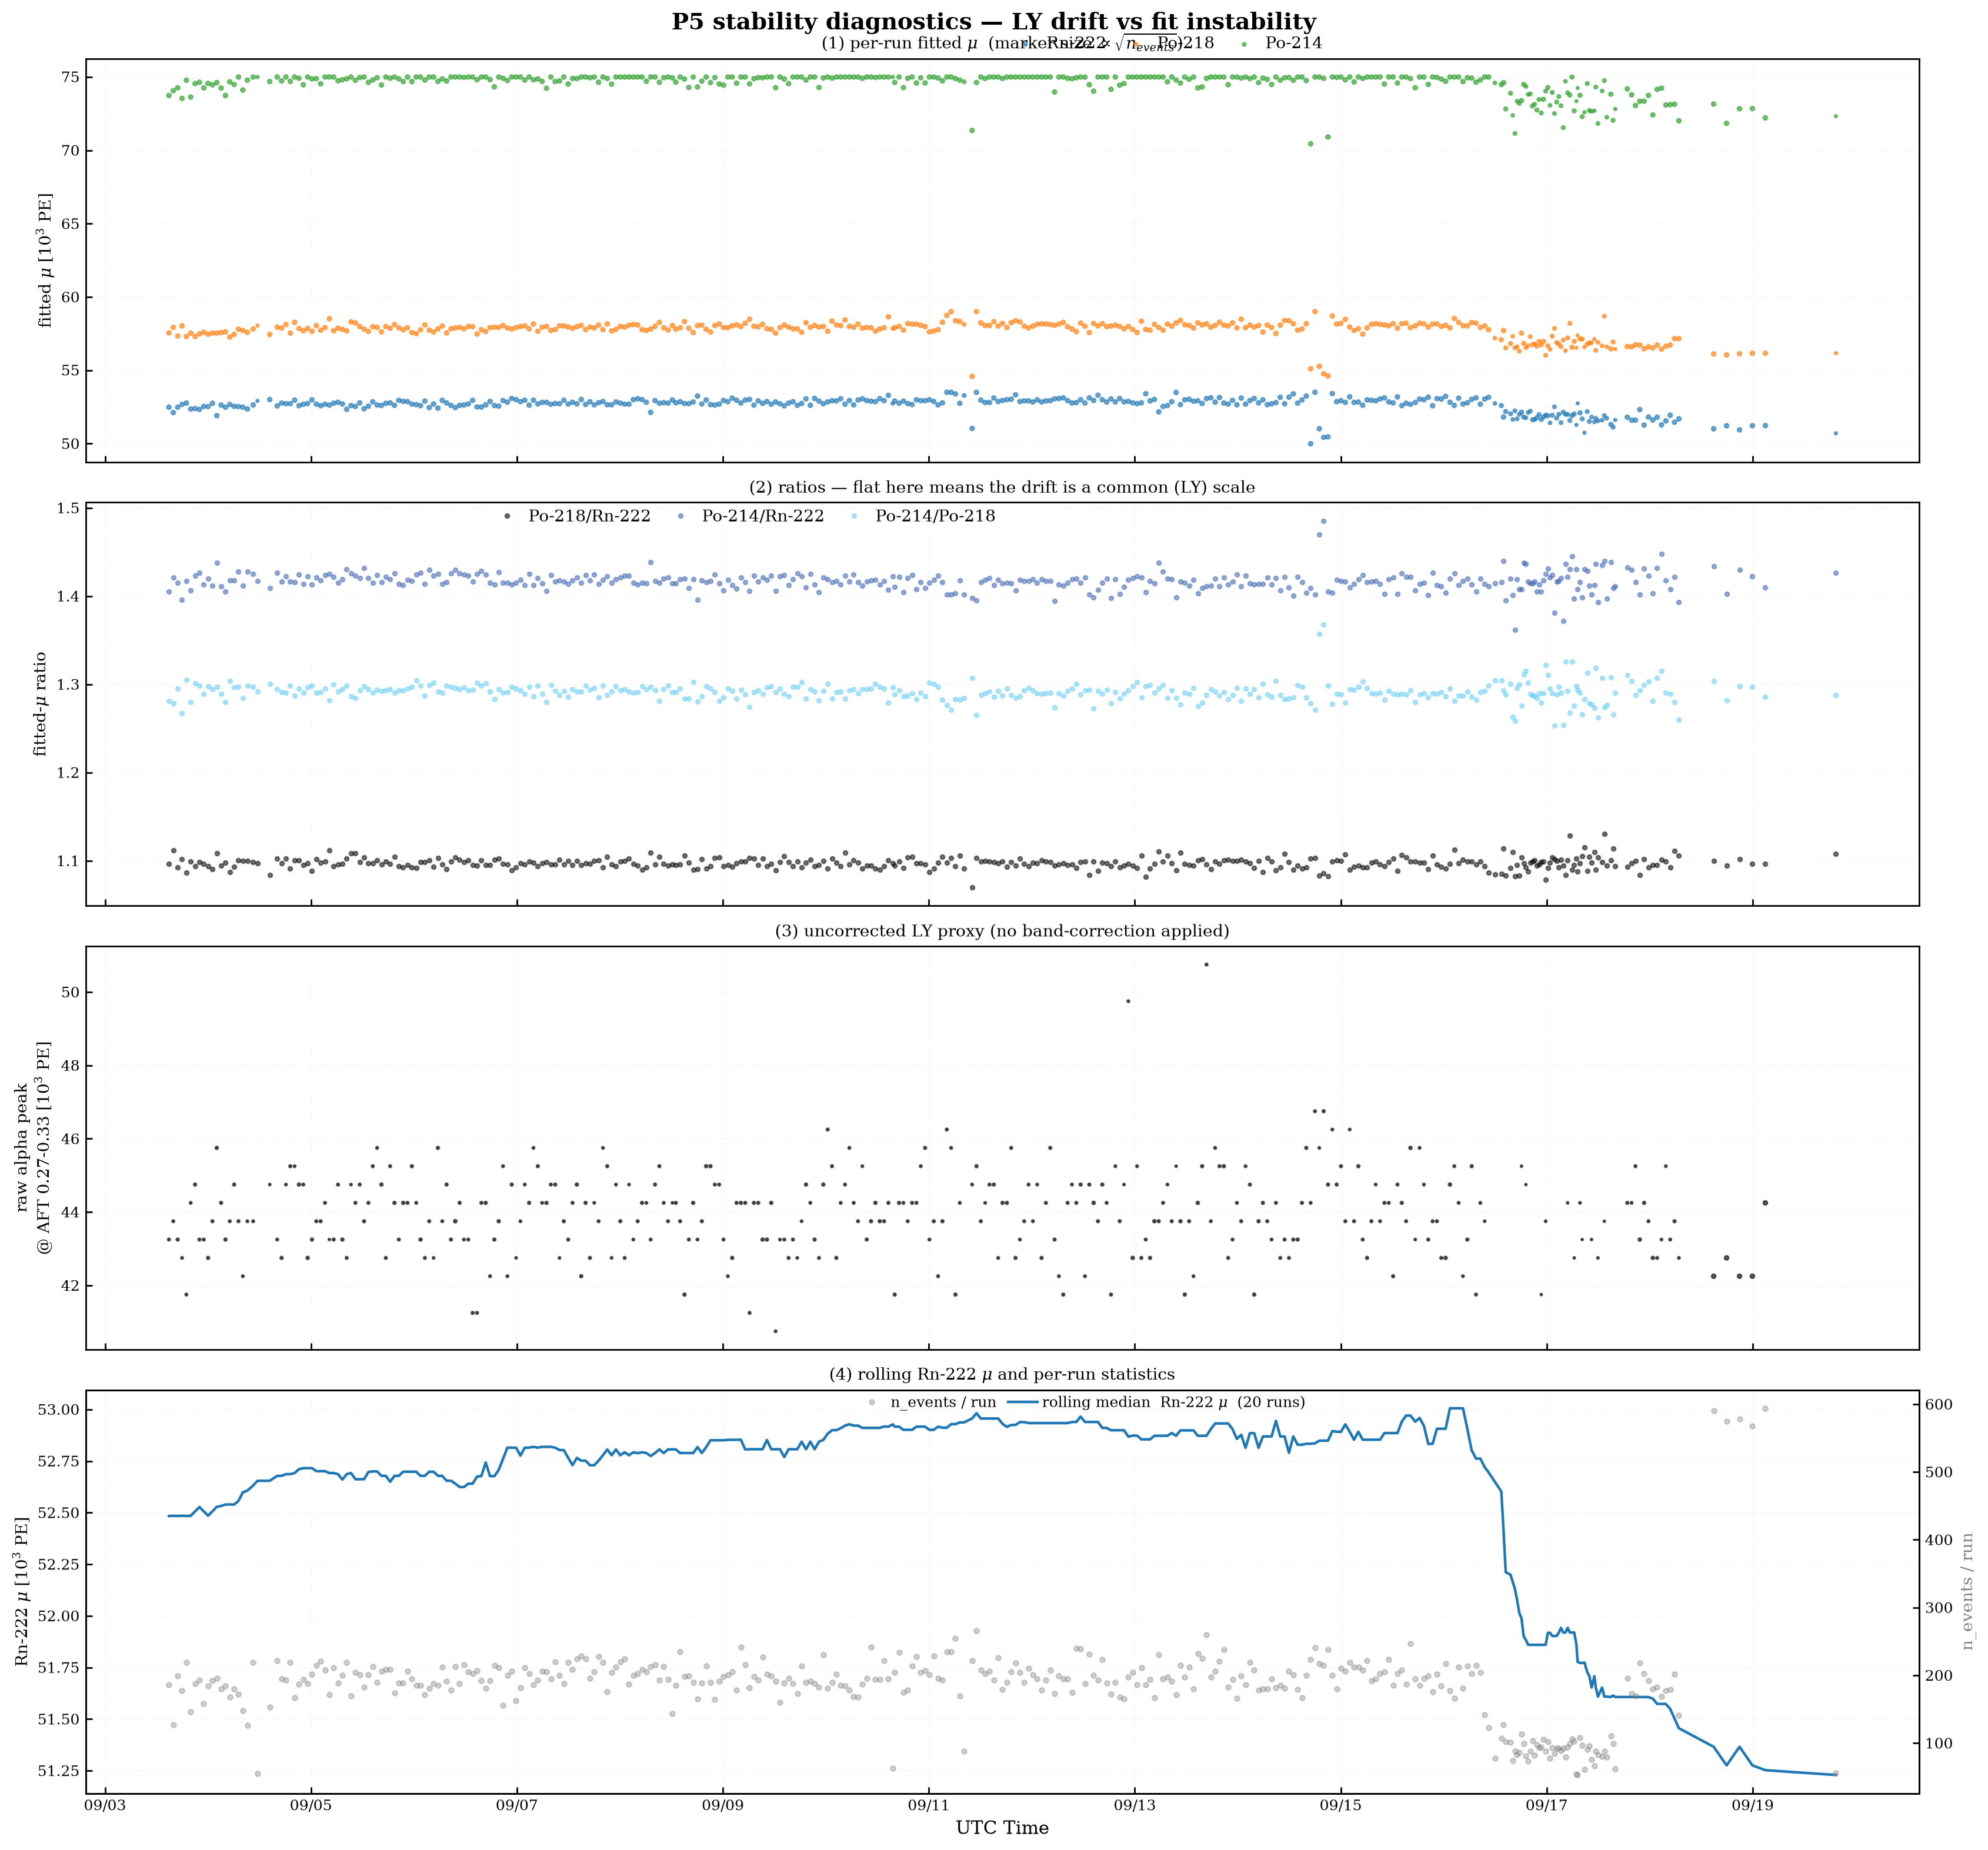

candidate breakpoints (|delta rolling median Rn-222 mu| > 1%):
   (none above 1%)

fitted-mu summary (per-run, all runs):
  Rn-222  mean=52598 PE   std=561 (1.07%)   n=372
  Po-218  mean=57708 PE   std=647 (1.12%)   n=372
  Po-214  mean=74516 PE   std=808 (1.08%)   n=372
  raw LY proxy  first=43250  last=44250  (2.31% total drift)


In [158]:
# ═══════════════════════════════════════════════════════════════
# B1. P5 STABILITY DIAGNOSTICS  (standalone; not part of the workflow)
# ═══════════════════════════════════════════════════════════════
# Depends on: df_fits_all (Sec 9), df_peaks (Sec 1), runs_sr3 (Sec 7).
# Question: is the fitted-mu spread a real LY drift, or a fit/statistics issue?
#   (1) mu vs time, marker size ~ sqrt(n_events)
#   (2) fitted-mu ratios (a common LY drift cancels in the ratio)
#   (3) raw, uncorrected alpha peak position at fixed AFT = true LY proxy
#   (4) rolling median of Rn-222 mu + per-run n_events -> candidate breakpoints

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timezone

_ISO_COLORS = {'Rn-222': 'tab:blue', 'Po-218': 'tab:orange', 'Po-214': 'tab:green'}

# ---- per-run successful fits ----
d = df_fits_all[df_fits_all['success']].sort_values('start_s').copy().reset_index(drop=True)
d['dt'] = [datetime.fromtimestamp(s, tz=timezone.utc) for s in d['start_s']]

# ---- (2) fitted-mu ratios ----
for _a, _b, _c in [('Po-218', 'Rn-222', 'r_218_222'),
                   ('Po-214', 'Rn-222', 'r_214_222'),
                   ('Po-214', 'Po-218', 'r_214_218')]:
    d[_c] = d[f'fit_mu_{_a}'] / d[f'fit_mu_{_b}']

# ---- (3) raw uncorrected LY proxy: alpha peak position at fixed AFT ----
AFT_LO, AFT_HI = 0.27, 0.33
AREA_LO, AREA_HI = 30e3, 70e3
_ly = []
for _, run in runs_sr3.iterrows():
    t0 = int(run['start_s'] * 1e9)
    t1 = int(float(run['end'].timestamp()) * 1e9)
    e = df_peaks[(df_peaks['time'] >= t0) & (df_peaks['time'] < t1)]
    e = e[(e['area_fraction_top'] >= AFT_LO) & (e['area_fraction_top'] <= AFT_HI) &
          (e['area'] >= AREA_LO) & (e['area'] <= AREA_HI)]
    if len(e) < 30:
        continue
    h, edg = np.histogram(e['area'], bins=80, range=(AREA_LO, AREA_HI))
    ctr = 0.5 * (edg[:-1] + edg[1:])
    _ly.append({'start_s': run['start_s'], 'n': len(e), 'area_peak': ctr[np.argmax(h)]})
ly = pd.DataFrame(_ly)
if len(ly):
    ly = ly.sort_values('start_s').reset_index(drop=True)
    ly['dt'] = [datetime.fromtimestamp(s, tz=timezone.utc) for s in ly['start_s']]

# ---- (4) rolling median of Rn-222 mu ----
rn = (d[['start_s', 'fit_mu_Rn-222', 'n_events']].dropna()
        .sort_values('start_s').reset_index(drop=True))
rn['roll'] = rn['fit_mu_Rn-222'].rolling(20, center=True, min_periods=8).median()
rn['dt'] = [datetime.fromtimestamp(s, tz=timezone.utc) for s in rn['start_s']]
rn['droll'] = rn['roll'].diff().abs() / rn['roll'].median()

# ---------------- plot ----------------
fig, axes = plt.subplots(4, 1, figsize=(17, 16), sharex=True)

# (1) mu per isotope
for name in SIGNAL_NAMES:
    col = f'fit_mu_{name}'
    if col not in d.columns:
        continue
    dp = d.dropna(subset=[col])
    axes[0].scatter(np.array(dp['dt']), dp[col] / 1e3,
                    s=np.clip(dp['n_events'] / 5.0, 1, 25),
                    color=_ISO_COLORS.get(name), alpha=0.6, label=name)
axes[0].set_ylabel('fitted $\\mu$ [10$^3$ PE]', fontsize=10)
axes[0].legend(fontsize=10, ncol=3, loc='best')
axes[0].set_title('(1) per-run fitted $\\mu$  (marker size $\\propto\\sqrt{n_{events}}$)', fontsize=10)

# (2) ratios
for _c, _lab in [('r_218_222', 'Po-218/Rn-222'),
                 ('r_214_222', 'Po-214/Rn-222'),
                 ('r_214_218', 'Po-214/Po-218')]:
    dp = d.dropna(subset=[_c])
    axes[1].plot(np.array(dp['dt']), dp[_c], 'o', ms=2.5, alpha=0.5, label=_lab)
axes[1].set_ylabel('fitted-$\\mu$ ratio', fontsize=10)
axes[1].legend(fontsize=10, ncol=3, loc='best')
axes[1].set_title('(2) ratios — flat here means the drift is a common (LY) scale', fontsize=10)

# (3) raw LY proxy
if len(ly):
    axes[2].scatter(np.array(ly['dt']), ly['area_peak'] / 1e3,
                    s=np.clip(ly['n'] / 5.0, 1, 25), color='k', alpha=0.6)
axes[2].set_ylabel('raw alpha peak\n@ AFT 0.27-0.33 [10$^3$ PE]', fontsize=10)
axes[2].set_title('(3) uncorrected LY proxy (no band-correction applied)', fontsize=10)

# (4) rolling mu + n_events
axes[3].plot(np.array(rn['dt']), rn['roll'] / 1e3, '-', color='tab:blue',
             lw=1.6, label='rolling median  Rn-222 $\\mu$  (20 runs)')
axes[3].set_ylabel('Rn-222 $\\mu$ [10$^3$ PE]', fontsize=10)
ax_r = axes[3].twinx()
ax_r.plot(np.array(d['dt']), d['n_events'], 'o', ms=3, color='gray', alpha=0.35,
          label='n_events / run')
ax_r.set_ylabel('n_events / run', fontsize=10, color='gray')
axes[3].legend(fontsize=9, loc='upper left')
ax_r.legend(fontsize=9, loc='upper right')
axes[3].set_title('(4) rolling Rn-222 $\\mu$ and per-run statistics', fontsize=10)

for ax in axes:
    ax.grid(True, alpha=0.2)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('P5 stability diagnostics — LY drift vs fit instability',
             fontsize=14, fontweight='bold')
safe_tight(fig)
plt.show()

# ---- candidate breakpoints: |delta rolling median| > 1% ----
_bp = rn.loc[rn['droll'] > 0.01, ['dt', 'roll', 'droll']]
print('candidate breakpoints (|delta rolling median Rn-222 mu| > 1%):')
if len(_bp):
    for _, r in _bp.iterrows():
        print('   %s   mu=%.0f PE   step=%.2f%%' %
              (r['dt'].strftime('%Y-%m-%d %H:%M'), r['roll'], 100 * r['droll']))
else:
    print('   (none above 1%)')

# ---- summary numbers ----
print()
print('fitted-mu summary (per-run, all runs):')
for name in SIGNAL_NAMES:
    col = f'fit_mu_{name}'
    if col not in d.columns:
        continue
    v = d[col].dropna()
    print('  %-7s mean=%.0f PE   std=%.0f (%.2f%%)   n=%d' %
          (name, v.mean(), v.std(), 100 * v.std() / v.mean(), len(v)))
if len(ly):
    v = ly['area_peak']
    print('  raw LY proxy  first=%.0f  last=%.0f  (%.2f%% total drift)' %
          (v.iloc[0], v.iloc[-1], 100 * (v.iloc[-1] - v.iloc[0]) / v.iloc[0]))


### B2. Commissioning operations 07/15–09/03 (for colleagues)

Detector operations extracted from the weekly commissioning meetings. Dates are LNGS
local (~UTC+2). Vertical lines for these events are only drawn on the backup trend plot
below — **not** in the main workflow.

| Date | Operation |
|------|-----------|
| 07/14–07/23 | Electrode HV ramp-up + hotspots (cathode −17→−22.5 kV; discharge/light emission at PMT 493/488) |
| **07/24** | Electrode HV test done, stable cathode −22.5 kV / top stack 6.5 kV; TPC Kr-83m + Th-232 calibration |
| 07/27–07/30 | Accumulator commissioning; new LXe level control; setpoint drifts ~−1 mm/day (online Kr offgas) |
| 07/31 | PMTs back ON |
| **08/04** | LNGS UPS test → TPC electrodes OFF all day; cooling → LN2; LXe level affected |
| 08/05 | New SR3 HV settings: cathode −22.0 kV, drift ~0.13 kV/cm, top stack 7.4 kV |
| 08/05–08/13 | PMT HV/gain scans (high/low gain, SR1/2) + Th-232 calibrations; FSR HV scan 2.9–3.6 kV |
| 08/07 | nVeto hitlet arrival-time irregularity |
| **08/08** | LXe level instabilities; PTR102 failure → LN2 → PTR101; Bell P 1.96→1.99 bar, T −95.7→−95.4 °C |
| 08/13–08/20 | PMT background rate ~3×; DAQ data rate ~3× |
| 08/20–08/27 | Electrode HV scanned to minimize TPC rate (lone-S1 study) |
| 08/31 | Online Kr distillation stopped (level regulation changes) |
| **09/01–09/02** | PTR102 retested + motor valve changed; LXe level sudden changes (accumulator under investigation) |
| 09/03 | Electrode + PMT HV finalized for SR3 |

**Bold rows** coincide with the partition boundaries of P5a–P5e.


/scratch/local/jobs/62007437/ipykernel_2989757/2144198239.py:26: UserWarning: The figure layout has changed to tight
  try: (fig or plt).tight_layout()


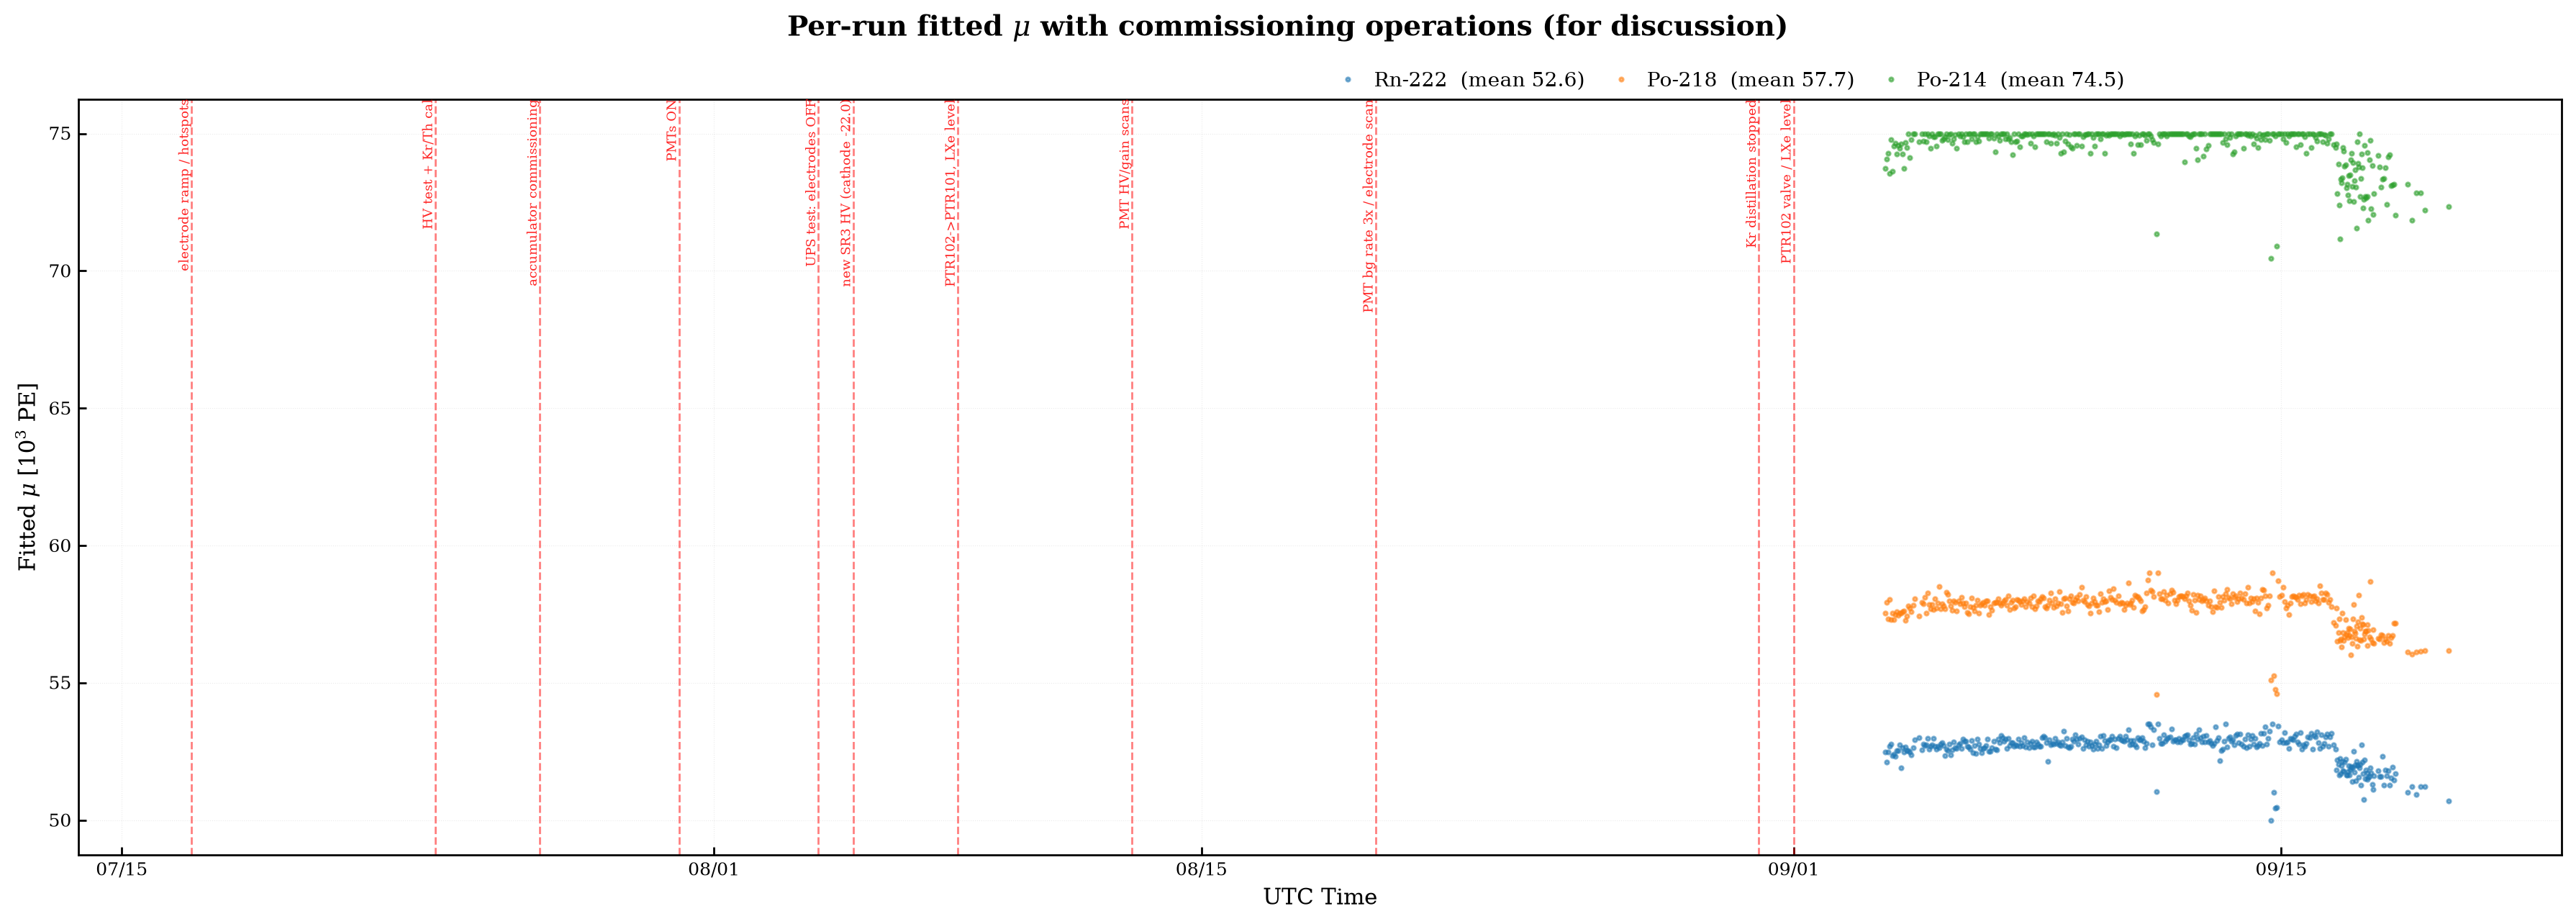

In [159]:
# ═══════════════════════════════════════════════════════════════
# B2. Per-run fitted-mu trend with commissioning operations (for colleagues)
# ═══════════════════════════════════════════════════════════════
# Vertical lines = detector operations from the weekly commissioning meetings
# (dates are LNGS local, ~UTC+2). Discussion aid only; not part of the workflow.

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timezone

_EVENTS = [
    ('2026-07-17', 'electrode ramp / hotspots'),
    ('2026-07-24', 'HV test + Kr/Th cal'),
    ('2026-07-27', 'accumulator commissioning'),
    ('2026-07-31', 'PMTs ON'),
    ('2026-08-04', 'UPS test: electrodes OFF'),
    ('2026-08-05', 'new SR3 HV (cathode -22.0)'),
    ('2026-08-08', 'PTR102->PTR101, LXe level'),
    ('2026-08-13', 'PMT HV/gain scans'),
    ('2026-08-20', 'PMT bg rate 3x / electrode scan'),
    ('2026-08-31', 'Kr distillation stopped'),
    ('2026-09-01', 'PTR102 valve / LXe level'),
]
_COLORS = {'Rn-222': 'tab:blue', 'Po-218': 'tab:orange', 'Po-214': 'tab:green'}

_d = df_fits_all[df_fits_all['success']].sort_values('start_s')
fig, ax = plt.subplots(figsize=(18, 6.5))
for name in SIGNAL_NAMES:
    col = f'fit_mu_{name}'
    if col not in _d.columns:
        continue
    dp = _d.dropna(subset=[col])
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in dp['start_s']]
    ax.plot(np.array(sd), dp[col].values / 1e3, 'o', ms=2, alpha=0.55,
            color=_COLORS.get(name), label=f'{name}  (mean {dp[col].mean()/1e3:.1f})')

# partition boundaries (black, solid)
for _name, _t0, _t1 in PARTITIONS[1:]:
    _dt = datetime.fromtimestamp(_t0, tz=timezone.utc)
    ax.axvline(x=_dt, color='black', ls='-', lw=1.0, alpha=0.3)

# operational events (red, dashed)
_, _yhi = ax.get_ylim()
for _dstr, _lab in _EVENTS:
    _dt = datetime.strptime(_dstr, '%Y-%m-%d').replace(tzinfo=timezone.utc)
    ax.axvline(x=_dt, color='red', ls='--', lw=1.0, alpha=0.5)
    ax.text(_dt, _yhi, _lab, fontsize=6.5, color='red', rotation=90,
            va='top', ha='right', alpha=0.85)

ax.set_ylabel('Fitted $\\mu$ [10$^3$ PE]', fontsize=11)
ax.set_xlabel('UTC Time', fontsize=11)
ax.legend(fontsize=10, loc='best', ncol=3)
ax.grid(True, alpha=0.2)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Per-run fitted $\\mu$ with commissioning operations (for discussion)',
             fontsize=14, fontweight='bold')
safe_tight(fig)
plt.show()
